# If we only know the hourly price, how much can we know about what happens inside the hour?

**EDA for the AET Neural Wave 2026 hackathon challenge**

Since 1 October 2025 the European day-ahead electricity market sets a price for every **15 minutes** instead of every hour. Most historical data, forecasts and long-term curves, however, exist only as **hourly** prices. For each of 4 anonymised market zones we are given a day's **24 hourly prices** and must rebuild the **96 quarter-hour prices** behind them, so that the 4 quarters of each hour average *exactly* to the given hourly price. Results are scored by the mean absolute error (MAE) of the 15-minute prices; the benchmark is the **flat guess** (the hourly price repeated 4 times).

This notebook answers the question in the title, one step at a time. Each chapter answers one question and ends with the question the next chapter picks up (→).

| Chapter | Finding |
|---|---|
| 0 | **The numbers first:** means, medians, tails, extremes; prices and residuals are heavy-tailed, not Gaussian |
| 1 | **The hourly price hides a lot:** the flat guess is off by ≈ 7.3 EUR/MWh |
| 2 | **Prices slide toward the next hour:** a sawtooth inside every hour |
| 3 | **The slope between hours explains most of it:** a rule with no training cuts the error by ≈ 39% |
| 4 | **Where the simple rule breaks:** season, weekends, zones, day edges, negative prices |
| 5 | **Extra clues fill the gaps:** the day's price spread and recent history |
| 6 | **The past is a guide, but recent past is better:** validate by time |
| 7 | **What we'll build:** a model ladder, each step motivated by a chapter |
| A–D | Appendices: data checks, the price level in detail, more examples, more shape details |

**The thread to follow:** 7.30 → 4.45 EUR/MWh (flat guess → slope rule), stated in chapter 1, earned in chapter 3, built on in chapter 7.

**Basics**
- **Units:** EUR/MWh. 100 EUR/MWh = €0.10 per kWh. Prices can be negative when supply (mostly solar) exceeds demand.
- **Residual** = 15-min price − hourly price. The 4 residuals of an hour sum to zero, so the task is to predict the *shape*, not the level.
- **Data:** 1 Oct 2025 – 30 Sep 2026, 363 days per zone (the two daylight-saving Sundays are excluded). Only `Data/train_prices_15min.csv` is used, no external data.
- **Holdout:** all statistics and plots stop on **31 Aug 2026**; September stays untouched for the final model check.
- **Zone names:** the file uses `ZONE_0`–`ZONE_3`; here they are **Zone 1–Zone 4** (`ZONE_0` = Zone 1, …). The submission keeps the original ids.
- Numbers quoted in the text come from running this notebook on the official file. If the data or code changes, rerun and update them.

# Setup
Locate the repo root, import libraries, define shared constants and helpers.

In [19]:
# ---------------------------------------------------------------------------
# Setup: paths, libraries, plotting style, shared constants
# ---------------------------------------------------------------------------
from pathlib import Path

# Walk up from the current folder until we find the repo root (it contains Data/)
root = Path.cwd().resolve()
while not (root / 'Data' / 'train_prices_15min.csv').exists():
    if root.parent == root:
        raise FileNotFoundError('Run this notebook from inside the repo')
    root = root.parent

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 3)

DATA = root / 'Data' / 'train_prices_15min.csv'       # the only data we are allowed to use
EDA_END = pd.Timestamp('2026-08-31')                  # September = untouched holdout

ZONE_NAMES = {f'ZONE_{i}': f'Zone {i + 1}' for i in range(4)}   # ZONE_0 → Zone 1, …
ZONES = list(ZONE_NAMES.values())
COLORS = ['#2864a0', '#e68a2e', '#258a70', '#9258a5']           # one colour per zone
Q_COLORS = ['#c6dbef', '#6baed6', '#2171b5', '#08306b']         # quarters Q1 → Q4

SEASON_OF_MONTH = {12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring',
                   6: 'summer', 7: 'summer', 8: 'summer', 9: 'autumn', 10: 'autumn', 11: 'autumn'}
SEASONS = ['autumn', 'winter', 'spring', 'summer']               # chronological in our data
SEASON_COLORS = {'autumn': '#9258a5', 'winter': '#2864a0', 'spring': '#258a70', 'summer': '#e68a2e'}

HOUR = ['delivery_date', 'market_id', 'hour_index']   # keys of one hour
KEYS = HOUR + ['quarter_index']                       # keys of one quarter
R_COLS = ['r1', 'r2', 'r3', 'r4']                     # residuals of Q1..Q4
OFFSETS = np.array([-0.375, -0.125, 0.125, 0.375])    # quarter centres vs hour centre (hours)


def official_mae(frame, err_col):
    # Official averaging: MAE per (day, zone) -> mean over days per zone
    per_day = frame.groupby(['market_id', 'delivery_date'])[err_col].mean()
    return per_day.groupby('market_id').mean()

# Sanity Check

In [20]:
# 1a. Structural checks on the full file (no price statistics here)

full = pd.read_csv(DATA, parse_dates=['delivery_date'])   # read CSV, parse dates as datetimes
assert set(full.market_id) == set(ZONE_NAMES), 'unexpected zone ids in the file'
full['market_id'] = full.market_id.map(ZONE_NAMES)        # ZONE_0 → Zone 1, …, ZONE_3 → Zone 4

n_days = full.delivery_date.nunique()                     # number of distinct delivery dates
print(f'Rows: {len(full):,}  (expected 363 days × 4 zones × 96 quarters = {363 * 4 * 96:,})')
print(f'Distinct dates: {n_days}, zones: {sorted(full.market_id.unique())}')
print(f'Missing values: {full.isna().sum().sum()}')                 # any empty cell anywhere
print(f'Duplicate keys: {full.duplicated(KEYS).sum()}')             # same date/zone/hour/quarter twice
print(f'Non-finite prices: {(~np.isfinite(full.price_eur_mwh)).sum()}')  # inf / -inf

# Every (date, zone) should have exactly 24 hours × 4 quarters = 96 rows
rows_per_day = full.groupby(['delivery_date', 'market_id']).size()
print(f'Day/zone combos with != 96 rows: {(rows_per_day != 96).sum()}')
print(f'hour_index range: {full.hour_index.min()}–{full.hour_index.max()}, '
      f'quarter_index range: {full.quarter_index.min()}–{full.quarter_index.max()}')

# Compare against a complete calendar to find which dates are absent
all_days = pd.date_range(full.delivery_date.min(), full.delivery_date.max())
missing = all_days.difference(full.delivery_date.unique())
print('Missing dates:', [f'{d:%Y-%m-%d} ({d:%A})' for d in missing])

Rows: 139,392  (expected 363 days × 4 zones × 96 quarters = 139,392)
Distinct dates: 363, zones: ['Zone 1', 'Zone 2', 'Zone 3', 'Zone 4']
Missing values: 0
Duplicate keys: 0
Non-finite prices: 0
Day/zone combos with != 96 rows: 0
hour_index range: 1–24, quarter_index range: 1–4
Missing dates: ['2025-10-26 (Sunday)', '2026-03-29 (Sunday)']


# Preparing the data
One quarter-level table (`df`) and one hour-level table (`H`, one row per date × zone × hour with the 4 residuals side by side). The data checks behind this step (row counts, missing dates, duplicates, extreme values) are in **Appendix A**; in short, the file is clean and the only missing dates are the two daylight-saving Sundays.

In [21]:
# ---------------------------------------------------------------------------
# Load, rename zones, keep the EDA window, build residuals
# ---------------------------------------------------------------------------
full = pd.read_csv(DATA, parse_dates=['delivery_date'])
assert set(full.market_id) == set(ZONE_NAMES), 'unexpected zone ids in the file'
full['market_id'] = full.market_id.map(ZONE_NAMES)
full = full.sort_values(KEYS).reset_index(drop=True)

df = full[full.delivery_date <= EDA_END].copy()                      # EDA window only
df['hourly_price'] = df.groupby(HOUR).price_eur_mwh.transform('mean')  # what the jury gives us
df['residual'] = df.price_eur_mwh - df.hourly_price                   # what we predict
df['abs_res'] = df.residual.abs()                                     # = flat-guess error
df['is_neg'] = df.price_eur_mwh < 0
df['weekday'] = df.delivery_date.dt.dayofweek                         # 0 = Monday
df['day_type'] = np.where(df.weekday >= 5, 'weekend', 'weekday')
df['season'] = df.delivery_date.dt.month.map(SEASON_OF_MONTH)
df['month'] = df.delivery_date.dt.to_period('M').astype(str)
df['qod'] = (df.hour_index - 1) * 4 + df.quarter_index                # quarter of day 1..96

# Hour-level table H: residuals r1..r4 side by side + hour attributes
H = df.pivot_table(index=HOUR, columns='quarter_index', values='residual').add_prefix('r').reset_index()
H.columns.name = None
H = H.merge(df.groupby(HOUR).agg(hourly_price=('hourly_price', 'first'),
                                 day_type=('day_type', 'first'),
                                 season=('season', 'first'),
                                 month=('month', 'first'),
                                 n_neg=('is_neg', 'sum')).reset_index(), on=HOUR)
H = H.sort_values(HOUR).reset_index(drop=True)

day_prices = H.groupby(['delivery_date', 'market_id']).hourly_price
H['prev_hour'] = day_prices.shift(1)              # hour 1 has no previous hour within the day
H['next_hour'] = day_prices.shift(-1)             # hour 24 has no next hour (next day not given)
H['slope'] = H.next_hour - H.prev_hour            # direction of the ramp around this hour
H['q4_minus_q1'] = H.r4 - H.r1                    # tilt inside the hour: > 0 rising
# Half the two-sided slope; at the day edges fall back to the one-sided step
H['slope_c'] = (H.slope / 2).fillna(H.next_hour - H.hourly_price).fillna(H.hourly_price - H.prev_hour)
H['abs_res'] = H[R_COLS].abs().mean(axis=1)       # flat-guess error of this hour (= intra-hour movement)
H['range'] = H[R_COLS].max(axis=1) - H[R_COLS].min(axis=1)
H['day_spread'] = day_prices.transform('max') - day_prices.transform('min')   # known at inference

R = H[R_COLS].to_numpy()                          # actual residuals, shape (n_hours, 4)
print(f'{len(df):,} quarters, {len(H):,} hours, {df.delivery_date.nunique()} days '
      f'({df.delivery_date.min():%d %b %Y} – {df.delivery_date.max():%d %b %Y})')

127,872 quarters, 31,968 hours, 333 days (01 Oct 2025 – 31 Aug 2026)


In [22]:
# ---------------------------------------------------------------------------
# Peek at the data: first 4 hours and last 4 hours
# ---------------------------------------------------------------------------
SHOW = ['delivery_date', 'market_id', 'hour_index', 'quarter_index',
        'price_eur_mwh', 'hourly_price', 'residual']

print('First 4 hours (15-min prices with their hourly average):')
display(df[SHOW].head(16))

print('Last 4 hours:')
display(df[SHOW].tail(16))

# Row counts
# 
print(f'full (whole file, 15-min):        {len(full):,} rows')
print(f'df   (Oct–Aug, 15-min + hourly):  {len(df):,} rows')
print(f'H    (Oct–Aug, one row per hour): {len(H):,} rows')

print('\nRows per zone in df:')
display(df.groupby('market_id').size().rename('rows').to_frame())

First 4 hours (15-min prices with their hourly average):


,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh,hourly_price,residual
0,2025-10-01,Zone 1,1,1,102.60,91.565,11.035
1,2025-10-01,Zone 1,1,2,92.24,91.565,0.675
2,2025-10-01,Zone 1,1,3,86.03,91.565,-5.535
3,2025-10-01,Zone 1,1,4,85.39,91.565,-6.175
4,2025-10-01,Zone 1,2,1,89.99,86.285,3.705
5,2025-10-01,Zone 1,2,2,86.03,86.285,-0.255
6,2025-10-01,Zone 1,2,3,85.03,86.285,-1.255
7,2025-10-01,Zone 1,2,4,84.09,86.285,-2.195
8,2025-10-01,Zone 1,3,1,85.41,84.873,0.537
9,2025-10-01,Zone 1,3,2,85.00,84.873,0.127


Last 4 hours:


,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh,hourly_price,residual
127856,2026-08-31,Zone 4,21,1,184.27,193.515,-9.245
127857,2026-08-31,Zone 4,21,2,195.80,193.515,2.285
127858,2026-08-31,Zone 4,21,3,200.81,193.515,7.295
127859,2026-08-31,Zone 4,21,4,193.18,193.515,-0.335
127860,2026-08-31,Zone 4,22,1,209.87,185.235,24.635
127861,2026-08-31,Zone 4,22,2,185.51,185.235,0.275
127862,2026-08-31,Zone 4,22,3,179.32,185.235,-5.915
127863,2026-08-31,Zone 4,22,4,166.24,185.235,-18.995
127864,2026-08-31,Zone 4,23,1,180.30,174.350,5.950
127865,2026-08-31,Zone 4,23,2,173.36,174.350,-0.990


full (whole file, 15-min):        139,392 rows
df   (Oct–Aug, 15-min + hourly):  127,872 rows
H    (Oct–Aug, one row per hour): 31,968 rows

Rows per zone in df:


,rows
market_id,
Zone 1,31968
Zone 2,31968
Zone 3,31968
Zone 4,31968


In [23]:
# ---------------------------------------------------------------------------
# Sneak peek: the same 4 hours in df (one row per quarter) and H (one row per hour)
# ---------------------------------------------------------------------------
PEEK_DATE, PEEK_ZONE, PEEK_HOURS = pd.Timestamp('2026-06-15'), 'Zone 1', [8, 9, 10, 11]

print(f'df: {PEEK_ZONE}, {PEEK_DATE:%d %b %Y}, hours {PEEK_HOURS[0]}–{PEEK_HOURS[-1]}  (4 rows per hour)')
display(df.loc[(df.delivery_date == PEEK_DATE) & (df.market_id == PEEK_ZONE) & df.hour_index.isin(PEEK_HOURS),
               ['delivery_date', 'market_id', 'hour_index', 'quarter_index',
                'price_eur_mwh', 'hourly_price', 'residual', 'day_type', 'season']])

print(f'H: the same hours  (1 row per hour, the 4 residuals side by side)')
display(H.loc[(H.delivery_date == PEEK_DATE) & (H.market_id == PEEK_ZONE) & H.hour_index.isin(PEEK_HOURS),
              ['delivery_date', 'market_id', 'hour_index', 'hourly_price', 'r1', 'r2', 'r3', 'r4',
               'prev_hour', 'next_hour', 'slope', 'q4_minus_q1', 'day_spread']].round(2))

df: Zone 1, 15 Jun 2026, hours 8–11  (4 rows per hour)


,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh,hourly_price,residual,day_type,season
97948,2026-06-15,Zone 1,8,1,121.73,107.392,14.338,weekday,summer
97949,2026-06-15,Zone 1,8,2,108.93,107.392,1.538,weekday,summer
97950,2026-06-15,Zone 1,8,3,104.85,107.392,-2.543,weekday,summer
97951,2026-06-15,Zone 1,8,4,94.06,107.392,-13.332,weekday,summer
97952,2026-06-15,Zone 1,9,1,108.33,91.440,16.890,weekday,summer
97953,2026-06-15,Zone 1,9,2,100.99,91.440,9.550,weekday,summer
97954,2026-06-15,Zone 1,9,3,88.37,91.440,-3.070,weekday,summer
97955,2026-06-15,Zone 1,9,4,68.07,91.440,-23.370,weekday,summer
97956,2026-06-15,Zone 1,10,1,95.75,63.652,32.098,weekday,summer
97957,2026-06-15,Zone 1,10,2,76.94,63.652,13.288,weekday,summer


H: the same hours  (1 row per hour, the 4 residuals side by side)


,delivery_date,market_id,hour_index,hourly_price,r1,r2,r3,r4,prev_hour,next_hour,slope,q4_minus_q1,day_spread
24487,2026-06-15,Zone 1,8,107.39,14.34,1.54,-2.54,-13.33,105.69,91.44,-14.25,-27.67,159.16
24488,2026-06-15,Zone 1,9,91.44,16.89,9.55,-3.07,-23.37,107.39,63.65,-43.74,-40.26,159.16
24489,2026-06-15,Zone 1,10,63.65,32.10,13.29,-8.28,-37.10,91.44,21.56,-69.88,-69.20,159.16
24490,2026-06-15,Zone 1,11,21.56,30.73,2.58,-11.86,-21.46,63.65,1.01,-62.64,-52.19,159.16


---
# 0. The numbers first: descriptive statistics and distributions

Before looking at shapes, a plain statistical description of what is in the file: central values (mean, median), spread (standard deviation, IQR), tails (percentiles, skewness, kurtosis) and extremes. We then check **which probability distribution fits the prices and the residuals**, starting with a Gaussian (normal) curve, since that tells us which statistics and which loss function are trustworthy.

All numbers use the EDA window (Oct 2025 – Aug 2026).

In [ ]:
# 0a. Descriptive statistics of the 15-min prices, per zone

from scipy import stats

def describe(s):
    """Location, spread, tail and extreme statistics of one series."""
    q = s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    return pd.Series({
        'count': len(s),
        'mean': s.mean(), 'median': q[0.5],
        'std': s.std(), 'IQR': q[0.75] - q[0.25],                  # spread: classic vs robust
        'MAD': (s - q[0.5]).abs().median(),                        # median absolute deviation (robust)
        'skewness': s.skew(),                                      # 0 = symmetric, > 0 = long right tail
        'excess_kurtosis': s.kurt(),                               # 0 = Gaussian tails, > 0 = heavier tails
        'min': s.min(), 'p1': q[0.01], 'p5': q[0.05], 'p25': q[0.25],
        'p75': q[0.75], 'p95': q[0.95], 'p99': q[0.99], 'max': s.max(),
        'negative_%': 100 * (s < 0).mean(),
    })

price_stats = df.groupby('market_id').price_eur_mwh.apply(describe).unstack()
print('15-min prices (EUR/MWh):')
display(price_stats.T.round(2))

15-min prices (EUR/MWh):


market_id,Zone 1,Zone 2,Zone 3,Zone 4
count,31968.00,31968.00,31968.00,31968.00
mean,100.78,114.96,132.23,70.76
median,102.48,117.67,131.14,74.67
std,59.21,56.79,37.19,55.82
IQR,53.39,50.65,42.63,85.86
MAD,27.14,25.30,21.14,42.77
skewness,0.11,-0.43,-0.18,-0.25
excess_kurtosis,10.99,10.35,2.01,4.71
min,-499.99,-498.65,0.00,-498.65
p1,-17.11,-11.90,12.25,-13.47


> **Business insights: the price level (0a)**
>
> **The four zones behave like four different markets, so one approach does not fit all.**
>
> - **Zone 3: expensive but predictable.** It has the highest average price (≈ 132 EUR/MWh) and the narrowest swings (std 37), it never went negative, and its highest quarter was only 313 EUR/MWh. Price risk is low; most of the value comes from the level, not from timing.
> - **Zone 4: cheap and solar-driven.** It has the lowest average price (≈ 71 EUR/MWh) and the widest everyday range (the middle 50% of quarters spans 86 EUR/MWh). In 1 out of every 4 quarters the price is below 22 EUR/MWh, and in 6.6% of quarters it is negative. For a flexible asset (pumped storage, batteries, flexible demand) this is where buying cheap, or even being paid to consume, is most frequent.
> - **Zones 1 and 2: spiky, with the biggest risk and the biggest opportunities.** Prices range from the −500 EUR/MWh market floor up to 747 (Zone 1) and 645 (Zone 2). Extreme quarters are about 10× more frequent than a "normal" bell-curve market would suggest (excess kurtosis ≈ 11). A handful of quarters can decide the value of a position, so these zones need the most careful risk management.
> - **Negative prices are not rare outside Zone 3:** 3–7% of all quarters, i.e. roughly 1 to 2 hours per day on average, concentrated around midday solar peaks (see Appendix A).
> - **Averages are reliable as a typical value** (mean ≈ median in every zone), but they hide the extremes, which go in both directions: deep negatives and sharp spikes.
>
> **Why this matters for 15-minute pricing:** the zones with the most extreme prices are also where quarter-hour detail is worth the most. A flat hourly profile smooths over exactly the moments when a flexible asset earns or loses the most money.

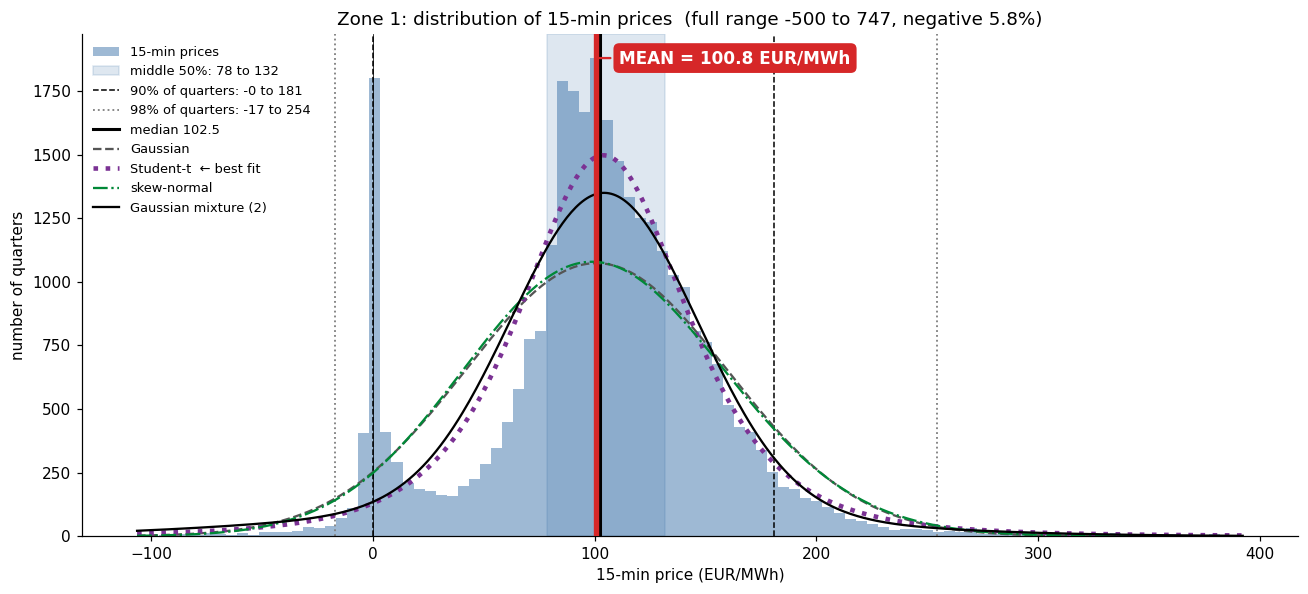

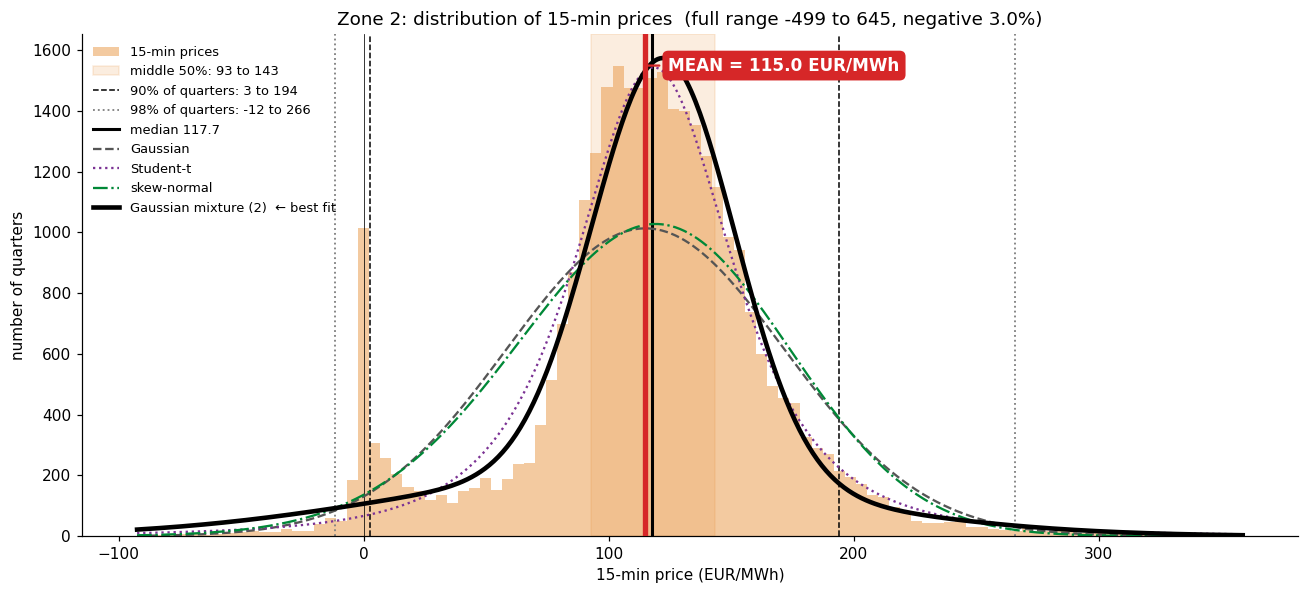

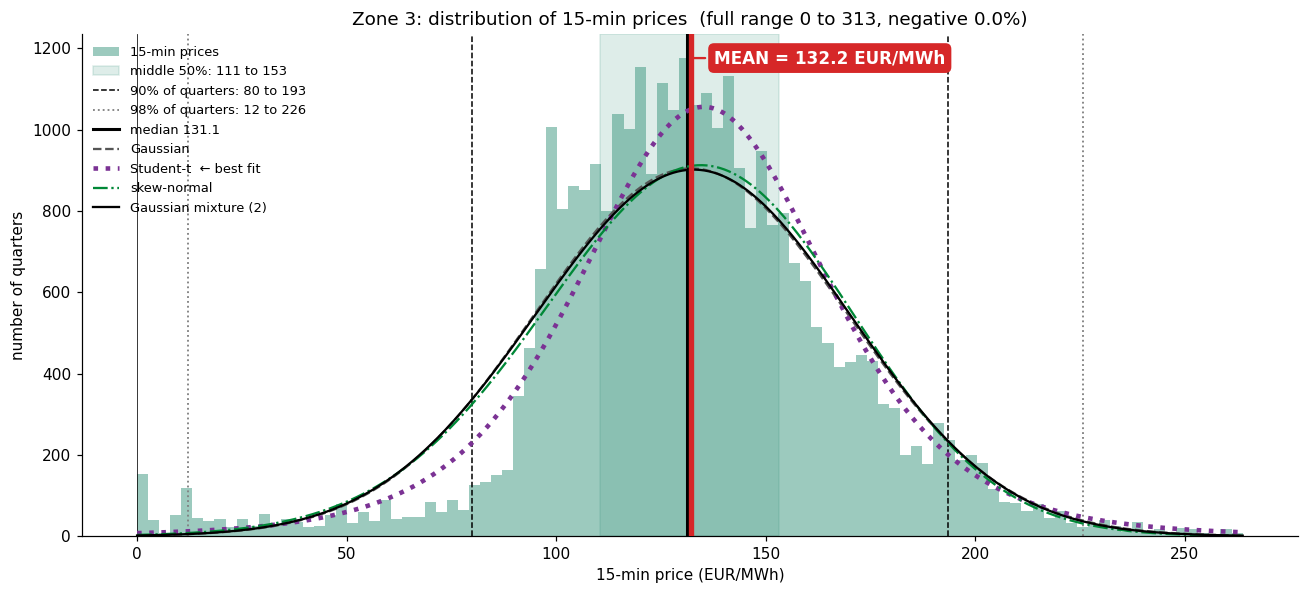

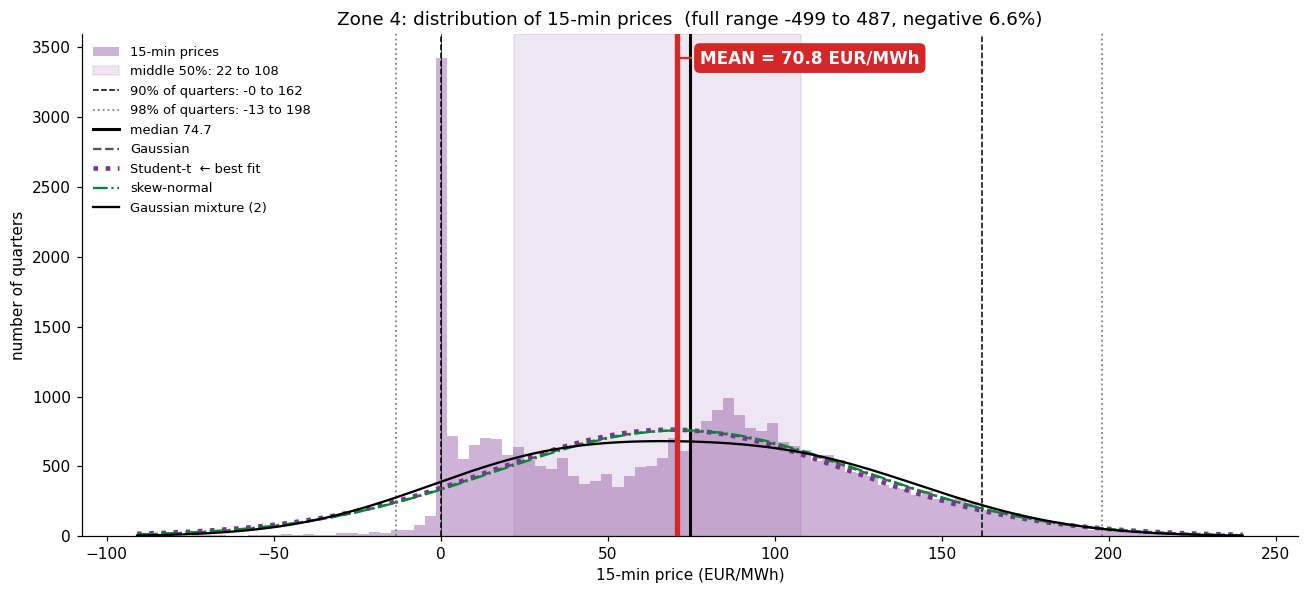

Fit quality per zone (AIC, lower = better):


market_id,Zone 1,Zone 2,Zone 3,Zone 4
distribution,,,,
Gaussian,351649.0,348989.0,321924.0,347882.0
Gaussian mixture (2),347014.0,341344.0,322027.0,348454.0
Student-t,345489.0,341751.0,319594.0,347127.0
skew-normal,351492.0,348551.0,321724.0,347814.0


In [31]:
# ---------------------------------------------------------------------------
# 0a (graph 1). Distribution of the 15-min prices, one figure per zone,
#               with the mean highlighted and the best-fitting distributions overlaid
# ---------------------------------------------------------------------------
from scipy import stats
from sklearn.mixture import GaussianMixture

FIT_STYLES = {'Gaussian': ('#555555', '--'), 'Student-t': ('#7b3294', ':'),
              'skew-normal': ('#008837', '-.'), 'Gaussian mixture (2)': ('#000000', '-')}


def fit_distributions(x):
    # Fit 4 candidate distributions to x; return {name: (pdf function, AIC)}. Lower AIC = better fit.
    fits = {}
    for name, dist in [('Gaussian', stats.norm), ('Student-t', stats.t), ('skew-normal', stats.skewnorm)]:
        params = dist.fit(x)
        aic = 2 * len(params) - 2 * dist.logpdf(x, *params).sum()
        fits[name] = (lambda g, d=dist, prm=params: d.pdf(g, *prm), aic)
    gm = GaussianMixture(2, random_state=0).fit(x.reshape(-1, 1))           # two price regimes
    w, mu, sd = gm.weights_, gm.means_.ravel(), np.sqrt(gm.covariances_.ravel())
    fits['Gaussian mixture (2)'] = (lambda g: sum(w[k] * stats.norm.pdf(g, mu[k], sd[k]) for k in range(2)),
                                    gm.aic(x.reshape(-1, 1)))
    return fits


fit_summary = []
for z, c in zip(ZONES, COLORS):
    s = df.loc[df.market_id == z, 'price_eur_mwh']
    x = s.to_numpy()
    p = s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    lo, hi = s.quantile([0.002, 0.998])                       # hide only the 0.4% most extreme for readability
    mean = s.mean()

    fig, ax = plt.subplots(figsize=(12, 5.5))
    counts, edges, _ = ax.hist(s[(s >= lo) & (s <= hi)], bins=100, color=c, alpha=0.45, label='15-min prices')
    bin_w = edges[1] - edges[0]

    # Percentile ranges and median
    ax.axvspan(p[0.25], p[0.75], color=c, alpha=0.15, label=f'middle 50%: {p[0.25]:.0f} to {p[0.75]:.0f}')
    ax.axvline(p[0.05], color='k', ls='--', lw=1, label=f'90% of quarters: {p[0.05]:.0f} to {p[0.95]:.0f}')
    ax.axvline(p[0.95], color='k', ls='--', lw=1)
    ax.axvline(p[0.01], color='grey', ls=':', lw=1.2, label=f'98% of quarters: {p[0.01]:.0f} to {p[0.99]:.0f}')
    ax.axvline(p[0.99], color='grey', ls=':', lw=1.2)
    ax.axvline(p[0.5], color='k', lw=2, label=f'median {p[0.5]:.1f}')
    ax.axvline(0, color='k', lw=0.5)

    # Fitted distributions, scaled from density to "number of quarters"; best AIC drawn thickest
    fits = fit_distributions(x)
    best = min(fits, key=lambda k: fits[k][1])
    grid = np.linspace(lo, hi, 500)
    for name, (pdf, aic) in fits.items():
        col, ls = FIT_STYLES[name]
        ax.plot(grid, pdf(grid) * len(x) * bin_w, color=col, ls=ls, lw=3 if name == best else 1.5,
                label=f'{name}{"  ← best fit" if name == best else ""}')
        fit_summary.append({'market_id': z, 'distribution': name, 'AIC': aic, 'best': name == best})

    # The mean: thick red line plus a labelled box at the top
    ax.axvline(mean, color='#d62728', lw=3.5, zorder=5)
    ax.annotate(f'MEAN = {mean:.1f} EUR/MWh', xy=(mean, counts.max()), xytext=(15, 0),
                textcoords='offset points', color='white', fontsize=11, fontweight='bold', va='center',
                bbox=dict(boxstyle='round,pad=0.35', fc='#d62728', ec='none'), zorder=6,
                arrowprops=dict(arrowstyle='-', color='#d62728', lw=1.5))

    ax.set(title=f'{z}: distribution of 15-min prices  '
                 f'(full range {s.min():.0f} to {s.max():.0f}, negative {100 * (s < 0).mean():.1f}%)',
           xlabel='15-min price (EUR/MWh)', ylabel='number of quarters')
    ax.legend(frameon=False, fontsize=8.5, loc='upper left')
    plt.tight_layout(); plt.show()

# Which distribution fits best? (AIC: lower = better; compare within a zone only)
print('Fit quality per zone (AIC, lower = better):')
pd.DataFrame(fit_summary).pivot(index='distribution', columns='market_id', values='AIC').round(0)

In [ ]:
# 0b. The same statistics for the residuals (what we actually predict)

res_stats = df.groupby('market_id').residual.apply(describe).unstack().drop(columns='negative_%')
print('Residuals = 15-min price − hourly price (EUR/MWh):')
display(res_stats.T.round(2))

# How much of the variation is "level" (hour to hour) vs "shape" (inside the hour)?
share = pd.DataFrame({
    'var_price': df.groupby('market_id').price_eur_mwh.var(),
    'var_hourly_level': df.groupby('market_id').hourly_price.var(),
    'var_residual': df.groupby('market_id').residual.var(),
})
share['% of variance inside the hour'] = 100 * share.var_residual / share.var_price
print('Variance split: total = hourly level + inside-the-hour residual')
share.round(1)

Residuals = 15-min price − hourly price (EUR/MWh):


market_id,Zone 1,Zone 2,Zone 3,Zone 4
count,31968.00,31968.00,31968.00,31968.00
mean,0.00,-0.00,0.00,-0.00
median,-0.03,-0.03,0.00,0.00
std,13.94,15.49,8.15,11.86
IQR,7.52,9.61,6.50,7.83
MAD,3.76,4.80,3.25,3.92
skewness,0.42,0.20,0.12,0.22
excess_kurtosis,24.94,14.64,6.47,14.89
min,-215.14,-191.48,-75.47,-191.70
p1,-42.17,-48.78,-23.19,-35.56


Variance split: total = hourly level + inside-the-hour residual


,var_price,var_hourly_level,var_residual,% of variance inside the hour
market_id,,,,
Zone 1,3505.4,3311.0,194.3,5.5
Zone 2,3225.5,2985.7,239.9,7.4
Zone 3,1383.3,1316.8,66.5,4.8
Zone 4,3115.7,2975.0,140.7,4.5


> **Business insights: the movement inside the hour (0b)**
>
> **The hourly price is a good guide most of the time, but it hides large deviations at exactly the moments that matter.**
>
> - **On a typical quarter, the hourly price is close.** Half of all quarters sit within about ±4 EUR/MWh of their hourly price (between ±3 in Zone 3 and ±5 in Zone 2). For routine valuation, the hourly curve is a reasonable first approximation.
> - **But 1 quarter in 10 is far off.** In 10% of quarters the real price differs from the hourly price by more than ≈ 13 EUR/MWh (Zone 3) to ≈ 22 EUR/MWh (Zone 2), and in 2% of quarters by more than ≈ 24 to 49 EUR/MWh. The largest single deviations reach ≈ 190–245 EUR/MWh in zones 1, 2 and 4. An hourly profile simply cannot see these.
> - **The big deviations are rare but decisive.** The distribution has very heavy tails: a small number of quarters account for a large part of the total gap between hourly and 15-minute prices. Valuations based on hourly data are therefore not just slightly noisy; they systematically miss the most valuable (and most risky) quarters.
> - **Ups and downs are balanced.** Within an hour, quarters above and below the hourly price are about equally frequent and equally large. The hourly price is an unbiased average; the issue is the *timing* inside the hour, not the level.
> - **Zone 2 hides the most, Zone 3 the least.** Zone 2 has the largest intra-hour deviations (typical spread ≈ 15.5 EUR/MWh, standard deviation) and Zone 3 the smallest (≈ 8 EUR/MWh). Zones 1 and 4 sit in between.
>
> **How big is the hidden part?** Only **4.5–7.4% of the total price variation** happens inside the hour; the remaining ≈ 93–95% is already visible in the hourly curve. That sounds small, but it is precisely the part that 15-minute products trade on and that a flexible asset (hydro, pumped storage, batteries) can capture by shifting output between quarters. Zone 2 has the largest hidden share (7.4%), Zone 4 the smallest (4.5%).
>
> **What this means for AET:** using flat hourly profiles is fine for the bulk of the volume, but it undervalues flexibility and understates risk in the quarters where prices move most. A model that reconstructs the 15-minute shape, especially getting the large deviations right, is where the value lies.

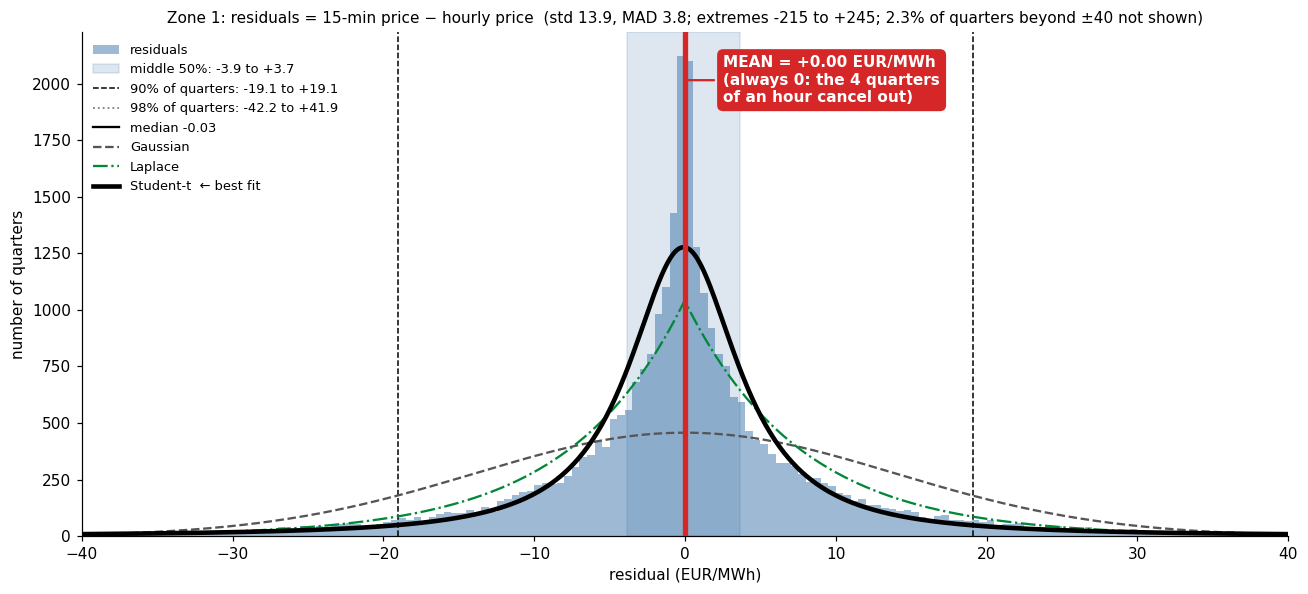

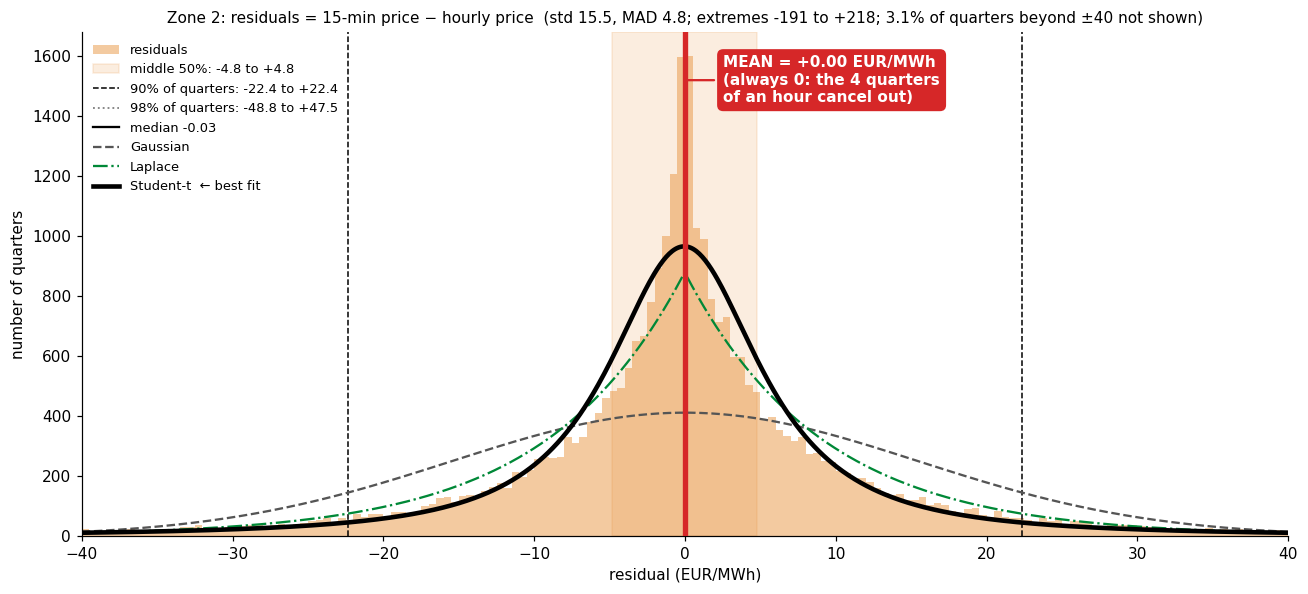

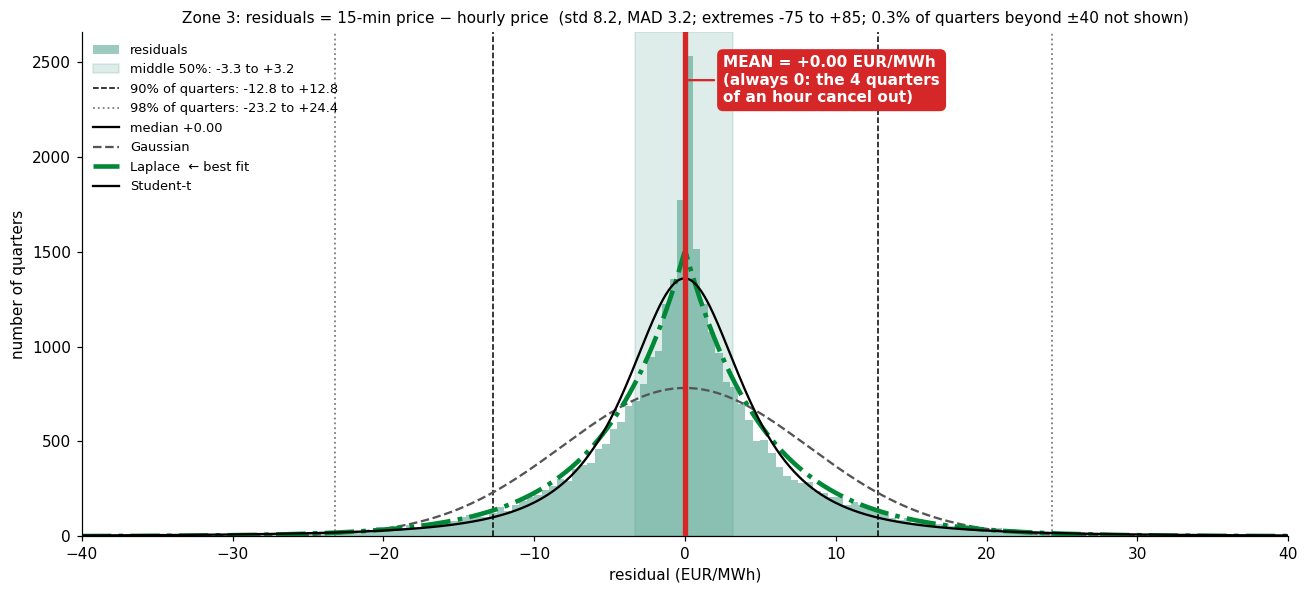

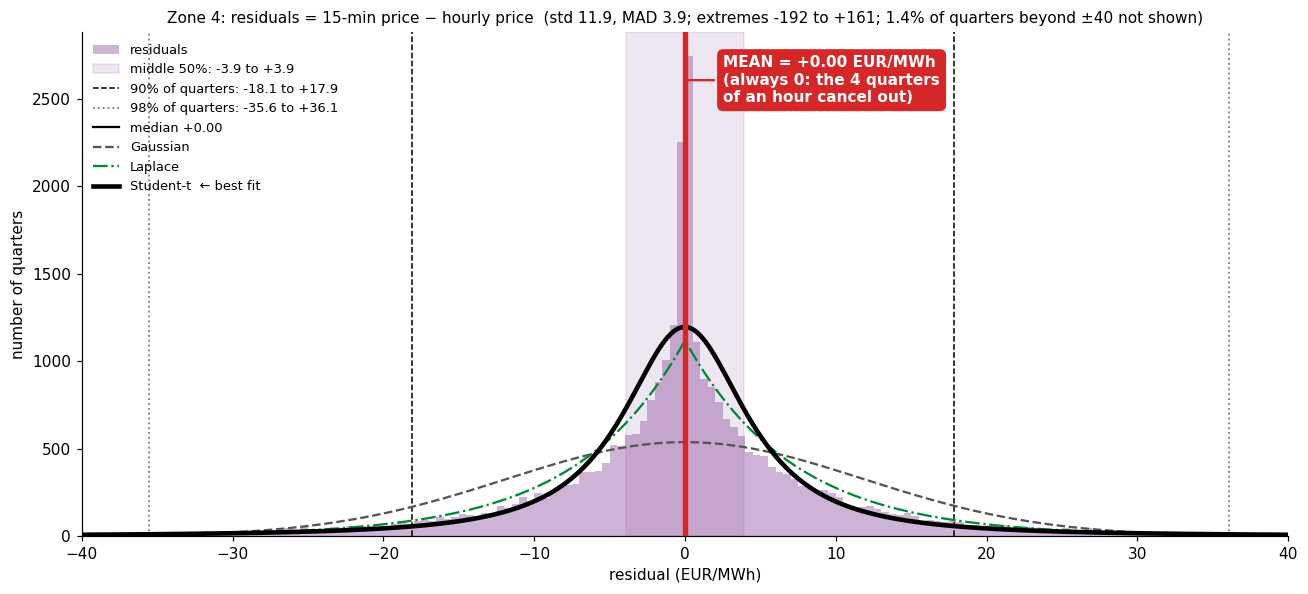

Fit quality per zone (AIC, lower = better):


market_id,Zone 1,Zone 2,Zone 3,Zone 4
distribution,,,,
Gaussian,259183.0,265910.0,224880.0,248866.0
Laplace,238552.0,249315.0,214780.0,233931.0
Student-t,235443.0,247718.0,215492.0,233722.0


In [30]:
# ---------------------------------------------------------------------------
# 0b (graph). Distribution of the residuals, one figure per zone,
#             with the mean highlighted and the best-fitting distributions overlaid
# ---------------------------------------------------------------------------
from scipy import stats

RES_FIT_STYLES = {'Gaussian': ('#555555', '--'), 'Laplace': ('#008837', '-.'), 'Student-t': ('#000000', '-')}
RES_LIMIT = 40                                               # x-axis shown: ±40 EUR/MWh (covers ≈ 98% of quarters)

res_fit_summary = []
for z, c in zip(ZONES, COLORS):
    s = df.loc[df.market_id == z, 'residual']
    x = s.to_numpy()
    p = s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    mean = round(s.mean(), 2) + 0.0                          # + 0.0 avoids printing "-0.00"
    outside = 100 * (s.abs() > RES_LIMIT).mean()

    fig, ax = plt.subplots(figsize=(12, 5.5))
    bins = np.linspace(-RES_LIMIT, RES_LIMIT, 161)            # 0.5 EUR/MWh wide bins
    counts, edges, _ = ax.hist(s[s.abs() <= RES_LIMIT], bins=bins, color=c, alpha=0.45, label='residuals')
    bin_w = edges[1] - edges[0]

    # Percentile ranges and median
    ax.axvspan(p[0.25], p[0.75], color=c, alpha=0.15, label=f'middle 50%: {p[0.25]:.1f} to {p[0.75]:+.1f}')
    ax.axvline(p[0.05], color='k', ls='--', lw=1, label=f'90% of quarters: {p[0.05]:.1f} to {p[0.95]:+.1f}')
    ax.axvline(p[0.95], color='k', ls='--', lw=1)
    ax.axvline(p[0.01], color='grey', ls=':', lw=1.2, label=f'98% of quarters: {p[0.01]:.1f} to {p[0.99]:+.1f}')
    ax.axvline(p[0.99], color='grey', ls=':', lw=1.2)
    ax.axvline(p[0.5], color='k', lw=1.5, label=f'median {p[0.5]:+.2f}')

    # Fitted distributions, scaled from density to "number of quarters"; best AIC drawn thickest
    fits = {}
    for name, dist in [('Gaussian', stats.norm), ('Laplace', stats.laplace), ('Student-t', stats.t)]:
        params = dist.fit(x)
        aic = 2 * len(params) - 2 * dist.logpdf(x, *params).sum()
        fits[name] = (params, dist, aic)
    best = min(fits, key=lambda k: fits[k][2])
    grid = np.linspace(-RES_LIMIT, RES_LIMIT, 800)
    for name, (params, dist, aic) in fits.items():
        col, ls = RES_FIT_STYLES[name]
        ax.plot(grid, dist.pdf(grid, *params) * len(x) * bin_w, color=col, ls=ls,
                lw=3 if name == best else 1.5, label=f'{name}{"  ← best fit" if name == best else ""}')
        res_fit_summary.append({'market_id': z, 'distribution': name, 'AIC': aic, 'best': name == best})

    # The mean: thick red line plus a labelled box at the top
    ax.axvline(mean, color='#d62728', lw=3.5, zorder=5)
    ax.annotate(f'MEAN = {mean:+.2f} EUR/MWh\n(always 0: the 4 quarters\nof an hour cancel out)',
                xy=(mean, counts.max() * 0.95), xytext=(25, 0), textcoords='offset points',
                color='white', fontsize=10, fontweight='bold', va='center',
                bbox=dict(boxstyle='round,pad=0.4', fc='#d62728', ec='none'), zorder=6,
                arrowprops=dict(arrowstyle='-', color='#d62728', lw=1.5))

    ax.set(title=f'{z}: residuals = 15-min price − hourly price  '
                 f'(std {s.std():.1f}, MAD {(s - p[0.5]).abs().median():.1f}; extremes {s.min():.0f} to {s.max():+.0f}; '
                 f'{outside:.1f}% of quarters beyond ±{RES_LIMIT} not shown)',
           xlabel='residual (EUR/MWh)', ylabel='number of quarters', xlim=(-RES_LIMIT, RES_LIMIT))
    ax.title.set_fontsize(10)
    ax.legend(frameon=False, fontsize=8.5, loc='upper left')
    plt.tight_layout(); plt.show()

# Which distribution fits best? (AIC: lower = better; compare within a zone only)
print('Fit quality per zone (AIC, lower = better):')
pd.DataFrame(res_fit_summary).pivot(index='distribution', columns='market_id', values='AIC').round(0)

In [32]:
# ---------------------------------------------------------------------------
# 0c. Extremes: the most extreme quarters and the days they belong to
# ---------------------------------------------------------------------------
cols = ['delivery_date', 'market_id', 'hour_index', 'quarter_index', 'price_eur_mwh']
for z in ZONES:
    d = df[df.market_id == z]
    top = d.nlargest(3, 'price_eur_mwh')[cols].assign(kind='highest')
    low = d.nsmallest(3, 'price_eur_mwh')[cols].assign(kind='lowest')
    print(z); display(pd.concat([top, low]).reset_index(drop=True))

# Days that hit the −500 EUR/MWh floor region, and which zones were affected together
floor = df[df.price_eur_mwh < -400]
print('Quarters below −400 EUR/MWh, by day and zone:')
display(floor.groupby(['delivery_date', 'market_id']).size().unstack(fill_value=0))

# Spike days: days with at least one quarter above 400 EUR/MWh
spikes = df[df.price_eur_mwh > 400]
print('Quarters above 400 EUR/MWh, by day and zone:')
spikes.groupby(['delivery_date', 'market_id']).size().unstack(fill_value=0)

Zone 1


,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh,kind
0,2026-06-24,Zone 1,21,4,747.10,highest
1,2026-06-24,Zone 1,20,4,700.00,highest
2,2026-06-24,Zone 1,21,3,699.99,highest
3,2026-05-01,Zone 1,14,2,-499.99,lowest
4,2026-05-01,Zone 1,14,3,-499.99,lowest
5,2026-05-01,Zone 1,14,4,-499.99,lowest


Zone 2


,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh,kind
0,2026-06-24,Zone 2,21,4,645.20,highest
1,2026-06-24,Zone 2,20,4,641.86,highest
2,2026-06-24,Zone 2,21,3,612.55,highest
3,2026-05-01,Zone 2,14,3,-498.65,lowest
4,2026-05-01,Zone 2,15,1,-497.80,lowest
5,2026-05-01,Zone 2,15,2,-497.80,lowest


Zone 3


...

,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh,kind
0,2026-08-13,Zone 4,20,4,487.38,highest
1,2026-08-12,Zone 4,20,4,461.17,highest
2,2026-06-24,Zone 4,20,4,433.42,highest
3,2026-05-01,Zone 4,14,3,-498.65,lowest
4,2026-05-01,Zone 4,15,1,-497.80,lowest
5,2026-05-01,Zone 4,15,2,-497.80,lowest


Quarters below −400 EUR/MWh, by day and zone:


market_id,Zone 1,Zone 2,Zone 4
delivery_date,,,
2026-04-26,4,4,4
2026-05-01,8,8,8


Quarters above 400 EUR/MWh, by day and zone:


market_id,Zone 1,Zone 2,Zone 4
delivery_date,,,
2025-10-01,1,0,0
2025-10-13,1,0,0
2025-10-14,4,4,0
2026-03-04,1,0,0
2026-05-28,4,0,0
2026-06-01,1,0,0
2026-06-18,6,4,0
2026-06-23,12,10,0
2026-06-24,13,12,1


### 0d. Does a Gaussian fit the hourly prices?
For each zone we draw the histogram of the **hourly prices** and overlay a fitted **Gaussian** (same mean and standard deviation). We also try three alternatives:
- **Student-t** (a bell curve with heavier tails),
- **skew-normal** (a bell curve allowed to lean to one side),
- **2-component Gaussian mixture** (two bells added together, for a market that switches between two regimes, e.g. normal hours and solar-midday hours).

The fits are compared with the **AIC** (Akaike information criterion; lower = better fit after penalising extra parameters) and the **KS statistic** (largest gap between the fitted and the real cumulative distribution; lower = closer).

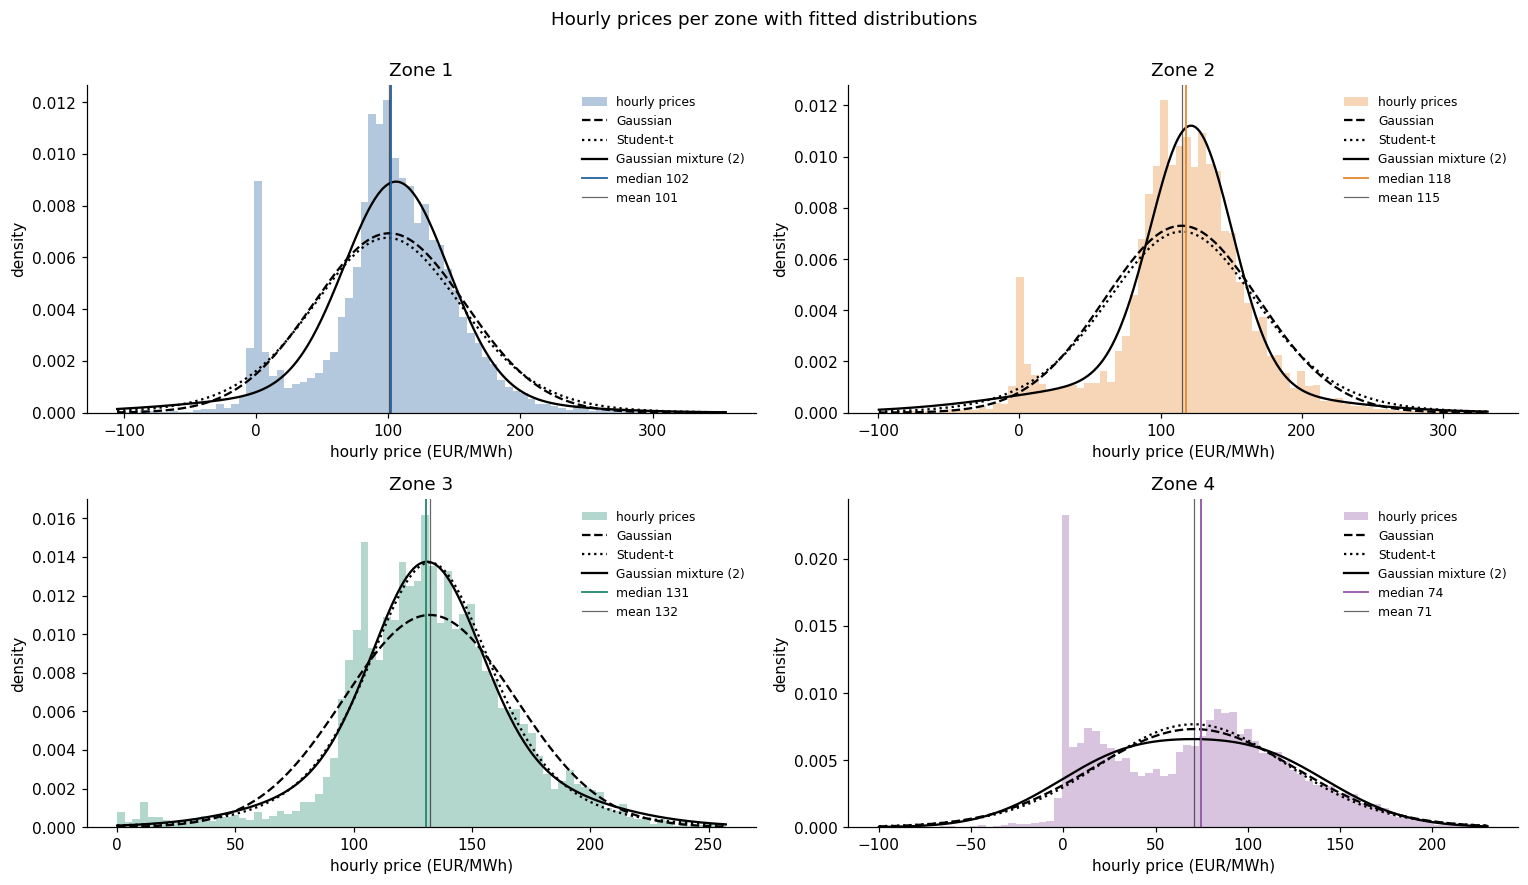

AIC                                      KS  \
market_id                Zone 1     Zone 2     Zone 3     Zone 4 Zone 1   
distribution                                                              
Gaussian              87459.372  86632.649  80090.549  86604.095  0.102   
Gaussian mixture (2)  86332.562  84728.569  79387.238  86743.333  0.044   
Student-t             86780.646  85927.409  79425.280  86402.148  0.115   
skew-normal           87428.808  86466.539  80018.353  86583.471  0.098   

                                           
market_id            Zone 2 Zone 3 Zone 4  
distribution                               
Gaussian              0.109  0.065  0.073  
Gaussian mixture (2)  0.024  0.035  0.077  
Student-t             0.115  0.034  0.072  
skew-normal           0.101  0.064  0.074

Best fit per zone by AIC:


,distribution
market_id,
Zone 1,Gaussian mixture (2)
Zone 2,Gaussian mixture (2)
Zone 3,Gaussian mixture (2)
Zone 4,Student-t


In [9]:
# ---------------------------------------------------------------------------
# 0d. Fit distributions to the hourly prices of each zone
# ---------------------------------------------------------------------------
from sklearn.mixture import GaussianMixture

def fit_candidates(x):
    """Fit several distributions to x; return {name: (pdf function, AIC, KS statistic)}."""
    out = {}
    for name, dist in [('Gaussian', stats.norm), ('Student-t', stats.t), ('skew-normal', stats.skewnorm)]:
        params = dist.fit(x)                                         # maximum-likelihood fit
        loglik = dist.logpdf(x, *params).sum()
        aic = 2 * len(params) - 2 * loglik
        ks = stats.kstest(x, dist.cdf, args=params).statistic
        out[name] = (lambda g, d=dist, p=params: d.pdf(g, *p), aic, ks)
    gm = GaussianMixture(2, random_state=0).fit(x.reshape(-1, 1))     # two Gaussian regimes
    w, mu, sd = gm.weights_, gm.means_.ravel(), np.sqrt(gm.covariances_.ravel())
    mix_pdf = lambda g: sum(w[k] * stats.norm.pdf(g, mu[k], sd[k]) for k in range(2))
    mix_cdf = lambda g: sum(w[k] * stats.norm.cdf(g, mu[k], sd[k]) for k in range(2))
    aic = gm.aic(x.reshape(-1, 1))
    ks = stats.kstest(x, mix_cdf).statistic
    out['Gaussian mixture (2)'] = (mix_pdf, aic, ks)
    return out, (w, mu, sd)

hourly_prices = H[['market_id', 'hourly_price']]
fit_rows, mixtures = [], {}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, z, c in zip(axes.flat, ZONES, COLORS):
    x = hourly_prices.loc[hourly_prices.market_id == z, 'hourly_price'].to_numpy()
    fits, mixtures[z] = fit_candidates(x)
    lo, hi = np.percentile(x, [0.2, 99.8])
    grid = np.linspace(lo, hi, 400)
    ax.hist(x[(x >= lo) & (x <= hi)], bins=80, density=True, color=c, alpha=0.35, label='hourly prices')
    for name, ls in [('Gaussian', '--'), ('Student-t', ':'), ('Gaussian mixture (2)', '-')]:
        ax.plot(grid, fits[name][0](grid), 'k', ls=ls, lw=1.5, label=name)
    ax.axvline(np.median(x), color=c, lw=1.2, label=f'median {np.median(x):.0f}')
    ax.axvline(x.mean(), color='k', lw=0.8, alpha=0.6, label=f'mean {x.mean():.0f}')
    ax.set(title=z, xlabel='hourly price (EUR/MWh)', ylabel='density')
    ax.legend(frameon=False, fontsize=8)
    for name, (_, aic, ks) in fits.items():
        fit_rows.append({'market_id': z, 'distribution': name, 'AIC': aic, 'KS': ks})
fig.suptitle('Hourly prices per zone with fitted distributions', y=1.0)
plt.tight_layout(); plt.show()

fit_tab = pd.DataFrame(fit_rows).pivot(index='distribution', columns='market_id')
display(fit_tab.round(3))
print('Best fit per zone by AIC:')
pd.DataFrame(fit_rows).loc[lambda d: d.groupby('market_id').AIC.idxmin(), ['market_id', 'distribution']].set_index('market_id')

In [10]:
# ---------------------------------------------------------------------------
# 0d (cont.). The two regimes found by the Gaussian mixture
# ---------------------------------------------------------------------------
rows = []
for z, (w, mu, sd) in mixtures.items():
    order = np.argsort(mu)                                 # low-price regime first
    for name, k in zip(['low regime', 'high regime'], order):
        rows.append({'market_id': z, 'regime': name, 'weight_%': 100 * w[k], 'mean': mu[k], 'std': sd[k]})
pd.DataFrame(rows).set_index(['market_id', 'regime']).round(1)

weight_%   mean   std
market_id regime                            
Zone 1    low regime       20.4   79.1  98.5
          high regime      79.6  106.3  39.1
Zone 2    low regime       27.5   96.6  90.6
          high regime      72.5  121.9  28.8
Zone 3    low regime       55.7  130.8  22.0
          high regime      44.3  134.1  48.6
Zone 4    low regime       46.3   31.7  39.4
          high regime      53.7  104.5  41.8

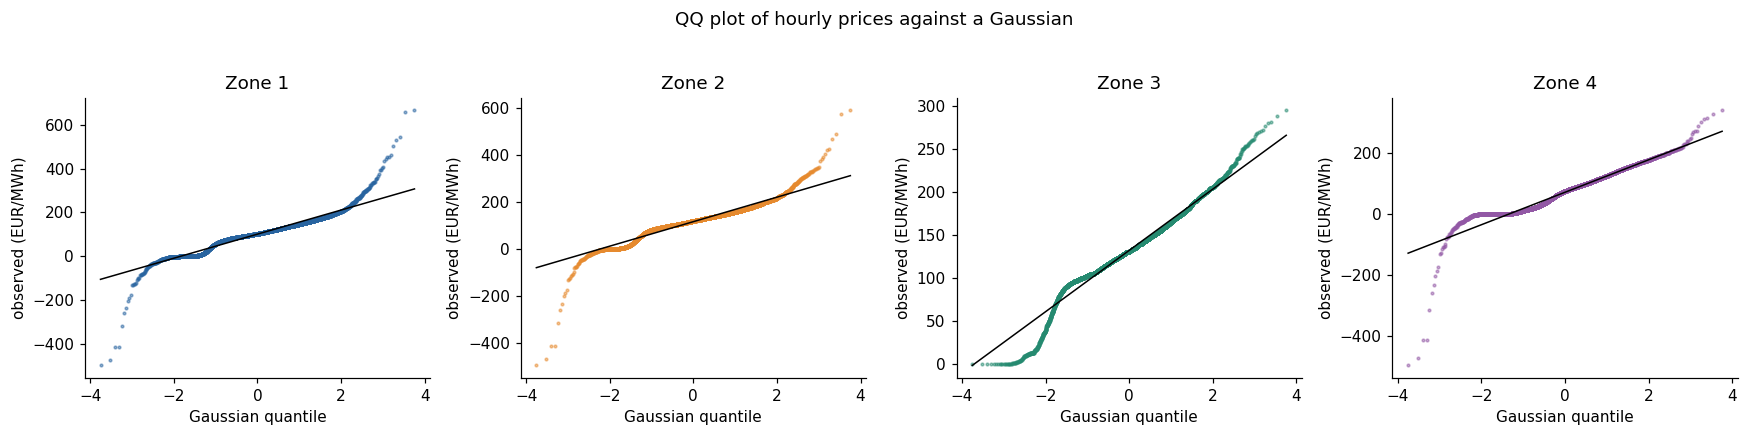

In [11]:
# ---------------------------------------------------------------------------
# 0e. QQ plots: hourly prices vs a Gaussian (straight line = Gaussian)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, z, c in zip(axes, ZONES, COLORS):
    x = hourly_prices.loc[hourly_prices.market_id == z, 'hourly_price'].to_numpy()
    (theo, obs), (slope, icpt, _) = stats.probplot(x, dist='norm')   # theoretical vs observed quantiles
    ax.scatter(theo, obs, s=3, color=c, alpha=0.5)
    ax.plot(theo, slope * theo + icpt, 'k', lw=1)                      # where a Gaussian would lie
    ax.set(title=z, xlabel='Gaussian quantile', ylabel='observed (EUR/MWh)')
fig.suptitle('QQ plot of hourly prices against a Gaussian', y=1.03)
plt.tight_layout(); plt.show()

### 0f. Distribution of prices hour by hour
One box per hour of the day: the box is the middle 50% of days (IQR), the line inside is the median, the whiskers reach the 5th and 95th percentiles. This shows how the *whole distribution*, not just the average, changes through the day.

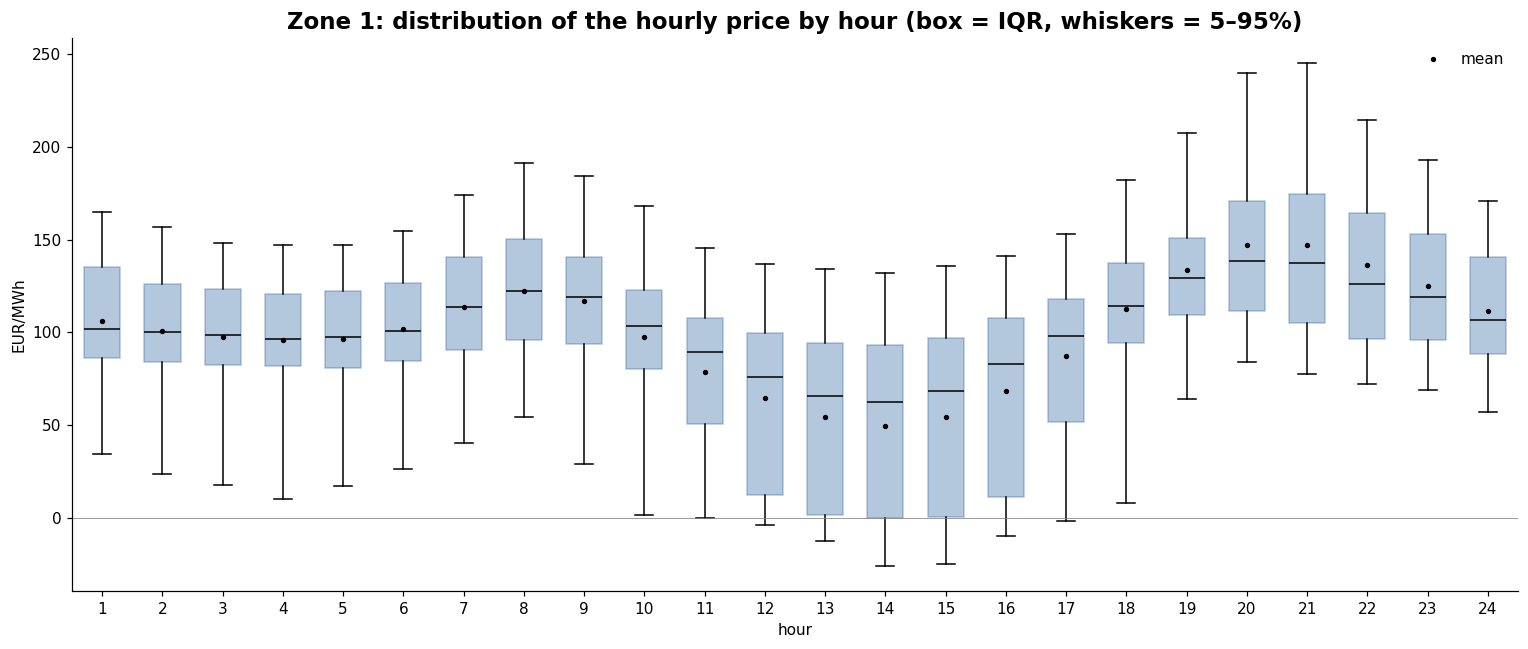

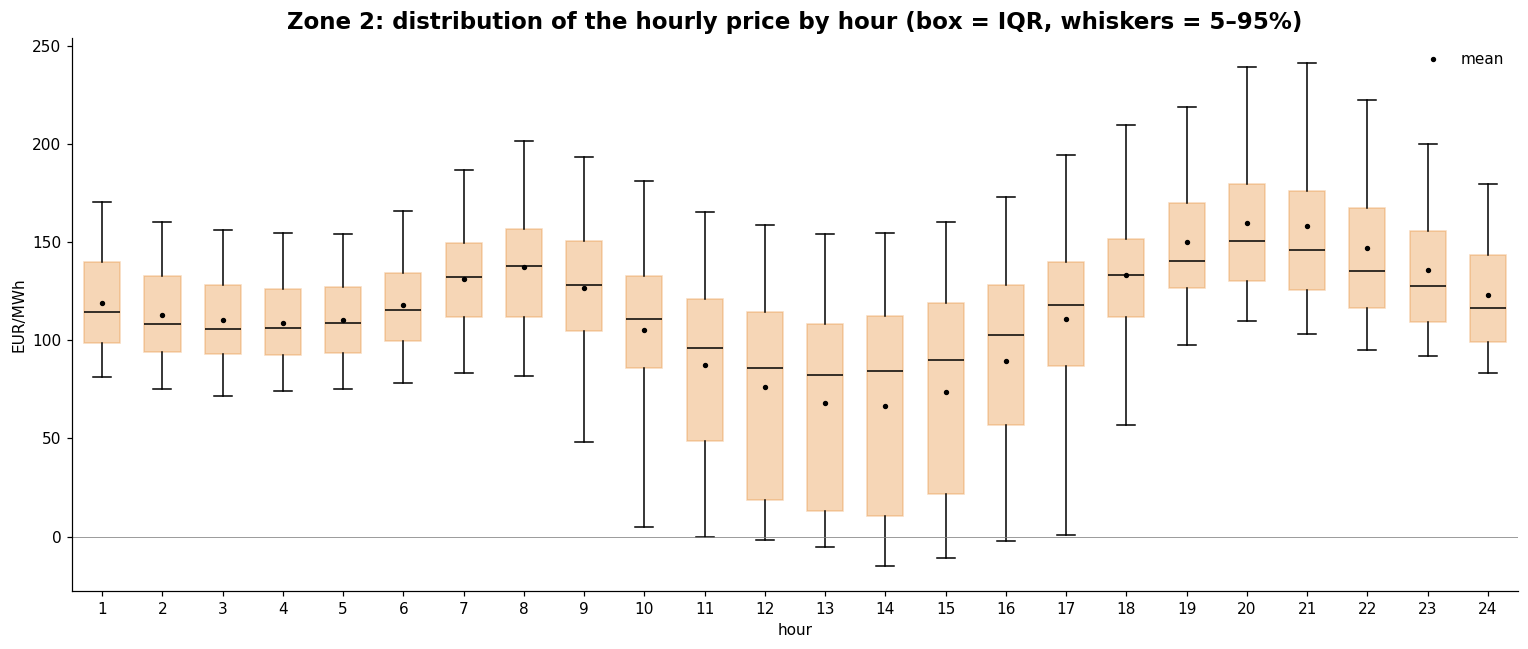

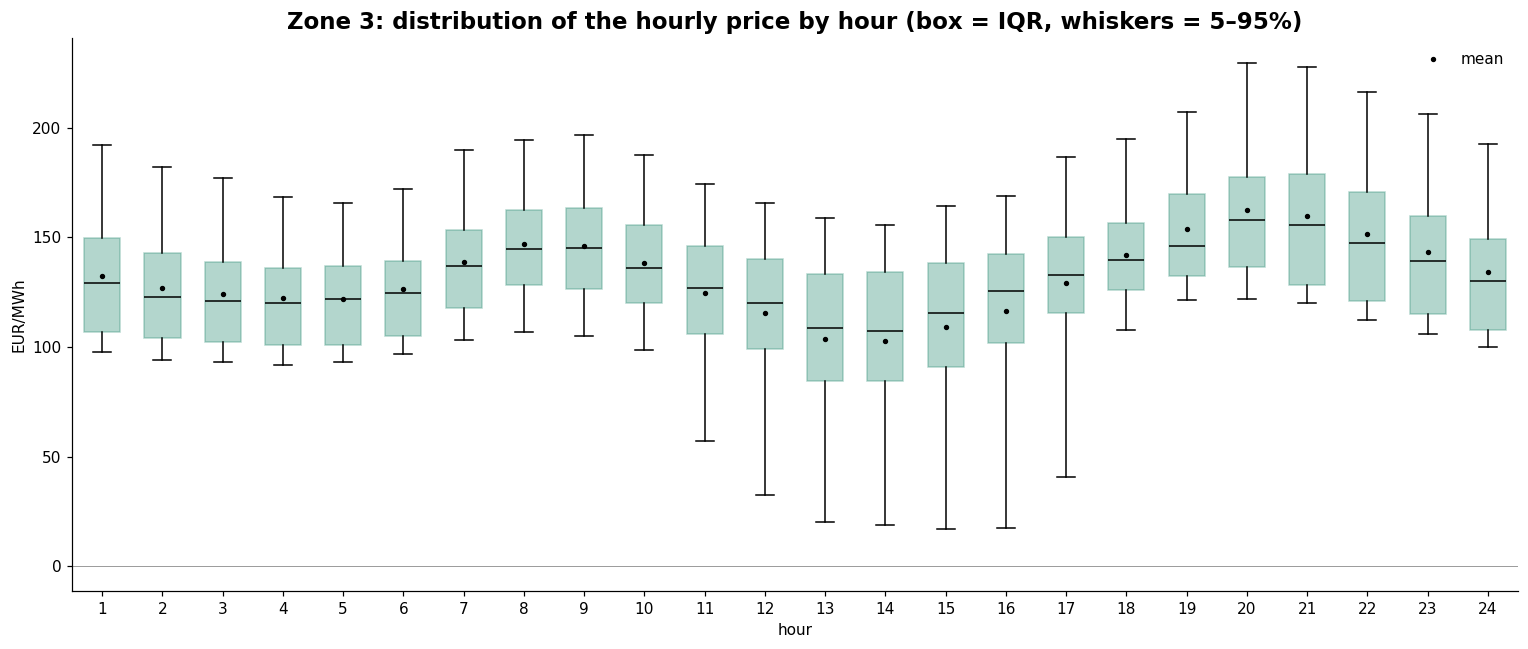

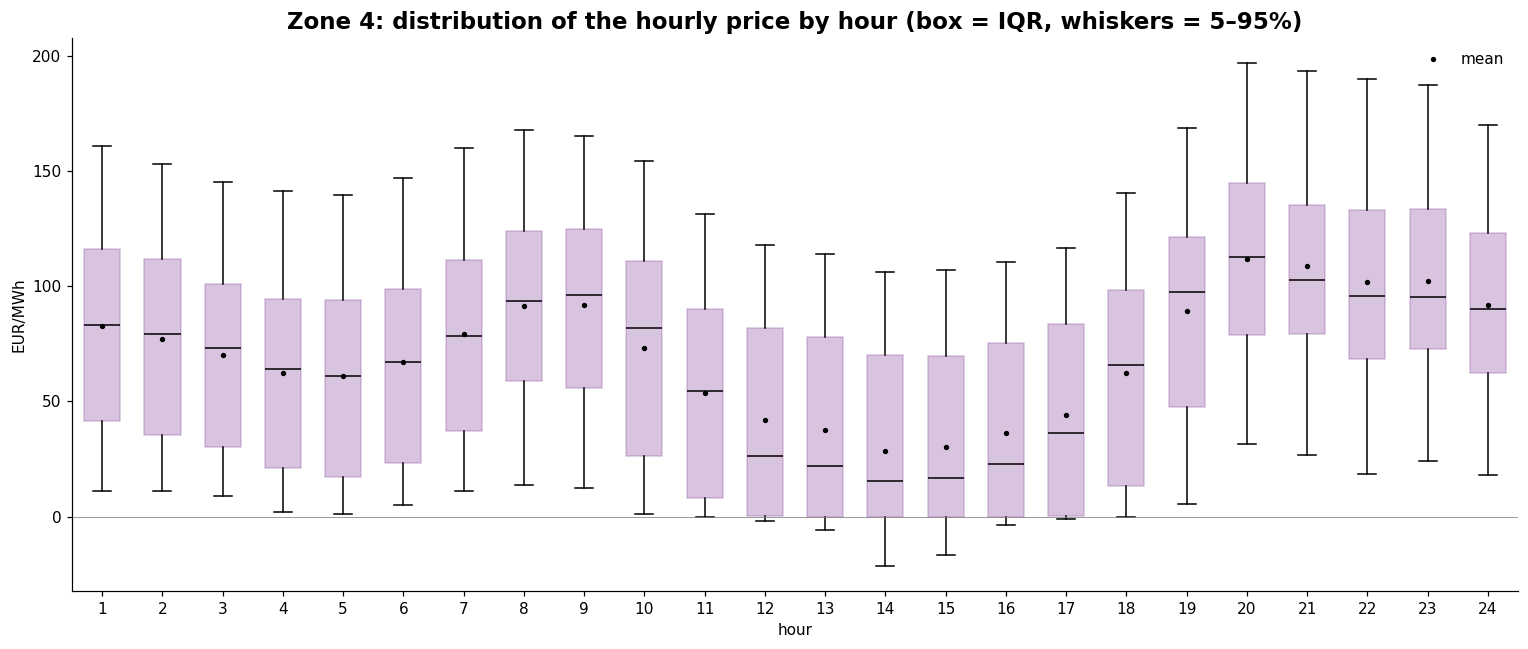

Skewness of the hourly price by hour (> 0: long tail of high prices; < 0: long tail of low prices):


hour_index,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
market_id,,,,,,,,,,,,,,,,,,,,,
Zone 1,-0.5,-0.7,-0.8,-0.8,-0.8,-0.7,-0.5,-0.0,0.2,-0.2,...,-2.3,-0.6,0.3,0.3,1.0,1.8,2.8,3.0,1.6,-0.1
Zone 2,0.4,0.1,0.1,0.0,-0.1,0.1,-0.1,0.5,0.4,0.2,...,-2.1,-0.7,0.1,0.3,1.0,1.8,3.0,3.3,2.0,0.7
Zone 3,0.7,0.7,0.7,0.5,0.5,0.6,0.7,0.4,0.4,-0.3,...,-0.8,-1.0,-1.1,-0.2,1.1,1.1,1.0,0.9,1.0,0.9
Zone 4,0.1,0.1,0.2,0.3,0.3,0.3,0.2,-0.0,-0.1,0.1,...,-3.3,-0.7,0.4,0.2,-0.1,0.5,0.8,0.4,0.3,0.1


In [37]:
# ---------------------------------------------------------------------------
# 0f. Box plots of the hourly price by hour of day (one figure per zone)
# ---------------------------------------------------------------------------
for z, c in zip(ZONES, COLORS):
    hz = H[H.market_id == z]
    data = [hz.loc[hz.hour_index == h, 'hourly_price'].to_numpy() for h in range(1, 25)]
    fig, ax = plt.subplots(figsize=(14, 6))
    bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6)
    for box in bp['boxes']:
        box.set(facecolor=c, alpha=0.35, edgecolor=c)
    for med in bp['medians']:
        med.set(color='k')
    ax.plot(range(1, 25), [d.mean() for d in data], 'k.', ms=5, label='mean')   # mean vs median
    ax.axhline(0, color='grey', lw=0.5)
    ax.set(xlabel='hour', ylabel='EUR/MWh')
    ax.set_title(f'{z}: distribution of the hourly price by hour (box = IQR, whiskers = 5–95%)',
        fontsize=15, fontweight='bold')
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

# Skewness of the hourly price at each hour: where is the distribution lopsided?
skew_by_hour = H.groupby(['hour_index', 'market_id']).hourly_price.skew().unstack()
print('Skewness of the hourly price by hour (> 0: long tail of high prices; < 0: long tail of low prices):')
skew_by_hour.T.round(1)

### 0f (cont.) How much does the price change between hours, and how does that compare with the movement inside the hour? (all zones)

**Business question:** the hourly curve shows how the price moves *from one hour to the next*. How large is that visible movement, how large is the movement hidden *inside* each hour, and at which times of day do they happen?

**What we measure, for every hour of every day (all four zones pooled):**

| Measure | Definition | Visible in hourly data? |
|---|---|---|
| **Hour-to-hour change** | hourly price of this hour − hourly price of the previous hour | Yes: this is the given curve |
| **Boundary jump** | first 15-min price of this hour (Q1) − last 15-min price of the previous hour (Q4) | No: the real step at the hour change |
| **Movement inside the hour** | average distance of the 4 quarter prices from their hourly price (mean \|residual\|) | No: this is what we predict |

Midnight is included (hour 1 is compared with hour 24 of the previous day). The two missing daylight-saving days are skipped, so no change is ever computed across a gap.

**How to read the charts**
- **Box plot (one box per hour):** the change *into* that hour across all days. A box above 0 means the price usually rises into that hour (a ramp up), below 0 that it usually falls. The line in the box is the median, the red dot the mean, the box the middle 50% of days and the whiskers 90% of days. A tall box means that hour's change is unpredictable from day to day.
- **Line chart (three lines):** the *typical size* (median, ignoring direction) of each kind of change by hour of day. Comparing the lines shows how much of the movement the hourly curve already reveals (blue) and how much stays hidden (orange and green).
- **Summary table:** the same three measures in numbers: centre (mean, median), spread (std, MAD) and the range covering 90% of hours (p5 to p95). Medians and MAD are reported next to means and std because price changes have heavy tails (section 0b).

**Why it matters**
- **For AET:** the hour-to-hour change is the ramp a trader already sees. The boundary jump and the movement inside the hour are what an hourly view hides, and they are what a flexible asset (hydro, pumped storage, batteries) can capture by shifting output between quarters.
- **For the model:** if the hidden movement is largest exactly where the visible hour-to-hour change is largest, the slope between hours is a strong, simple predictor (chapter 3). Hours where the hidden movement stays large while the visible change is small are where the slope alone will fail and other features are needed.

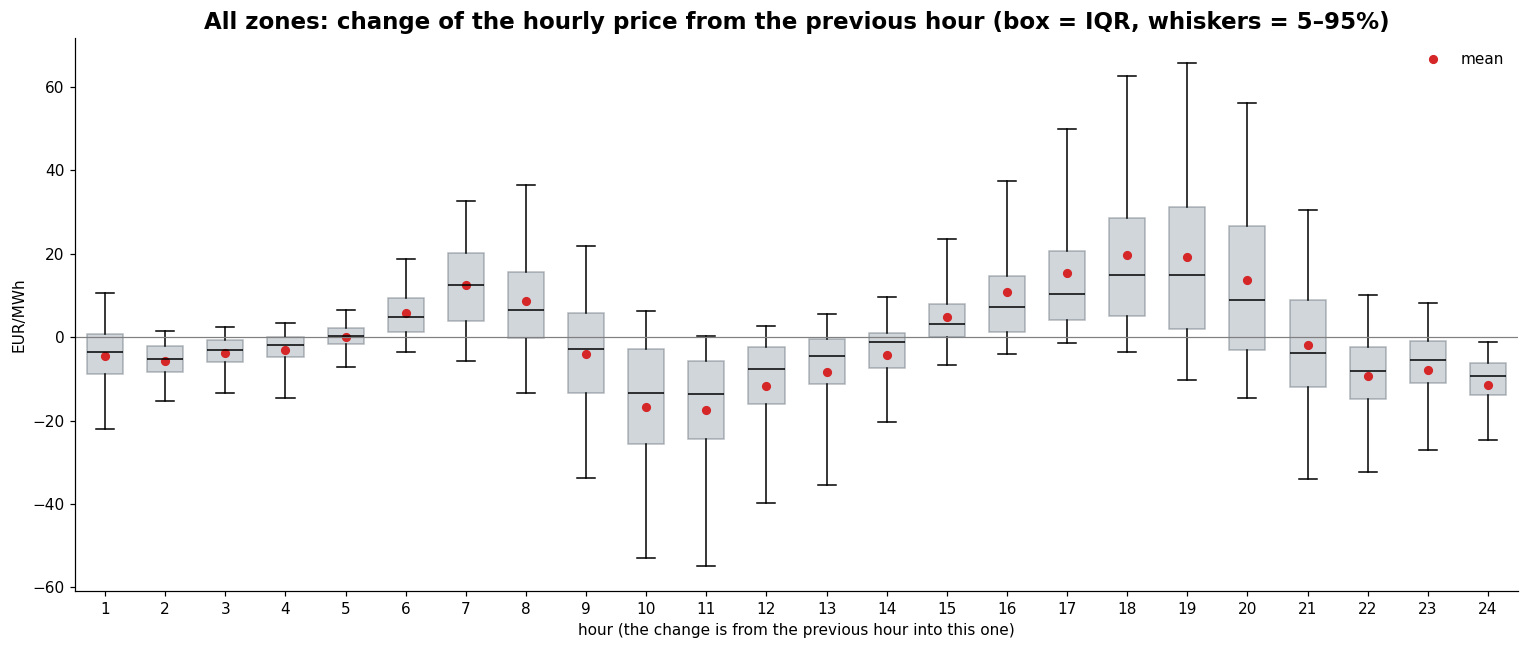

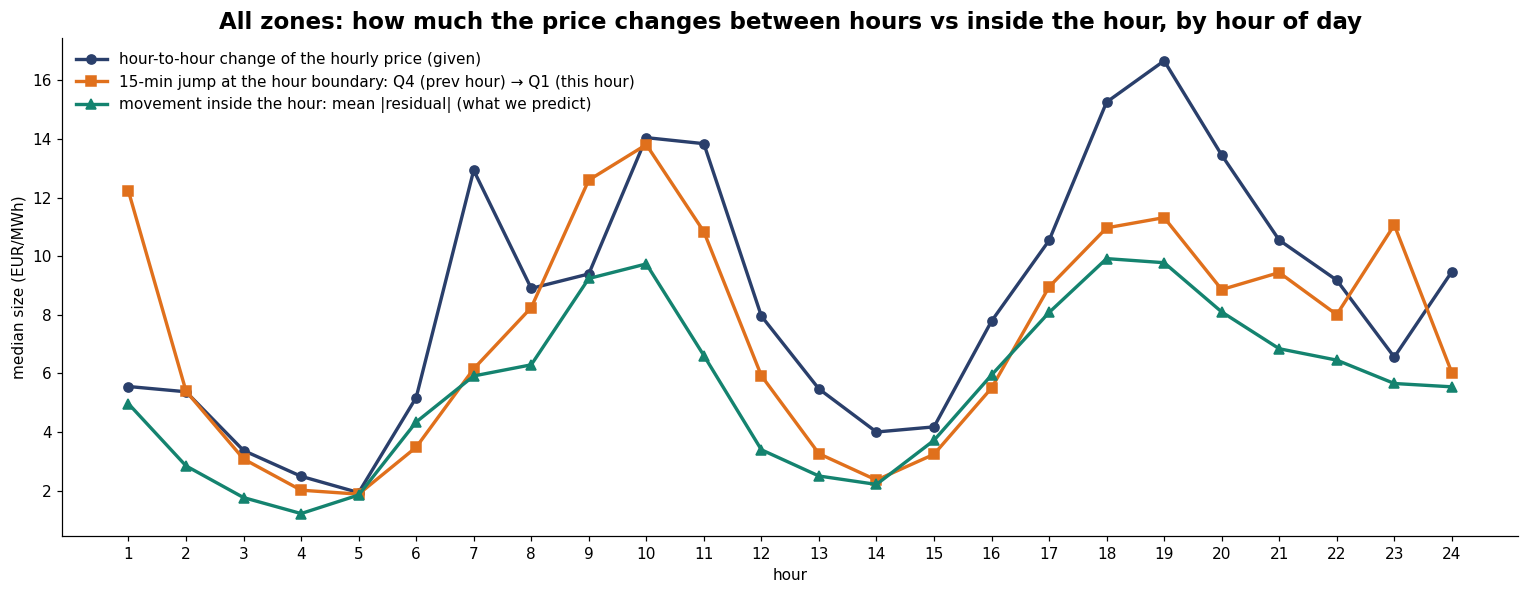

All zones together (EUR/MWh):


,count,mean,median,std,MAD,p5,p95
hour-to-hour change (signed),31956.0,0.02,-0.84,19.64,7.17,-25.76,30.09
|hour-to-hour change|,31956.0,12.02,7.36,15.53,5.40,0.31,39.42
boundary jump Q4→Q1 (signed),31956.0,1.79,1.05,16.96,6.10,-24.61,27.20
|boundary jump Q4→Q1|,31956.0,10.72,6.25,13.27,5.12,0.03,36.03
movement inside the hour (mean |residual|),31968.0,7.30,4.90,8.34,3.24,0.31,22.31


In [ ]:
# 0f (cont.) Hour-to-hour changes across the whole day, ALL ZONES together

# Real clock time of each hour, so midnight is included: hour 1 is compared with hour 24 of the
# previous calendar day (only when that day exists; the 2 missing DST days leave a gap)
# Work on a copy sorted by zone and time; results are written back by row index,
# so the row order of H (which later cells rely on) is not changed
t = H.sort_values(['market_id', 'delivery_date', 'hour_index'])
hour_start = t.delivery_date + pd.to_timedelta(t.hour_index - 1, unit='h')
consecutive = (hour_start - hour_start.groupby(t.market_id).shift(1)) == pd.Timedelta(hours=1)

# 1) Change of the hourly price from the previous hour (the visible step)
H['change_from_prev'] = (t.hourly_price - t.groupby('market_id').hourly_price.shift(1)).where(consecutive)
# 2) Jump at the boundary: Q1 of this hour minus Q4 of the previous hour (the real 15-min step)
q1_now = t.hourly_price + t.r1
q4_prev = (t.hourly_price + t.r4).groupby(t.market_id).shift(1)
H['boundary_jump'] = (q1_now - q4_prev).where(consecutive)
# 3) Movement inside this hour (already in H): abs_res = mean |residual| of the 4 quarters

hours = range(1, 25)

# (a) Box plot: how much and in which direction the price changes INTO each hour
data = [H.loc[H.hour_index == h, 'change_from_prev'].dropna().to_numpy() for h in hours]
fig, ax = plt.subplots(figsize=(14, 6))
bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6)
for box in bp['boxes']:
    box.set(facecolor='#9aa5b1', alpha=0.45, edgecolor='#5b6670')
for med in bp['medians']:
    med.set(color='k')
ax.plot(list(hours), [d.mean() for d in data], 'o', color='#d62728', ms=5, label='mean')
ax.axhline(0, color='grey', lw=0.8)
ax.set(xlabel='hour (the change is from the previous hour into this one)', ylabel='EUR/MWh')
ax.set_title('All zones: change of the hourly price from the previous hour (box = IQR, whiskers = 5–95%)',
             fontsize=15, fontweight='bold')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# (b) Size of the three kinds of change by hour of day, all zones together
size_by_hour = H.groupby('hour_index').agg(
    hour_to_hour=('change_from_prev', lambda s: s.abs().median()),
    boundary_jump=('boundary_jump', lambda s: s.abs().median()),
    inside_hour=('abs_res', 'median'))
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(size_by_hour.index, size_by_hour.hour_to_hour, color='#2a3f6b', marker='o', lw=2.2,
        label='hour-to-hour change of the hourly price (given)')
ax.plot(size_by_hour.index, size_by_hour.boundary_jump, color='#e0701c', marker='s', lw=2.2,
        label='15-min jump at the hour boundary: Q4 (prev hour) → Q1 (this hour)')
ax.plot(size_by_hour.index, size_by_hour.inside_hour, color='#14836f', marker='^', lw=2.2,
        label='movement inside the hour: mean |residual| (what we predict)')
ax.set(xlabel='hour', ylabel='median size (EUR/MWh)', xticks=list(hours))
ax.set_title('All zones: how much the price changes between hours vs inside the hour, by hour of day',
             fontsize=15, fontweight='bold')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# (c) Summary numbers, all zones together
def quick_stats(s):
    # Count, mean, median, spread and the 5–95% range of one series
    s = s.dropna()
    return pd.Series({'count': len(s), 'mean': s.mean(), 'median': s.median(), 'std': s.std(),
                      'MAD': (s - s.median()).abs().median(),
                      'p5': s.quantile(0.05), 'p95': s.quantile(0.95)})


all_summary = pd.DataFrame({
    'hour-to-hour change (signed)':               quick_stats(H.change_from_prev),
    '|hour-to-hour change|':                      quick_stats(H.change_from_prev.abs()),
    'boundary jump Q4→Q1 (signed)':               quick_stats(H.boundary_jump),
    '|boundary jump Q4→Q1|':                      quick_stats(H.boundary_jump.abs()),
    'movement inside the hour (mean |residual|)': quick_stats(H.abs_res),
}).T
print('All zones together (EUR/MWh):')
all_summary.round(2)

### 0f (cont.) Hour-to-hour changes per zone

**Business question:** do the four markets ramp at the same times and with the same intensity, or does each zone need its own treatment?

**What the cell shows**
- **One box plot per zone:** the change of the hourly price into each hour, as above but for a single zone. It shows *when* each market ramps up and down and *how predictable* that ramp is from day to day (box height).
- **One line chart with all zones:** the typical size (median absolute change) of the hour-to-hour change by hour. Lines that peak at the same hours mean the zones share the same daily rhythm; different heights mean different intensity.
- **Summary table per zone:**
  - **mean / median \|hour change\|:** typical size of the visible step between hours (the median is the robust "typical day"; the mean is pulled up by spike days).
  - **p95 \|hour change\|:** the step that is exceeded on only 5% of hours, a measure of ramp risk.
  - **median \|boundary jump\|:** typical size of the real 15-min step at the hour change.
  - **median inside hour:** typical movement hidden inside the hour.
  - **jump / hour change** and **inside / hour change:** the hidden movement as a share of the visible one. For example, 0.35 means the movement inside the hour is typically about one third of the change between hours.
- **Peak hour per zone:** the hour with the largest typical change into it, i.e. the steepest point of each market's daily curve.

**Why it matters**
- **For AET:** zones with larger and less predictable hour-to-hour changes carry more ramp risk, and their 15-minute profiles deviate more from a flat hourly profile. These are the markets where quarter-hour pricing has the most value and where hourly-based valuations are least reliable.
- **For the model:** each zone counts for 25% of the score. If the zones share the same peak hours but differ in size, one pooled model with **zone-specific scaling** (e.g. a slope factor k per zone) is enough. If the ratios *inside / hour change* differ a lot between zones, the zone must also be an explicit feature, so that one market's behaviour is not averaged into another's.

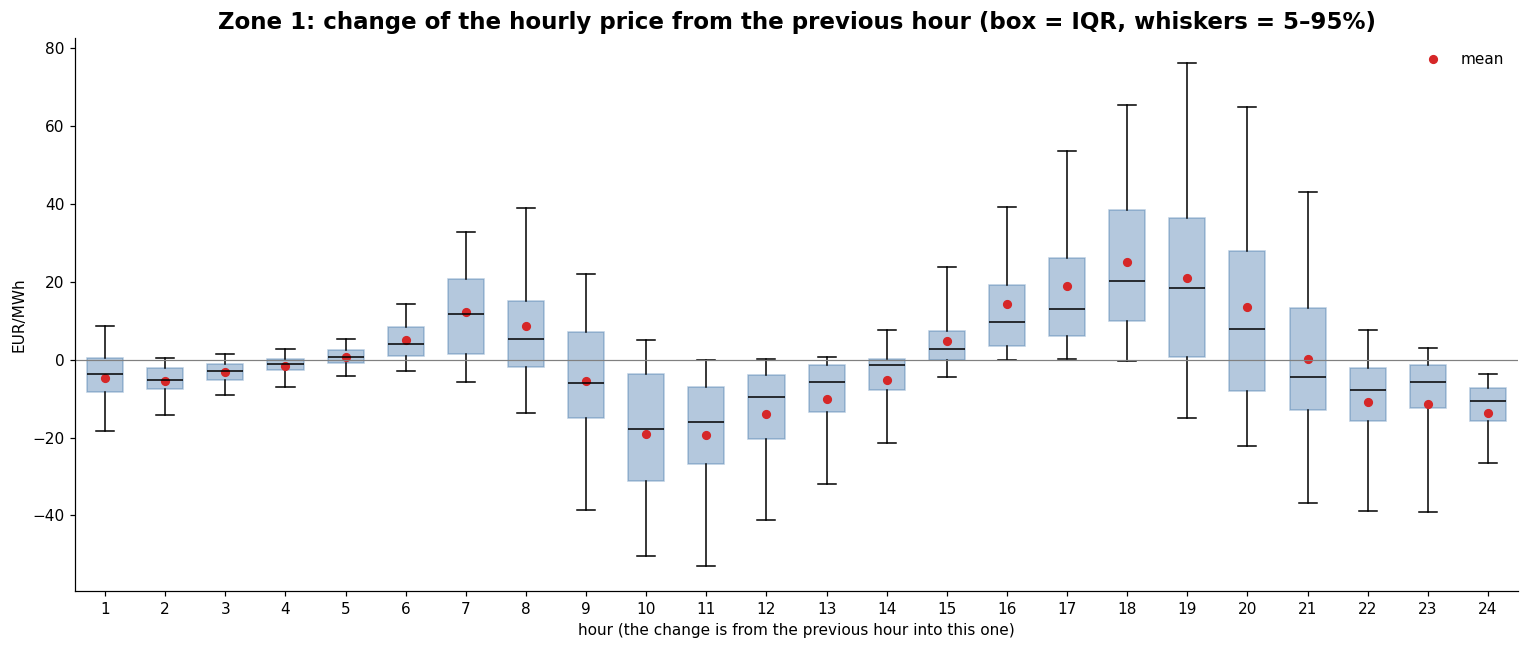

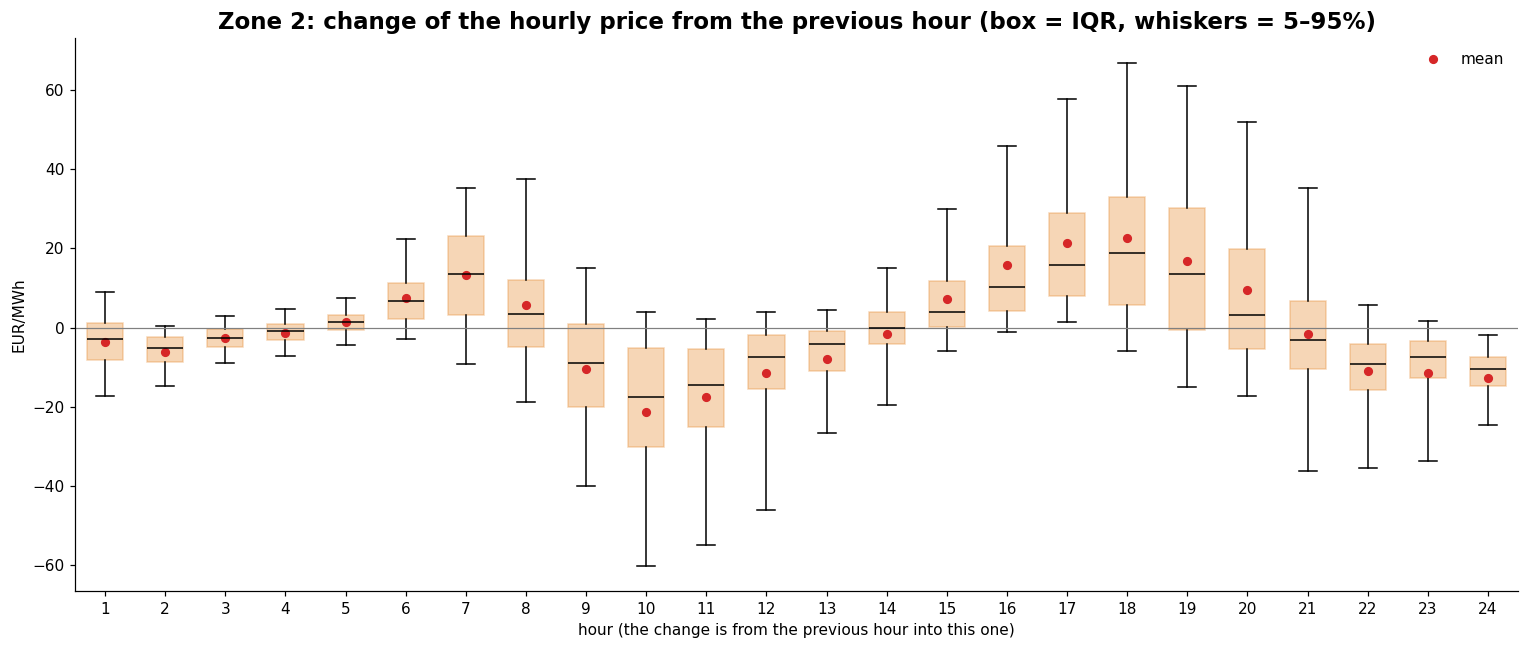

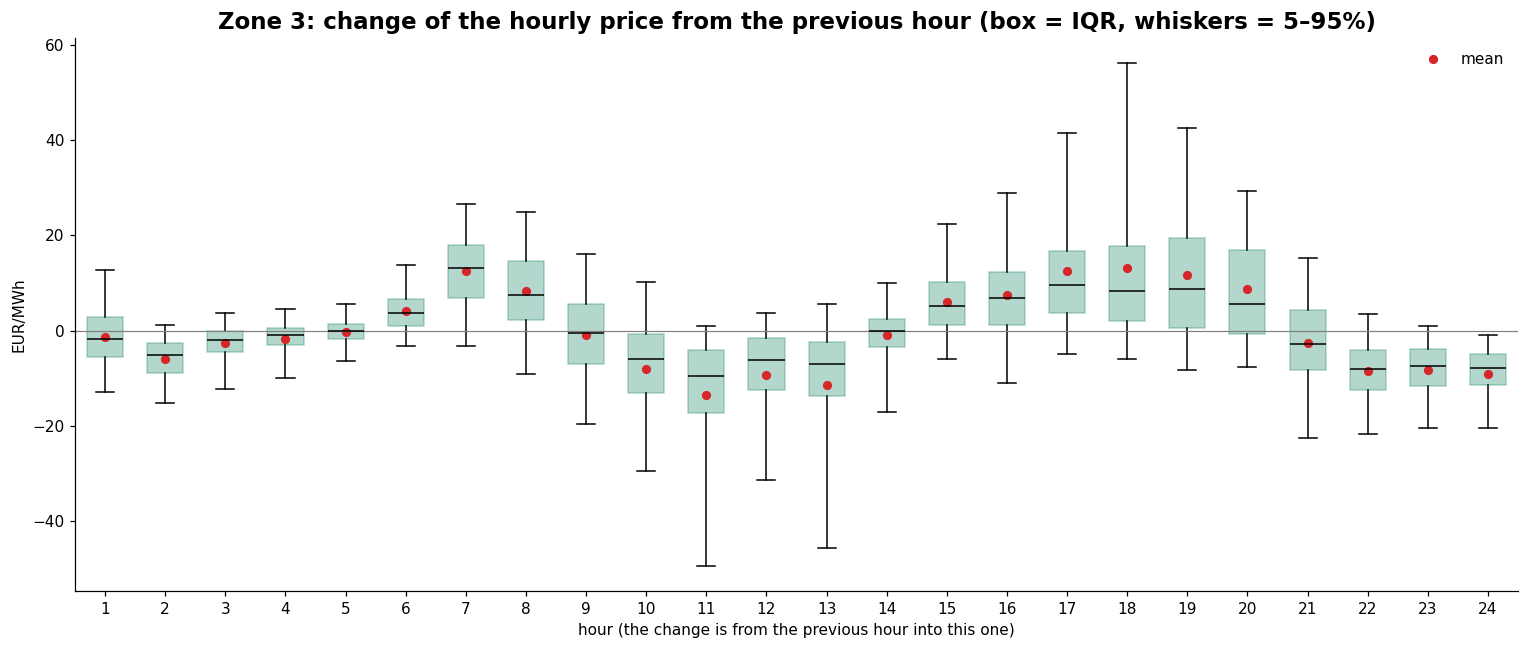

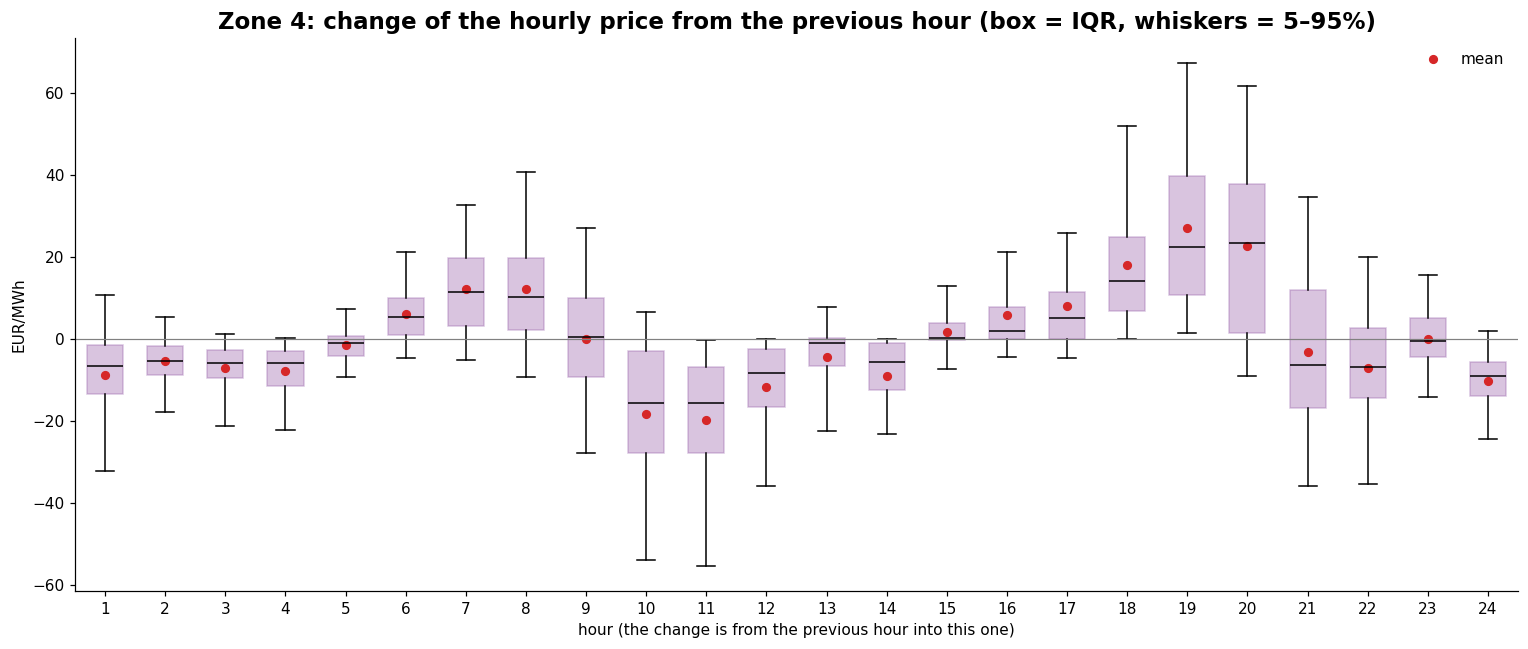

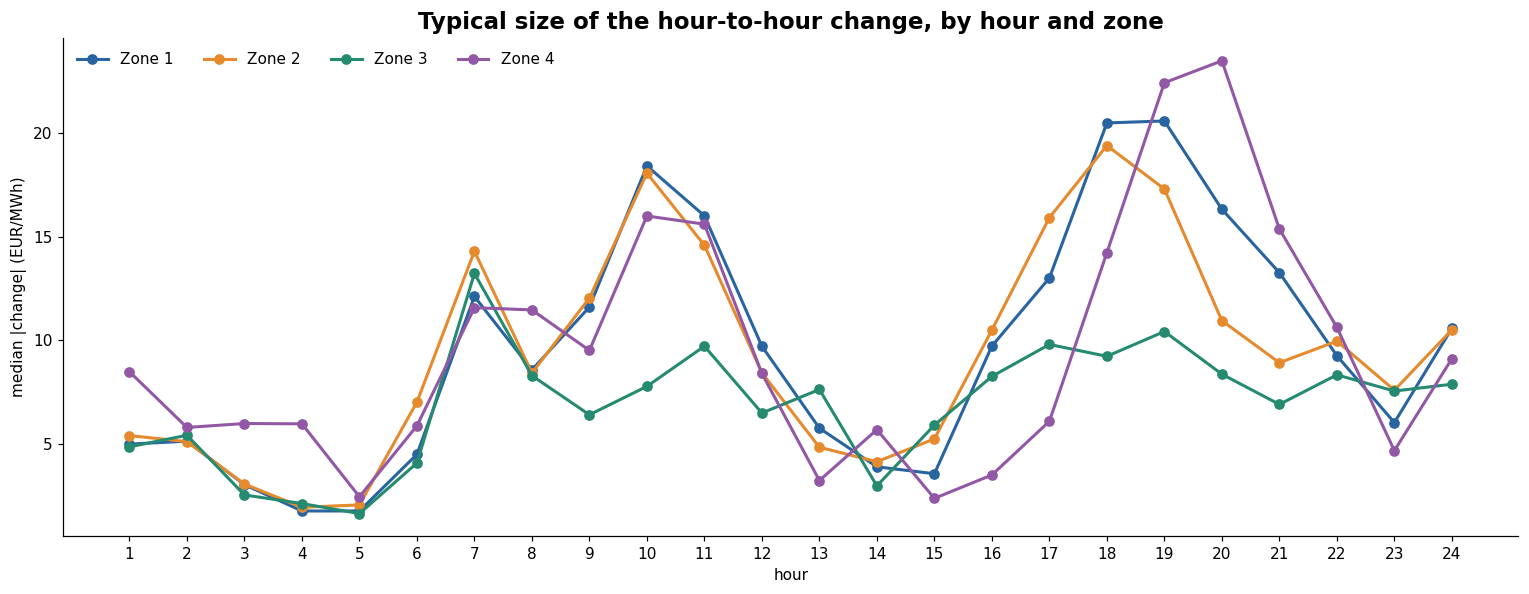

Per zone (EUR/MWh; the last two columns are ratios):


,mean_abs_hour_change,median_abs_hour_change,p95_abs_hour_change,median_abs_boundary_jump,median_inside_hour,jump / hour change,inside / hour change
market_id,,,,,,,
Zone 1,13.33,7.73,44.64,5.86,4.79,0.76,0.62
Zone 2,13.14,7.84,43.61,8.83,6.05,1.13,0.77
Zone 3,9.30,6.33,26.85,5.29,3.98,0.84,0.63
Zone 4,12.33,7.77,40.50,5.75,5.05,0.74,0.65


Hour with the largest typical change into it, per zone:


,hour,median |change|
market_id,,
Zone 1,19,20.6
Zone 2,18,19.4
Zone 3,7,13.2
Zone 4,20,23.5


In [ ]:
# 0f (cont.) Hour-to-hour changes PER ZONE

# (a) Box plot per zone: change of the hourly price into each hour
for z, c in zip(ZONES, COLORS):
    hz = H[H.market_id == z]
    data = [hz.loc[hz.hour_index == h, 'change_from_prev'].dropna().to_numpy() for h in hours]
    fig, ax = plt.subplots(figsize=(14, 6))
    bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.6)
    for box in bp['boxes']:
        box.set(facecolor=c, alpha=0.35, edgecolor=c)
    for med in bp['medians']:
        med.set(color='k')
    ax.plot(list(hours), [d.mean() for d in data], 'o', color='#d62728', ms=5, label='mean')
    ax.axhline(0, color='grey', lw=0.8)
    ax.set(xlabel='hour (the change is from the previous hour into this one)', ylabel='EUR/MWh')
    ax.set_title(f'{z}: change of the hourly price from the previous hour (box = IQR, whiskers = 5–95%)',
                 fontsize=15, fontweight='bold')
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

# (b) All zones on one chart: typical size of the hour-to-hour change by hour
fig, ax = plt.subplots(figsize=(14, 5.5))
for z, c in zip(ZONES, COLORS):
    ax.plot(list(hours), H[H.market_id == z].groupby('hour_index').change_from_prev.apply(lambda s: s.abs().median()),
            color=c, marker='o', lw=2, label=z)
ax.set(xlabel='hour', ylabel='median |change| (EUR/MWh)', xticks=list(hours))
ax.set_title('Typical size of the hour-to-hour change, by hour and zone', fontsize=15, fontweight='bold')
ax.legend(frameon=False, ncol=4)
plt.tight_layout(); plt.show()

# (c) Summary table per zone: visible change between hours vs hidden movement inside the hour
zone_summary = H.groupby('market_id').agg(
    mean_abs_hour_change=('change_from_prev', lambda s: s.abs().mean()),
    median_abs_hour_change=('change_from_prev', lambda s: s.abs().median()),
    p95_abs_hour_change=('change_from_prev', lambda s: s.abs().quantile(0.95)),
    median_abs_boundary_jump=('boundary_jump', lambda s: s.abs().median()),
    median_inside_hour=('abs_res', 'median'))
zone_summary['jump / hour change'] = zone_summary.median_abs_boundary_jump / zone_summary.median_abs_hour_change
zone_summary['inside / hour change'] = zone_summary.median_inside_hour / zone_summary.median_abs_hour_change
print('Per zone (EUR/MWh; the last two columns are ratios):')
display(zone_summary.round(2))

# (d) Hour with the biggest typical change, per zone
peak = H.groupby(['market_id', 'hour_index']).change_from_prev.apply(lambda s: s.abs().median()).unstack()
print('Hour with the largest typical change into it, per zone:')
pd.DataFrame({'hour': peak.idxmax(axis=1), 'median |change|': peak.max(axis=1).round(1)})

### 0g. Which distribution fits the residuals?
The residual is what we predict, and the choice of loss function follows from its distribution. A **Gaussian** error matches squared-error (mean) estimates; a **Laplace** distribution (a sharp peak with exponential tails) matches **absolute-error (median) estimates**, which is what the challenge's MAE rewards. We fit both, plus a Student-t.

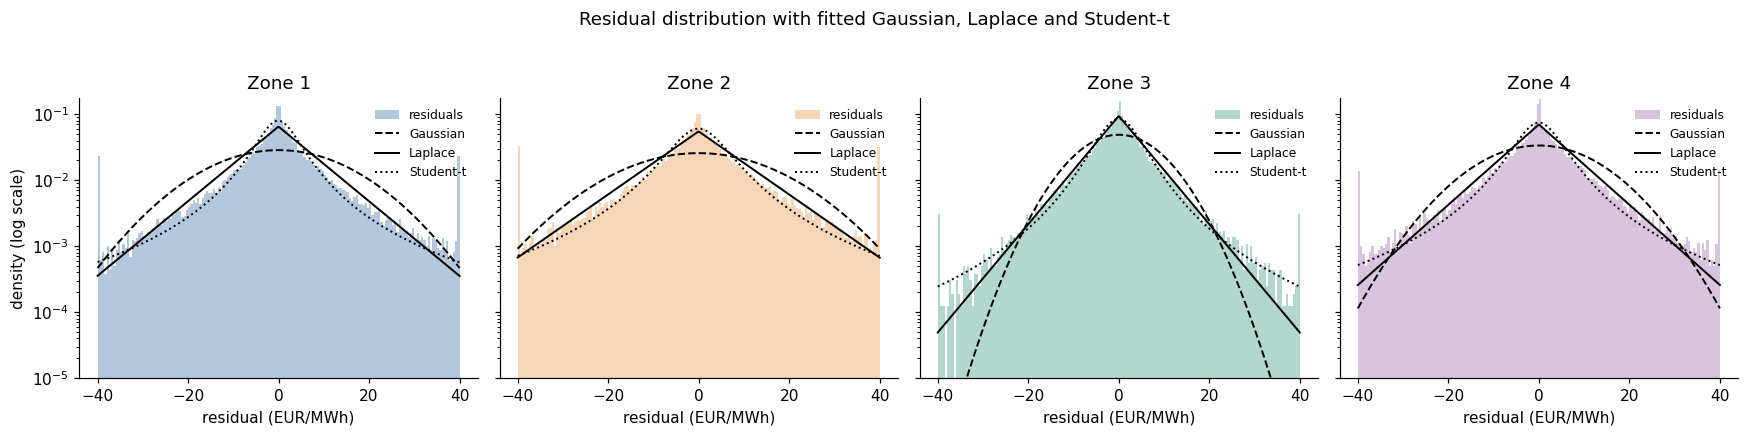

AIC                                         KS         \
market_id         Zone 1      Zone 2      Zone 3      Zone 4 Zone 1 Zone 2   
distribution                                                                 
Gaussian      259183.054  265910.441  224880.254  248866.075  0.152  0.132   
Laplace       238551.607  249314.859  214780.397  233930.546  0.063  0.048   
Student-t     235443.217  247717.891  215491.836  233721.861  0.031  0.028   

                            
market_id    Zone 3 Zone 4  
distribution                
Gaussian      0.100  0.122  
Laplace       0.028  0.052  
Student-t     0.031  0.044

Best fit per zone by AIC:


,distribution
market_id,
Zone 1,Student-t
Zone 2,Student-t
Zone 3,Laplace
Zone 4,Student-t


In [13]:
# ---------------------------------------------------------------------------
# 0g. Fit Gaussian, Laplace and Student-t to the residuals of each zone
# ---------------------------------------------------------------------------
res_rows = []
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, z, c in zip(axes, ZONES, COLORS):
    x = df.loc[df.market_id == z, 'residual'].to_numpy()
    grid = np.linspace(-40, 40, 400)
    ax.hist(x.clip(-40, 40), bins=160, density=True, color=c, alpha=0.35, label='residuals')
    for name, dist, ls in [('Gaussian', stats.norm, '--'), ('Laplace', stats.laplace, '-'), ('Student-t', stats.t, ':')]:
        params = dist.fit(x)
        aic = 2 * len(params) - 2 * dist.logpdf(x, *params).sum()
        ks = stats.kstest(x, dist.cdf, args=params).statistic
        res_rows.append({'market_id': z, 'distribution': name, 'AIC': aic, 'KS': ks})
        ax.plot(grid, dist.pdf(grid, *params), 'k', ls=ls, lw=1.3, label=name)
    ax.set(title=z, xlabel='residual (EUR/MWh)', yscale='log', ylim=(1e-5, None))   # log scale shows the tails
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('density (log scale)')
fig.suptitle('Residual distribution with fitted Gaussian, Laplace and Student-t', y=1.03)
plt.tight_layout(); plt.show()

res_fit = pd.DataFrame(res_rows)
display(res_fit.pivot(index='distribution', columns='market_id').round(3))
print('Best fit per zone by AIC:')
res_fit.loc[res_fit.groupby('market_id').AIC.idxmin(), ['market_id', 'distribution']].set_index('market_id')

### 0h. Variation inside the hour: how far apart are the 4 quarters, and how straight is the shape?

**Business question:** when a trader sees one hourly price, how wrong can the individual quarter-hours be, and is the gap a simple ramp (predictable from the neighbouring hours) or an irregular pattern?

**Three measures, computed for every hour:**

| Measure | Definition | Reading |
|---|---|---|
| **Within-hour std** | standard deviation of the 4 residuals | typical distance of a quarter from its hourly price |
| **Range** | highest quarter − lowest quarter | the full swing a flexible asset could exploit within the hour |
| **Tilt share** | share of the hour's variation explained by a straight line Q1 → Q4 (0 to 1) | 1 = a clean ramp; low = zigzag, bump or dip |

Tilt share is computed by projecting the 4 residuals on a straight line (−3, −1, +1, +3) and dividing the explained part by the total. Hours where all 4 quarters are equal are left out.

**Why it matters**
- **For AET:** the range is the size of the intra-hour opportunity (or risk) that an hourly profile hides. Its median tells us what happens on a normal hour; its 90th and 99th percentiles show the stress cases.
- **For the model:** a high tilt share means a slope-based rule captures most of the shape; hours with a low tilt share need features that can produce non-linear shapes (average shapes per zone × hour, boosting).

Spread of the 4 quarters inside one hour (EUR/MWh), per zone:

■ Standard deviation of the 4 residuals


,mean,median,p10,p90,p99,max
market_id,,,,,,
Zone 1,8.84,5.57,0.91,20.20,50.65,185.79
Zone 2,10.44,7.01,1.29,23.33,54.52,159.61
Zone 3,6.02,4.55,0.84,12.97,25.98,54.45
Zone 4,8.25,5.91,0.60,18.80,37.64,120.87



■ Range: highest quarter − lowest quarter


,mean,median,p10,p90,p99,max
market_id,,,,,,
Zone 1,23.23,14.59,2.32,53.22,133.29,460.00
Zone 2,27.20,18.29,3.30,61.14,140.57,401.86
Zone 3,15.34,11.44,2.05,33.33,66.88,140.25
Zone 4,21.47,15.37,1.49,49.33,97.27,332.63



■ Share of the within-hour variation that is a straight tilt (1 = perfectly straight line)


,median,mean,pct_hours_mostly_straight
market_id,,,
Zone 1,0.93,0.82,74.11
Zone 2,0.91,0.80,70.56
Zone 3,0.86,0.73,58.18
Zone 4,0.85,0.73,56.28


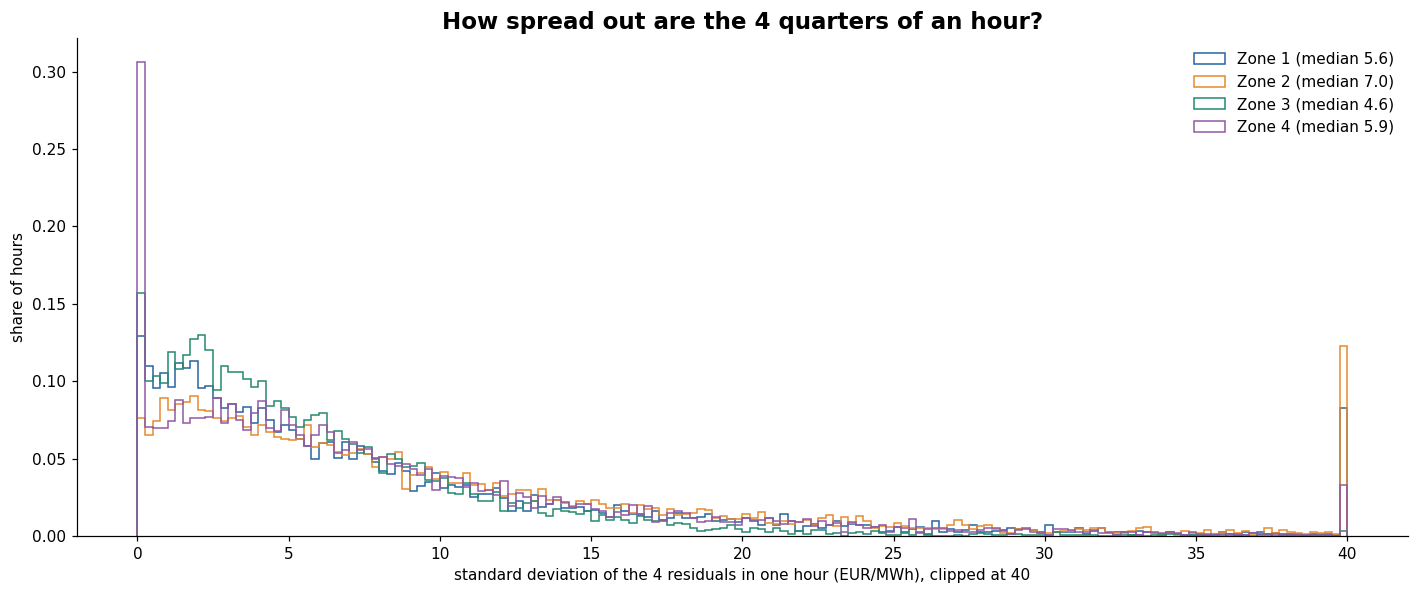

In [42]:
# ---------------------------------------------------------------------------
# Within-hour variation (1). How spread out are the 4 quarters of an hour?
# ---------------------------------------------------------------------------
RQ = H[['r1', 'r2', 'r3', 'r4']].to_numpy()

# Three ways to measure the spread of the 4 residuals of one hour
H['within_std'] = RQ.std(axis=1)                          # typical distance of the 4 quarters from the hourly price
H['within_range'] = RQ.max(axis=1) - RQ.min(axis=1)       # highest quarter − lowest quarter
H['tilt'] = RQ[:, 3] - RQ[:, 0]                           # Q4 − Q1: > 0 the price rises through the hour

# How much of the variation is a straight line through the hour (a tilt)?
# Project the 4 residuals on a straight line (−3, −1, +1, +3) and compare with the total variation
LINE = np.array([-3, -1, 1, 3]) / np.sqrt(20)
total_sq = (RQ ** 2).sum(axis=1)
H['tilt_share'] = np.where(total_sq > 1e-9, (RQ @ LINE) ** 2 / np.where(total_sq > 1e-9, total_sq, 1), np.nan)


def stats_row(s):
    s = s.dropna()
    return pd.Series({'mean': s.mean(), 'median': s.median(), 'p10': s.quantile(0.10),
                      'p90': s.quantile(0.90), 'p99': s.quantile(0.99), 'max': s.max()})


print('Spread of the 4 quarters inside one hour (EUR/MWh), per zone:')
for col, label in [('within_std', 'Standard deviation of the 4 residuals'),
                   ('within_range', 'Range: highest quarter − lowest quarter')]:
    print(f'\n■ {label}')
    display(H.groupby('market_id')[col].apply(stats_row).unstack().round(2))

print('\n■ Share of the within-hour variation that is a straight tilt (1 = perfectly straight line)')
display(H.groupby('market_id').tilt_share.agg(
    median='median', mean='mean',
    pct_hours_mostly_straight=lambda s: 100 * (s > 0.8).mean()).round(2))

# Distribution of the within-hour std, one line per zone
fig, ax = plt.subplots(figsize=(13, 5.5))
bins = np.linspace(0, 40, 161)
for z, c in zip(ZONES, COLORS):
    s = H.loc[H.market_id == z, 'within_std']
    ax.hist(s.clip(upper=40), bins=bins, histtype='step', lw=2, color=c, density=True,
            label=f'{z} (median {s.median():.1f})')
ax.set(xlabel='standard deviation of the 4 residuals in one hour (EUR/MWh), clipped at 40', ylabel='share of hours')
ax.set_title('How spread out are the 4 quarters of an hour?', fontsize=15, fontweight='bold')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [14]:
# ---------------------------------------------------------------------------
# 0g (cont.). How heavy are the tails? Observed vs Gaussian-expected exceedances
# ---------------------------------------------------------------------------
rows = []
for z in ZONES:
    x = df.loc[df.market_id == z, 'residual']
    sd = x.std()
    for k in [2, 3, 4]:
        rows.append({'market_id': z, 'threshold': f'|res| > {k}σ',
                     'observed_%': 100 * (x.abs() > k * sd).mean(),
                     'gaussian_expected_%': 100 * 2 * stats.norm.sf(k)})   # two-sided tail of N(0,1)
tails = pd.DataFrame(rows)
tails['ratio'] = tails['observed_%'] / tails['gaussian_expected_%']
tails.set_index(['market_id', 'threshold']).round(3)

observed_%  gaussian_expected_%    ratio
market_id threshold                                           
Zone 1    |res| > 2σ       5.036                4.550    1.107
          |res| > 3σ       2.027                0.270    7.508
          |res| > 4σ       0.926                0.006  146.178
Zone 2    |res| > 2σ       5.484                4.550    1.205
          |res| > 3σ       2.162                0.270    8.006
          |res| > 4σ       0.920                0.006  145.190
Zone 3    |res| > 2σ       5.809                4.550    1.277
          |res| > 3σ       1.821                0.270    6.743
          |res| > 4σ       0.657                0.006  103.707
Zone 4    |res| > 2σ       5.859                4.550    1.288
          |res| > 3σ       2.033                0.270    7.531
          |res| > 4σ       0.726                0.006  114.572

> **What we found**
>
> **Central values and spread (0a)**
> - **Levels differ a lot by zone:** mean 101 / 115 / 132 / 71 EUR/MWh for zones 1–4. Means and medians are close (within ≈ 4 EUR/MWh), so the *bulk* of each distribution is fairly symmetric.
> - **Zone 3 is the narrowest** (std 37, IQR 43, never below 0). **Zone 4 has the widest middle** (IQR 86, from 22 to 108 EUR/MWh) because it spends many hours near 0.
>
> **Tails and extremes (0a, 0c)**
> - **Zones 1 and 2 have extremely heavy tails:** excess kurtosis ≈ 10–11, against 0 for a Gaussian. Their 1st–99th percentile range is ≈ −17 to 254 and −12 to 266, but the full range is −500 to 747.
> - **The −500 floor was hit on exactly two days, 26 Apr and 1 May 2026** (a Sunday and a public holiday with strong solar). Zones 1, 2 and 4 hit it at the same midday hours, so these three markets are coupled.
> - **Price spikes above 400 EUR/MWh cluster in a few late-June evenings** (18, 23, 24 and 30 June 2026, up to 747 in Zone 1), plus 12–13 Aug, the only days when all three non-calm zones spiked together.
>
> **The residual, our target (0b)**
> - **Centred at 0 with a median of 0, but very heavy-tailed:** excess kurtosis 6–25. Typical residuals are small (IQR ≈ 7–10 EUR/MWh), but they reach ±190–245 EUR/MWh.
> - **Only ≈ 5–7% of the total price variance happens inside the hour.** The other ≈ 93–95% is the hour-to-hour level, which is given. Our task is to predict a small part of the variance very precisely.
>
> **Distribution of the hourly prices (0d, 0e, 0f)**
> - **A Gaussian does not fit any zone well** (KS gap 0.07–0.11). The QQ plots bend away from the straight line at both ends: fat tails, plus a **pile-up at ≈ 0 EUR/MWh** (4.8% of hours in Zone 1 and 9.1% in Zone 4 are within ±2 EUR/MWh of zero). These are the solar hours where the price sits at the floor of normal bidding.
> - **A 2-component Gaussian mixture fits best in zones 1–3** (best AIC; KS down to 0.02–0.04). In zones 1 and 2 it splits into a narrow "normal" regime (≈ 75–80% of hours) and a wide, spiky regime. **Zone 4 is visibly bimodal**: a cluster near 0–40 (midday solar) and one near 90–110. Even so, no smooth curve fits it well, because of the pile-up at 0; Student-t edges out the mixture on AIC.
> - **By hour, the distribution changes shape, not just level.** Midday hours (12–16) are skewed toward low prices (skewness down to −3.3 at hour 15 in Zone 4), meaning a long tail of very cheap or negative hours. Evening hours (20–23) are skewed toward high prices (+2 to +3 in zones 1 and 2), meaning a long tail of spikes. Night hours are close to symmetric.
>
> **Distribution of the residuals (0g)**
> - **The residuals are far from Gaussian.** Moves beyond 3σ happen ≈ 7–8× more often than a Gaussian predicts, and beyond 4σ ≈ 100–150× more often.
> - **Laplace and Student-t fit much better** (KS ≈ 0.03–0.06 vs 0.10–0.15 for Gaussian). Student-t is best in zones 1, 2 and 4, and Laplace in Zone 3.
> - **Implication:** use **robust statistics** (medians, MAD), **absolute-error (L1) losses**, and Spearman rather than Pearson correlations where spikes could dominate. This matches the challenge metric (MAE), because minimising absolute error is the natural choice when errors are Laplace-like.

**→ With the numbers in hand: what does the hidden movement inside the hour look like?**

---
# 1. The hourly price hides a lot

The black steps are what we get: one price per hour. The coloured line is what we need: the real 15-minute prices. The gap between them is the residual, and it is what this whole challenge is about.

The top panel shows 15 days in August 2026 for Zone 1; the bottom panel zooms in on 2 days so the movement inside each hour is visible. The same plot for the other zones is in **Appendix C**. Change `WINDOW_START` to explore another period (it must end before September).

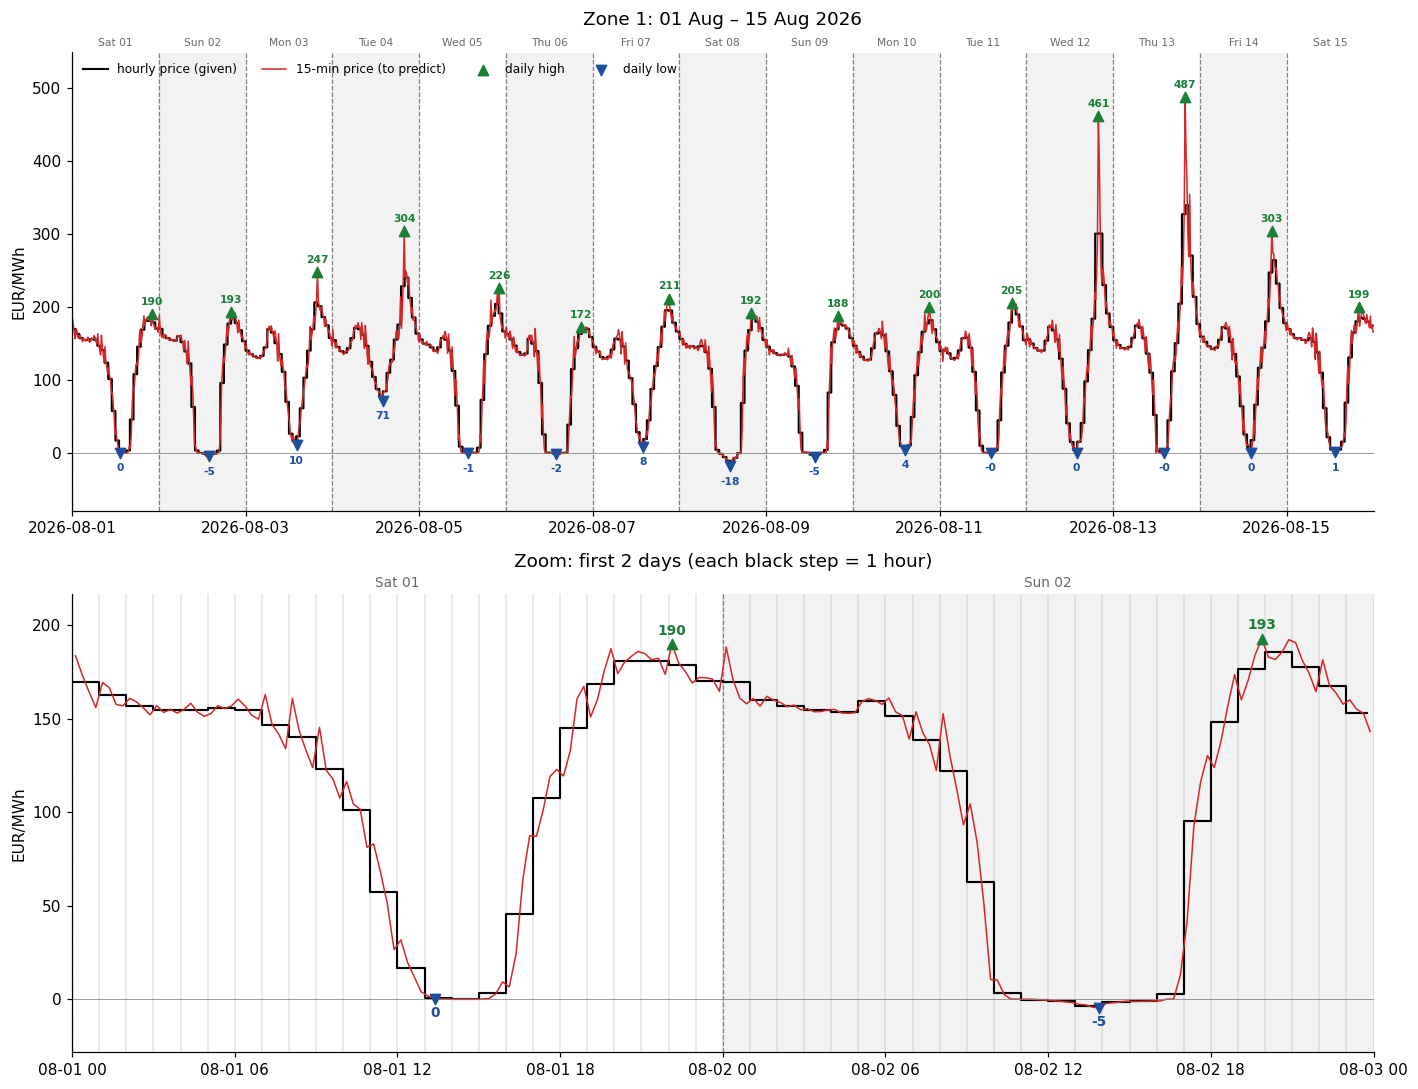

In [15]:
# ---------------------------------------------------------------------------
# 1a. 15 days of real prices: 15-min price vs the hourly price we are given
# ---------------------------------------------------------------------------
WINDOW_START = pd.Timestamp('2026-08-01')
WINDOW_DAYS, ZOOM_DAYS = 15, 2
assert WINDOW_START + pd.Timedelta(days=WINDOW_DAYS - 1) <= EDA_END, 'window must end before September'

HIGH_COLOR, LOW_COLOR = '#1a7f37', '#1f4e9c'     # green = daily high, blue = daily low
DAY_SHADE = '#f2f2f2'                            # grey band on every other day


def plot_window(zone, color, start=WINDOW_START, days=WINDOW_DAYS, zoom_days=ZOOM_DAYS):
    # Top: full window. Bottom: zoom. Black step = hourly price, coloured line = 15-min price.
    end = start + pd.Timedelta(days=days)
    w = df[(df.market_id == zone) & (df.delivery_date >= start) & (df.delivery_date < end)].copy()
    w['time'] = (w.delivery_date + pd.to_timedelta(w.hour_index - 1, unit='h')
                 + pd.to_timedelta((w.quarter_index - 1) * 15, unit='min'))
    w['plot_time'] = w.time + pd.Timedelta(minutes=7.5)          # plotted at quarter centre
    w = w.sort_values('time')
    zoom_end = start + pd.Timedelta(days=zoom_days)

    # Highest and lowest 15-min price of each day
    highs = w.loc[w.groupby('delivery_date').price_eur_mwh.idxmax()]
    lows = w.loc[w.groupby('delivery_date').price_eur_mwh.idxmin()]

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(13, 10))
    for ax, part_end, label_size in [(top, end, 7), (bottom, zoom_end, 9)]:
        part = w[w.time < part_end]
        day_list = pd.date_range(start, part_end - pd.Timedelta(days=1))

        # Day separation: alternating grey bands, a line at each midnight, the date on top
        for i, d in enumerate(day_list):
            if i % 2 == 1:
                ax.axvspan(d, d + pd.Timedelta(days=1), color=DAY_SHADE, zorder=0)
            ax.axvline(d, color='grey', lw=0.8, ls='--', zorder=1)
            ax.text(d + pd.Timedelta(hours=12), 1.01, f'{d:%a %d}', transform=ax.get_xaxis_transform(),
                    ha='center', va='bottom', fontsize=label_size, color='dimgrey')

        ax.step(part.time, part.hourly_price, where='post', color='k', lw=1.4, label='hourly price (given)')
        ax.plot(part.plot_time, part.price_eur_mwh, color=color, lw=1, label='15-min price (to predict)')

        # Mark and label the daily highs and lows
        hi, lo = highs[highs.time < part_end], lows[lows.time < part_end]
        ax.scatter(hi.plot_time, hi.price_eur_mwh, marker='^', s=45, color=HIGH_COLOR, zorder=5, label='daily high')
        ax.scatter(lo.plot_time, lo.price_eur_mwh, marker='v', s=45, color=LOW_COLOR, zorder=5, label='daily low')
        for _, r in hi.iterrows():
            ax.annotate(f'{r.price_eur_mwh:.0f}', (r.plot_time, r.price_eur_mwh), xytext=(0, 6),
                        textcoords='offset points', ha='center', fontsize=label_size, color=HIGH_COLOR, fontweight='bold')
        for _, r in lo.iterrows():
            ax.annotate(f'{r.price_eur_mwh:.0f}', (r.plot_time, r.price_eur_mwh), xytext=(0, -12),
                        textcoords='offset points', ha='center', fontsize=label_size, color=LOW_COLOR, fontweight='bold')

        ax.axhline(0, color='grey', lw=0.5)
        ax.set_xlim(start, part_end)
        ax.margins(y=0.12)                                       # room for the labels
        ax.set_ylabel('EUR/MWh')

    top.set_title(f'{zone}: {start:%d %b} – {end - pd.Timedelta(days=1):%d %b %Y}', pad=18)
    top.legend(frameon=False, ncol=4, loc='upper left', fontsize=8)
    bottom.set_title(f'Zoom: first {zoom_days} days (each black step = 1 hour)', pad=18)
    for h in pd.date_range(start, zoom_end, freq='h'):
        bottom.axvline(h, color='grey', lw=0.2, zorder=1)
    plt.tight_layout(); plt.show()


plot_window(ZONES[0], '#d62728')

**How wrong is the flat guess?** Its error on a quarter is exactly the size of that quarter's residual, so the flat-guess MAE is simply the average size of the residuals (official averaging: per day and zone, then per zone, then over zones).

In [16]:
# ---------------------------------------------------------------------------
# 1b. The size of the problem: flat-guess MAE per zone
# ---------------------------------------------------------------------------
flat_mae = official_mae(H, 'abs_res')
FLAT_SCORE = flat_mae.mean()

size = pd.DataFrame({
    'flat-guess MAE': flat_mae,
    'median |residual|': df.groupby('market_id').abs_res.median(),
    'mean |price|': df.groupby('market_id').price_eur_mwh.apply(lambda s: s.abs().mean()),
})
size['MAE as % of price'] = 100 * size['flat-guess MAE'] / size['mean |price|']
print(f'The flat guess is off by {FLAT_SCORE:.2f} EUR/MWh on average (equal weight per zone).')
size.round(2)

The flat guess is off by 7.30 EUR/MWh on average (equal weight per zone).


,flat-guess MAE,median |residual|,mean |price|,MAE as % of price
market_id,,,,
Zone 1,7.67,3.76,102.72,7.47
Zone 2,9.08,4.80,116.61,7.79
Zone 3,5.29,3.25,132.23,4.00
Zone 4,7.14,3.92,72.44,9.86


> **What we found**
>
> - **The flat guess is off by ≈ 7.30 EUR/MWh on average**, which is 4–10% of the average price. Zone 2 is the hardest (9.08) and Zone 3 the easiest (5.29).
> - **The hidden movement is not random noise.** In the window above, the 15-min price starts each hour on one side of the step and ends on the other, again and again.
> - **A few big hours drive the error:** the median |residual| is only about half the mean.

**→ So what does the hidden movement look like?**

---
# 2. Prices slide toward the next hour

Averaging the residuals of each quarter position (Q1–Q4) over the whole year, hour by hour, shows the typical shape. Where Q1 is below Q4 the price rises inside the hour; where Q1 is above Q4 it falls.

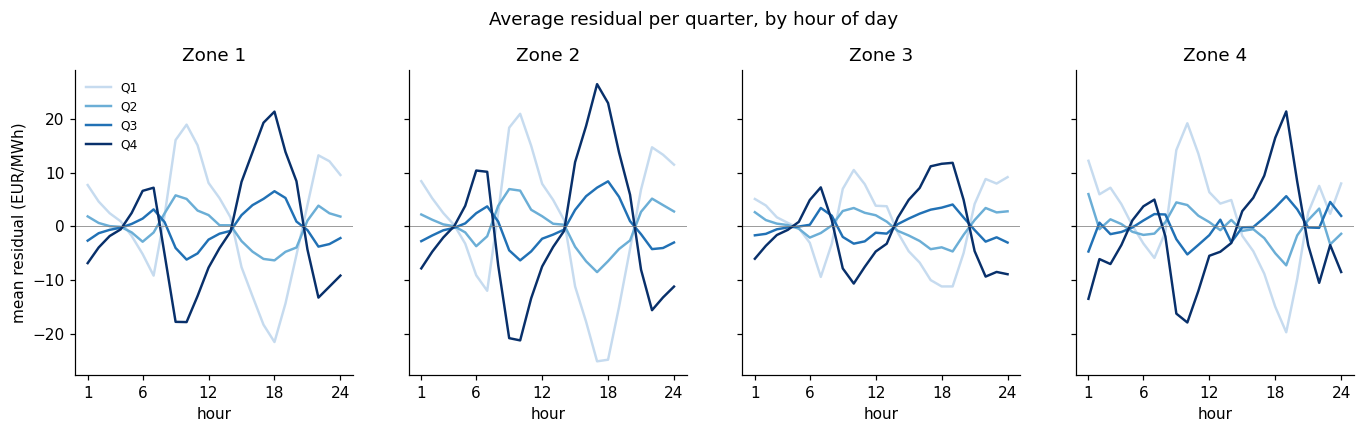

In [17]:
# ---------------------------------------------------------------------------
# 2a. Average Q1..Q4 residual for each hour of the day, per zone
# ---------------------------------------------------------------------------
def quarter_lines(frame, title=None, axes=None):
    # Mean residual of Q1..Q4 vs hour of day, one panel per zone. Returns the mean shape.
    avg = frame.groupby(['market_id', 'hour_index', 'quarter_index']).residual.mean()
    if axes is None:
        fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
        fig.suptitle(title, y=1.03)
    for ax, z in zip(axes, ZONES):
        for q in range(1, 5):
            ax.plot(range(1, 25), avg[z].xs(q, level='quarter_index'),
                    color=Q_COLORS[q - 1], lw=1.6, label=f'Q{q}')
        ax.axhline(0, color='grey', lw=0.5)                 # 0 = the hourly price
        ax.set(title=z, xlabel='hour', xticks=[1, 6, 12, 18, 24])
    axes[0].set_ylabel('mean residual (EUR/MWh)')
    axes[0].legend(frameon=False, fontsize=8)
    return avg


avg_shape = quarter_lines(df, 'Average residual per quarter, by hour of day')
plt.show()

The same data as one continuous line over the 96 quarters of the day. Grey lines are hour boundaries. A **sawtooth** is a ramp inside each hour that resets at the boundary.

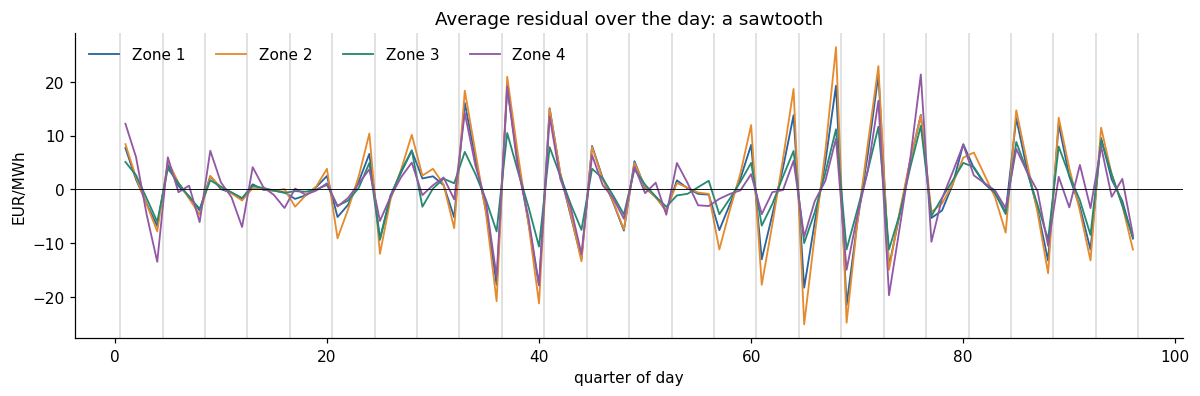

Mean |residual| (flat-guess error) by quarter position:


quarter_index,Q1,Q2,Q3,Q4
market_id,,,,
Zone 1,11.48,3.91,3.94,11.37
Zone 2,13.19,4.96,4.82,13.36
Zone 3,7.18,3.38,3.21,7.40
Zone 4,9.95,4.27,4.23,10.11


In [18]:
# ---------------------------------------------------------------------------
# 2b. The sawtooth: average residual over the 96 quarters of the day
# ---------------------------------------------------------------------------
profile_96 = df.groupby(['qod', 'market_id']).residual.mean().unstack()   # 96 × 4 zones
ax = profile_96.plot(figsize=(13, 3.6), color=COLORS, lw=1.2)
for h in range(0, 97, 4):
    ax.axvline(h + 0.5, color='grey', lw=0.3)
ax.axhline(0, color='k', lw=0.6)
ax.set(title='Average residual over the day: a sawtooth', xlabel='quarter of day', ylabel='EUR/MWh')
ax.legend(ncol=4, frameon=False)
plt.show()

# Where does the error sit inside the hour?
print('Mean |residual| (flat-guess error) by quarter position:')
df.groupby(['market_id', 'quarter_index']).abs_res.mean().unstack().add_prefix('Q').round(2)

> **What we found**
>
> - **There is a strong, systematic pattern with the same timing in all four zones.**
> - **Morning down-ramp (≈ hours 9–12):** Q1 high, Q4 low, so prices **fall** inside the hour as solar arrives.
> - **Evening up-ramp (≈ hours 15–20):** Q1 low, Q4 high, so prices **rise** inside the hour as solar fades. The early-morning ramp (≈ hours 6–8) does the same on a smaller scale.
> - **Night hours are close to flat.**
> - **The shape is a tilted line, not a curve:** Q1 and Q4 carry about 3× the deviation of Q2 and Q3 (e.g. Zone 2: 13.2 and 13.4 vs 5.0 and 4.8).
> - **Over the day it forms a sawtooth:** the price moves in the direction of the daily ramp inside each hour, then jumps back at the boundary. This is likely a legacy of hourly bidding blocks.
> - **Amplitudes reach ±20–25 EUR/MWh around hours 17–19**, against near zero at night.

**→ If prices slide toward the next hour, can the next hour predict the slide?**

---
# 3. The slope between hours explains most of the shape

`slope = next hour − previous hour` measures the direction and steepness of the daily ramp around an hour. `Q4 − Q1` measures the tilt inside the hour. If the two line up, the hourly curve alone predicts most of the shape. (Hours 1 and 24 have only a one-sided slope; chapter 4 looks at them.)

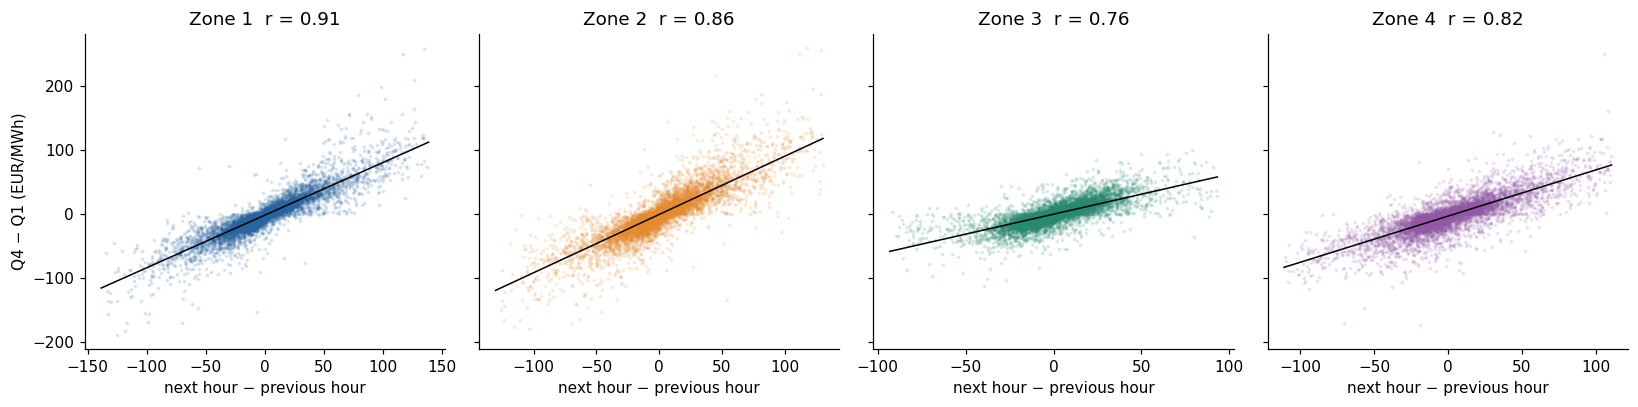

,corr,corr_spearman,fit_slope
market_id,,,
Zone 1,0.91,0.93,0.82
Zone 2,0.86,0.89,0.91
Zone 3,0.76,0.80,0.63
Zone 4,0.82,0.81,0.72


In [19]:
# ---------------------------------------------------------------------------
# 3a. Slope vs tilt inside the hour, per zone
# ---------------------------------------------------------------------------
S = H.dropna(subset=['slope'])                    # hours 2–23 (two-sided slope)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
slope_rows = []
for ax, z, c in zip(axes, ZONES, COLORS):
    p = S[S.market_id == z]
    lim = p.slope.abs().quantile(0.99)            # hide the 1% largest slopes in the plot only
    pc = p[p.slope.abs() <= lim]
    ax.scatter(pc.slope, pc.q4_minus_q1, s=2, alpha=0.12, color=c)
    b = np.polyfit(p.slope, p.q4_minus_q1, 1)     # least-squares line on all points
    xs = np.linspace(-lim, lim, 2)
    ax.plot(xs, np.polyval(b, xs), color='k', lw=1)
    r = p.slope.corr(p.q4_minus_q1)
    slope_rows.append({'market_id': z, 'corr': r,
                       'corr_spearman': p.slope.corr(p.q4_minus_q1, method='spearman'),
                       'fit_slope': b[0]})
    ax.set(title=f'{z}  r = {r:.2f}', xlabel='next hour − previous hour')
axes[0].set_ylabel('Q4 − Q1 (EUR/MWh)')
plt.tight_layout(); plt.show()
pd.DataFrame(slope_rows).set_index('market_id').round(2)

**The first win: a rule with no training.** Tilt the four quarters along the slope:

`residual_q = k × slope_c × offset_q`, with offsets (−0.375, −0.125, +0.125, +0.375)

`slope_c` is half the two-sided slope (one-sided at the day edges). The offsets sum to zero, so the hourly average is preserved automatically. `k = 1` is a straight line between hour centres; larger `k` lets the price move more inside the hour. This is **descriptive only**: k is chosen on the same data, so it is not a validation score.

In [20]:
# ---------------------------------------------------------------------------
# 3b. MAE of the slope rule for several scale factors k
# ---------------------------------------------------------------------------
K_GRID = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]
slope_c = H.slope_c.to_numpy()[:, None]

k_tab = {'flat': flat_mae}
for k in K_GRID:
    err = np.abs(R - k * slope_c * OFFSETS).mean(axis=1)            # error of each hour
    k_tab[f'slope × {k:g}'] = official_mae(H.assign(e=err), 'e')
k_tab = pd.DataFrame(k_tab)
k_tab.loc['MEAN'] = k_tab.mean()                                     # equal weight per zone

SLOPE1_SCORE, SLOPE2_SCORE = k_tab.loc['MEAN', 'slope × 1'], k_tab.loc['MEAN', 'slope × 2']
print(f'Flat {FLAT_SCORE:.2f}  →  slope × 1 {SLOPE1_SCORE:.2f} ({SLOPE1_SCORE / FLAT_SCORE - 1:+.0%})'
      f'  →  slope × 2 {SLOPE2_SCORE:.2f} ({SLOPE2_SCORE / FLAT_SCORE - 1:+.0%})')
best_k = k_tab.drop(index='MEAN').drop(columns='flat').idxmin(axis=1)
print('Best k per zone:', best_k.to_dict())
k_tab.round(2)

Flat 7.30  →  slope × 1 5.32 (-27%)  →  slope × 2 4.45 (-39%)
Best k per zone: {'Zone 1': 'slope × 2', 'Zone 2': 'slope × 2.5', 'Zone 3': 'slope × 2', 'Zone 4': 'slope × 2'}


,flat,slope × 1,slope × 1.5,slope × 2,slope × 2.5,slope × 3,slope × 3.5,slope × 4
market_id,,,,,,,,
Zone 1,7.67,5.10,4.20,3.79,3.96,4.63,5.63,6.82
Zone 2,9.08,6.70,5.83,5.29,5.19,5.51,6.15,7.04
Zone 3,5.29,4.05,3.78,3.78,4.04,4.50,5.12,5.85
Zone 4,7.14,5.42,4.98,4.94,5.29,5.95,6.82,7.82
MEAN,7.30,5.32,4.70,4.45,4.62,5.15,5.93,6.88


> **What we found**
>
> - **Yes: the slope explains most of the shape.** Slope and tilt line up clearly: r = 0.91 / 0.86 / 0.76 / 0.82 for zones 1–4, with similar rank (Spearman) correlations, so it is not driven by spikes. Zone 3 is the weakest.
> - **A rule with no training cuts the error by ≈ 39%:** flat **7.30** → slope × 1 **5.32** (−27%) → slope × 2 **4.45** (−39%).
> - **Prices move about twice as much inside the hour as a straight line would suggest.** The fitted tilt per unit of slope is 0.62–0.91, against 0.375 for linear interpolation: most of the step between two hourly blocks happens *inside* the hour.
> - **The best k differs by zone** (see "Best k per zone" above; Zone 2 wants a stronger tilt), so k should be a per-zone parameter learned on the training split.

**→ That's most of the story. What's left?**

---
# 4. Where the simple rule breaks

The plot below shows the error that is **left** after the slope rule (k = 2), hour by hour, against the flat guess. The gaps between the two lines are the hours the rule already fixes; whatever remains is what the next steps must explain. Five complications follow, each kept short.

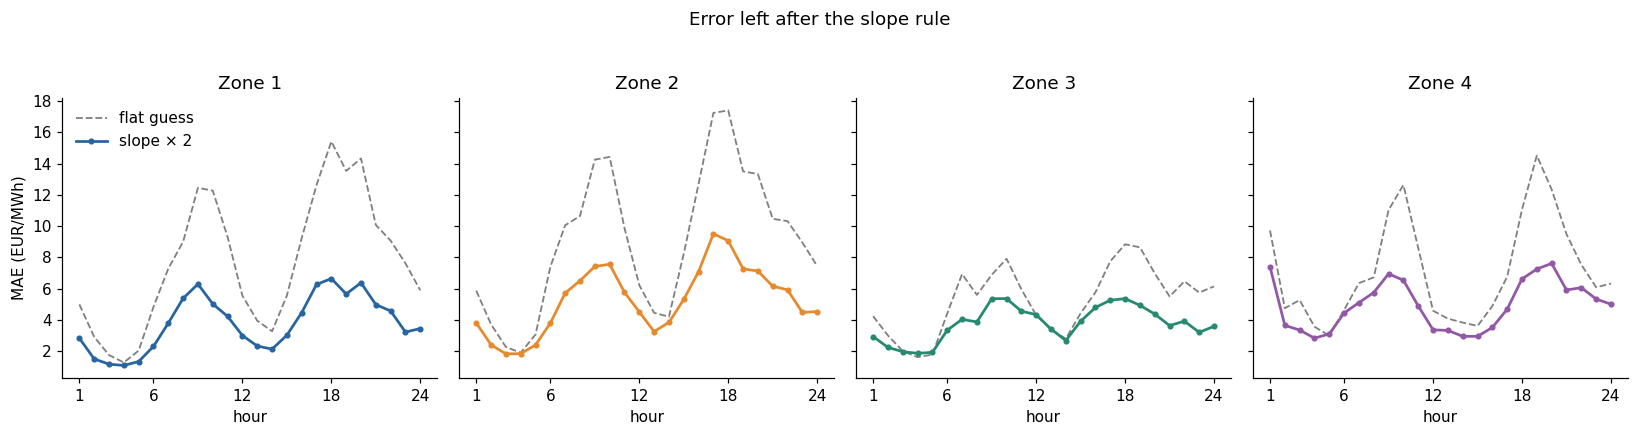

In [21]:
# ---------------------------------------------------------------------------
# 4. What's left after the slope rule (k = 2), by hour and zone
# ---------------------------------------------------------------------------
H['err_slope2'] = np.abs(R - 2 * slope_c * OFFSETS).mean(axis=1)
left = H.groupby(['market_id', 'hour_index'])[['abs_res', 'err_slope2']].mean()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, z, c in zip(axes, ZONES, COLORS):
    ax.plot(left.loc[z].index, left.loc[z].abs_res, color='grey', ls='--', lw=1.2, label='flat guess')
    ax.plot(left.loc[z].index, left.loc[z].err_slope2, color=c, marker='.', lw=1.8, label='slope × 2')
    ax.set(title=z, xlabel='hour', xticks=[1, 6, 12, 18, 24])
axes[0].set_ylabel('MAE (EUR/MWh)')
axes[0].legend(frameon=False)
fig.suptitle("Error left after the slope rule", y=1.03)
plt.tight_layout(); plt.show()

### 4a. Season: summer shapes are bigger and shifted by solar

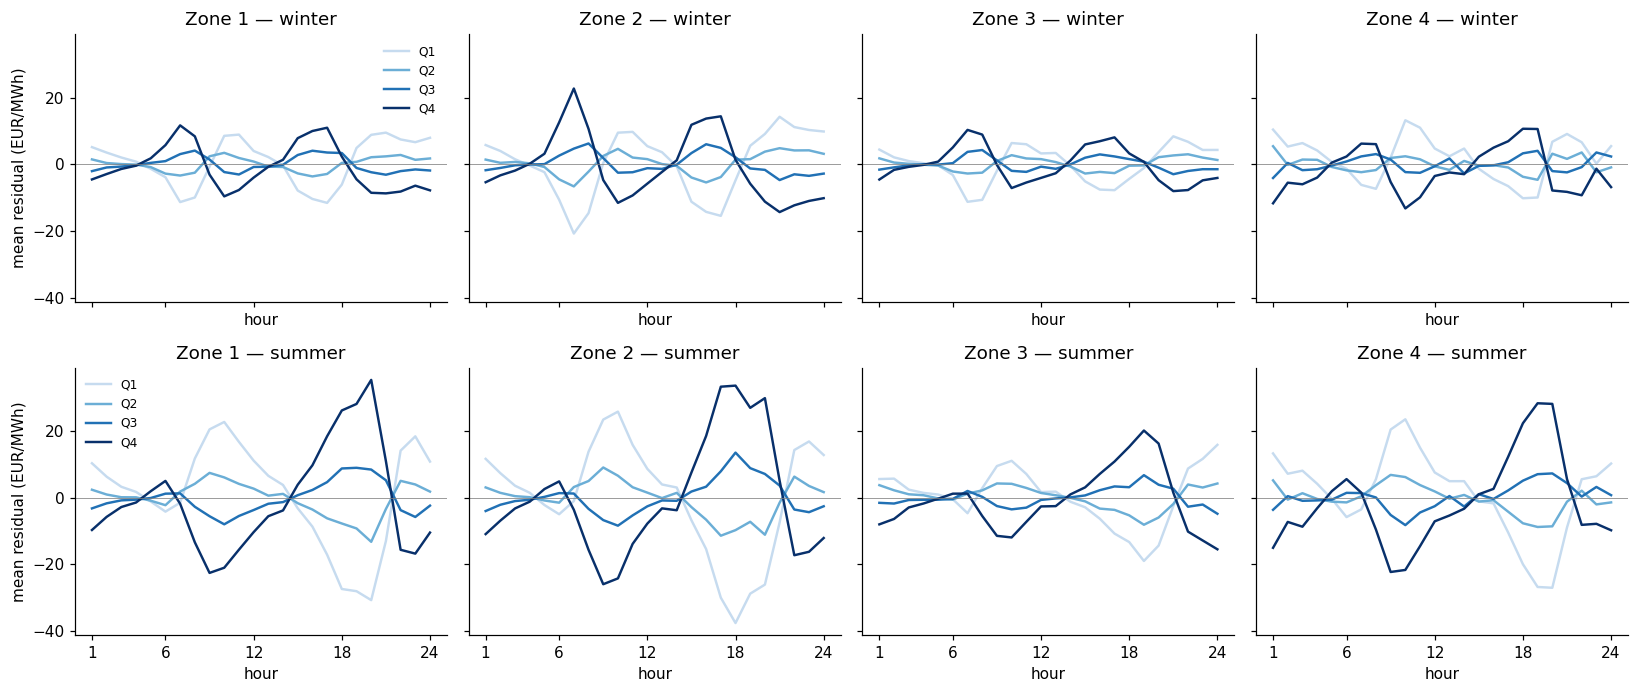

,|winter − summer|,mean |avg shape|,ratio
market_id,,,
Zone 1,6.89,5.88,1.17
Zone 2,7.69,7.02,1.10
Zone 3,4.00,3.95,1.01
Zone 4,4.59,4.97,0.92


Error left after slope × 2, by season:


season,autumn,winter,spring,summer
market_id,,,,
Zone 1,4.54,2.65,4.43,3.78
Zone 2,5.76,4.20,5.89,5.47
Zone 3,3.20,2.42,4.32,4.95
Zone 4,4.97,4.07,5.71,5.00


In [22]:
# ---------------------------------------------------------------------------
# 4a. Winter (top) vs summer (bottom), and how different the shapes are
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharey=True, sharex=True)
quarter_lines(df[df.season == 'winter'], axes=axes[0])
quarter_lines(df[df.season == 'summer'], axes=axes[1])
for ax in axes[0]: ax.set_title(ax.get_title() + ' — winter')
for ax in axes[1]: ax.set_title(ax.get_title() + ' — summer')
plt.tight_layout(); plt.show()


def shape_gap(col, a, b):
    # |average shape of group a − group b|, relative to the size of the overall average shape.
    # A ratio near 1 means the groups differ as much as the shape itself is large.
    cells = ['market_id', 'hour_index', 'quarter_index']
    sa = df[df[col] == a].groupby(cells).residual.mean()
    sb = df[df[col] == b].groupby(cells).residual.mean()
    gap = (sa - sb).abs().groupby('market_id').mean()
    shape_size = avg_shape.abs().groupby('market_id').mean()
    return pd.DataFrame({f'|{a} − {b}|': gap, 'mean |avg shape|': shape_size, 'ratio': gap / shape_size})


display(shape_gap('season', 'winter', 'summer').round(2))
print('Error left after slope × 2, by season:')
H.groupby(['market_id', 'season']).err_slope2.mean().unstack()[SEASONS].round(2)

### 4b. Weekends: same timing, smaller moves
The full weekday/weekend price comparison is in **Appendix B (E1)**; the shape version is in **Appendix D**.

In [23]:
# ---------------------------------------------------------------------------
# 4b. Weekday vs weekend: shape difference and error size
# ---------------------------------------------------------------------------
display(shape_gap('day_type', 'weekday', 'weekend').round(2))
print('Flat-guess error and error left after slope × 2, weekday vs weekend:')
H.groupby(['market_id', 'day_type'])[['abs_res', 'err_slope2']].mean().unstack().round(2)

,|weekday − weekend|,mean |avg shape|,ratio
market_id,,,
Zone 1,2.69,5.88,0.46
Zone 2,3.01,7.02,0.43
Zone 3,2.07,3.95,0.52
Zone 4,2.07,4.97,0.42


Flat-guess error and error left after slope × 2, weekday vs weekend:


abs_res         err_slope2        
day_type  weekday weekend    weekday weekend
market_id                                   
Zone 1       8.44    5.74       4.10    2.99
Zone 2       9.83    7.17       5.69    4.27
Zone 3       5.34    5.18       3.67    4.07
Zone 4       7.70    5.72       5.32    3.97

### 4c. Zones: same timing, different details
A slope rule can only draw a straight ramp. Here every hour is classified by the direction of its 3 steps Q1→Q2→Q3→Q4: **monotonic** (all the same way), **one turn**, **zigzag** (up-down-up or down-up-down), or **has flat step** (two equal quarters).

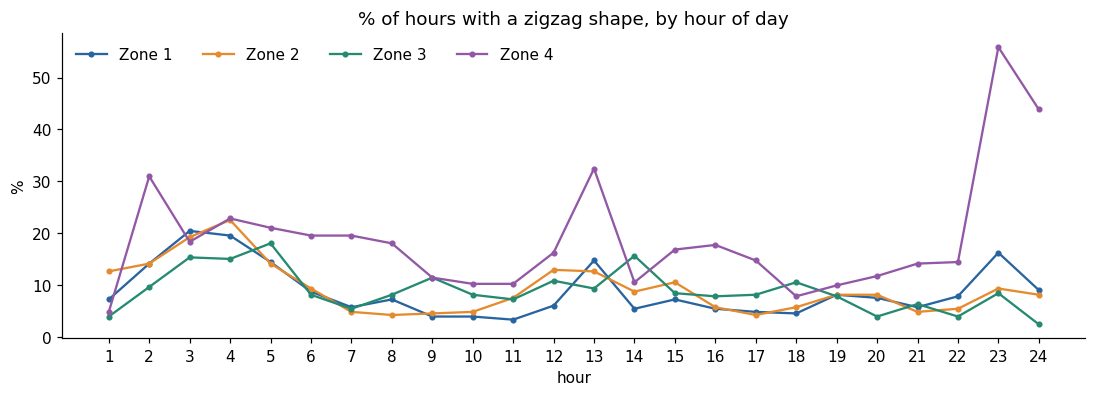

pattern,has flat step,monotonic,one turn,zigzag
market_id,,,,
Zone 1,2.6,72.4,16.2,8.8
Zone 2,3.1,68.3,19.3,9.2
Zone 3,25.0,48.6,17.5,8.9
Zone 4,10.4,51.9,18.9,18.9
ALL,10.3,60.3,18.0,11.4


Median within-hour range (EUR/MWh) by pattern: are zigzags big or just noise?


pattern,has flat step,monotonic,one turn,zigzag
market_id,,,,
Zone 1,0.1,19.9,6.1,5.8
Zone 2,2.6,24.4,9.0,7.9
Zone 3,5.0,17.7,8.3,7.0
Zone 4,0.1,20.4,12.6,14.9


Price precision: why Zone 3 has so many flat steps


,integer_pct,unique_values
market_id,,
Zone 1,5.2,13927
Zone 2,4.5,13948
Zone 3,15.3,9574
Zone 4,11.2,13589


In [24]:
# ---------------------------------------------------------------------------
# 4c. Shape patterns per zone, and where zigzags happen
# ---------------------------------------------------------------------------
steps = np.sign(np.diff(R, axis=1))                # +1 up, −1 down, 0 flat
H['pattern'] = np.select(
    [(steps == 0).any(axis=1),
     (steps[:, 0] == steps[:, 1]) & (steps[:, 1] == steps[:, 2]),
     (steps[:, 0] != steps[:, 1]) & (steps[:, 1] != steps[:, 2])],
    ['has flat step', 'monotonic', 'zigzag'], default='one turn')
H['zigzag_kind'] = np.where(H.pattern == 'zigzag',
                            np.where(steps[:, 0] > 0, 'up-down-up', 'down-up-down'), '')

zigzag_by_hour = H.assign(z=H.pattern.eq('zigzag')).groupby(['hour_index', 'market_id']).z.mean().unstack() * 100
ax = zigzag_by_hour.plot(figsize=(12, 3.6), color=COLORS, marker='.')
ax.set(title='% of hours with a zigzag shape, by hour of day', xlabel='hour', ylabel='%', xticks=range(1, 25))
ax.legend(ncol=4, frameon=False)
plt.show()

pattern_pct = pd.crosstab(H.market_id, H.pattern, normalize='index') * 100
pattern_pct.loc['ALL'] = H.pattern.value_counts(normalize=True) * 100
display(pattern_pct.round(1))
print('Median within-hour range (EUR/MWh) by pattern: are zigzags big or just noise?')
display(H.groupby(['market_id', 'pattern'])['range'].median().unstack().round(1))
print('Price precision: why Zone 3 has so many flat steps')
df.groupby('market_id').price_eur_mwh.agg(
    integer_pct=lambda s: 100 * (s == s.round(0)).mean(),
    unique_values='nunique').round(1)

### 4d. Day edges: hours 1 and 24 have only half a slope
The next day's prices are not given, so hour 24 has no "next hour" and hour 1 no "previous hour" within the day.

In [25]:
# ---------------------------------------------------------------------------
# 4d. How well does a one-sided slope work at the edges?
# ---------------------------------------------------------------------------
def edge_corr(frame):
    return frame.groupby('market_id')[['step', 'q4_minus_q1']].apply(lambda p: p.step.corr(p.q4_minus_q1))


first = H[H.hour_index == 1].assign(step=lambda x: x.next_hour - x.hourly_price)
last = H[H.hour_index == 24].assign(step=lambda x: x.hourly_price - x.prev_hour)
middle = S.groupby('market_id')[['slope', 'q4_minus_q1']].apply(lambda p: p.slope.corr(p.q4_minus_q1))
pd.DataFrame({'hours 2–23: corr(slope, Q4−Q1)': middle,
              'hour 1: corr(next − current, Q4−Q1)': edge_corr(first),
              'hour 24: corr(current − prev, Q4−Q1)': edge_corr(last)}).round(2)

,"hours 2–23: corr(slope, Q4−Q1)","hour 1: corr(next − current, Q4−Q1)","hour 24: corr(current − prev, Q4−Q1)"
market_id,,,
Zone 1,0.91,0.68,0.74
Zone 2,0.86,0.54,0.45
Zone 3,0.76,0.40,0.45
Zone 4,0.82,0.32,0.48


### 4e. Negative prices: smaller shapes, not bigger
Counts and timing of negative prices are in **Appendix A**. Here: does the shape behave differently in hours that are fully negative, or that cross zero?

In [26]:
# ---------------------------------------------------------------------------
# 4e. Intra-hour movement in positive, negative and zero-crossing hours
# ---------------------------------------------------------------------------
H['hour_type'] = np.select([H.n_neg == 0, H.n_neg == 4], ['all positive', 'all negative'], 'crosses zero')
(H.groupby(['market_id', 'hour_type'])
   .agg(hours=('abs_res', 'size'), mean_abs_residual=('abs_res', 'mean'))
   .unstack('hour_type').round(2))

hours                           mean_abs_residual  \
hour_type all negative all positive crosses zero      all negative   
market_id                                                            
Zone 1           371.0       7428.0        193.0              3.99   
Zone 2           189.0       7691.0        112.0              6.61   
Zone 3             NaN       7992.0          NaN               NaN   
Zone 4           380.0       7311.0        301.0              3.46   

                                     
hour_type all positive crosses zero  
market_id                            
Zone 1            7.97         3.33  
Zone 2            9.23         3.24  
Zone 3            5.29          NaN  
Zone 4            7.56         1.63

> **What we found**
>
> - **Season:** summer shapes are 2–3× bigger than winter ones and shifted in time. Winter is dominated by the early-morning up-ramp (hours 6–8); summer by the solar down-ramp (hours 9–12) and a long evening up-ramp (16–21). The winter-vs-summer gap is as large as the shape itself (ratio 0.92–1.17).
> - **Weekends:** same timing, smaller moves. The gap is about half the shape size (ratio 0.42–0.52), and mean |residual| is ≈ 25–35% lower on weekends in zones 1, 2 and 4 (about the same in Zone 3). Useful, not critical.
> - **Zones:** 60% of all hours are straight ramps, which the slope rule handles. **Zone 4** is the exception: 19% of its hours zigzag, peaking at **hours 23–24 (≈ 56% and 44%)**, and those zigzags are large (median range ≈ 15 EUR/MWh). **Zone 3** is calm and coarse: ≈ 15% of its prices are whole numbers, so 25% of its hours contain two equal quarters. Elsewhere zigzags happen at night, where shapes are small.
> - **Day edges:** the one-sided slope is a weaker signal (r ≈ 0.32–0.74). Zone 4's zigzags sit exactly at hour 24, where the slope is weakest: likely the single hardest spot.
> - **Negative prices:** shapes are *smaller*, not bigger (mean |residual| ≈ 3.5–6.6 in fully negative hours and ≈ 1.6–3.3 in zero-crossing hours, vs ≈ 7.6–9.2 in positive hours). Prices sit flat near the floor when the market is oversupplied, so no special handling is needed beyond a robust loss.

**→ Is there any other information to fill these gaps?**

---
# 5. Extra clues: the day's spread and recent history

Two more sources of information are available at inference: the **whole hourly curve of the day** (not just the neighbouring hours), and the **15-minute history of earlier days** that the jury provides.

### 5a. The day's spread
Daily spread = most expensive hour − cheapest hour of the day. It is known from the 24 hourly prices, so it is a legal feature.

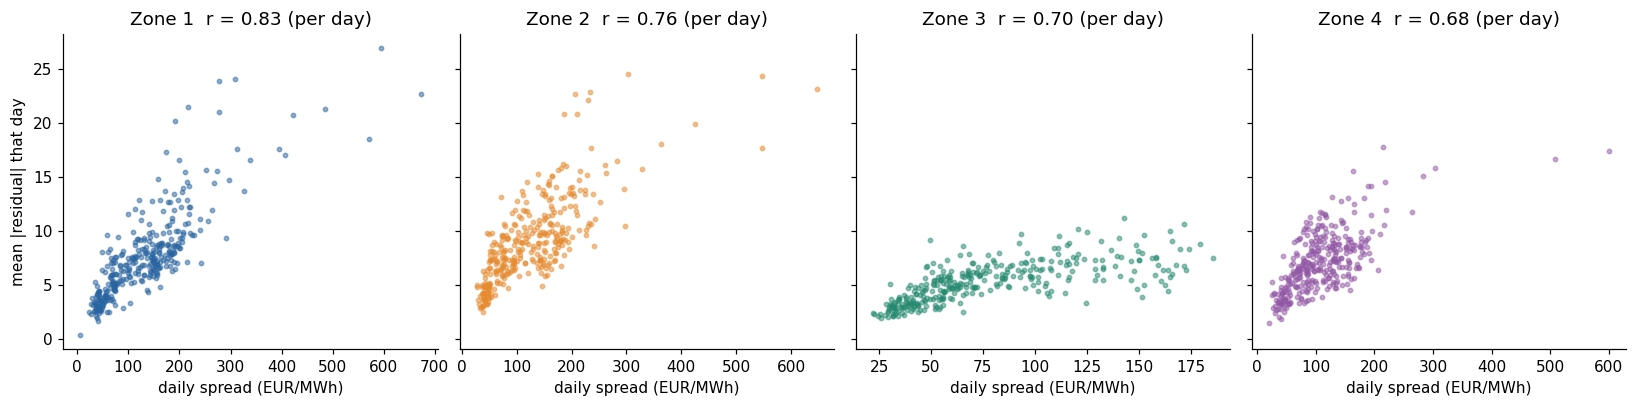

Correlation across months between daily spread and intra-hour movement:


,corr
market_id,
Zone 1,0.84
Zone 2,0.77
Zone 3,0.82
Zone 4,0.84


In [27]:
# ---------------------------------------------------------------------------
# 5a. Does intra-hour movement follow the day's spread?
# ---------------------------------------------------------------------------
day_tbl = H.groupby(['market_id', 'delivery_date']).agg(
    day_spread=('day_spread', 'first'), intra_hour_move=('abs_res', 'mean'),
    month=('month', 'first')).reset_index()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, z, c in zip(axes, ZONES, COLORS):
    p = day_tbl[day_tbl.market_id == z]
    ax.scatter(p.day_spread, p.intra_hour_move, s=8, alpha=0.5, color=c)
    ax.set(title=f'{z}  r = {p.day_spread.corr(p.intra_hour_move):.2f} (per day)', xlabel='daily spread (EUR/MWh)')
axes[0].set_ylabel('mean |residual| that day')
plt.tight_layout(); plt.show()

monthly_move = day_tbl.groupby(['market_id', 'month'])[['day_spread', 'intra_hour_move']].mean()
print('Correlation across months between daily spread and intra-hour movement:')
monthly_move.groupby('market_id').apply(
    lambda g: g.day_spread.corr(g.intra_hour_move)).round(2).rename('corr').to_frame()

### 5b. Recent history: do shapes repeat?
Today's residuals compared with the same zone/hour/quarter **1 day** and **7 days** earlier, and with the **mean of the last 7 days**. Lags join on calendar dates, so the missing DST Sundays never shift anything.

,corr lag 1d,MAE copy lag 1d,corr lag 7d,MAE copy lag 7d,corr mean last 7d,MAE copy mean last 7d,flat MAE
Zone 1,0.66,6.20,0.56,6.87,0.71,5.39,7.67
Zone 2,0.66,7.43,0.59,7.91,0.72,6.31,9.08
Zone 3,0.63,4.66,0.59,4.84,0.71,3.83,5.29
Zone 4,0.55,6.99,0.48,7.57,0.65,5.77,7.14


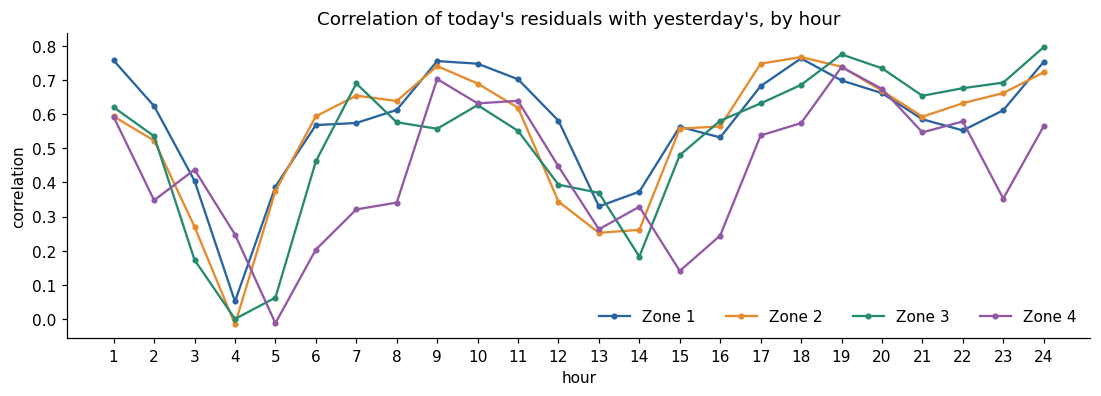

In [28]:
# ---------------------------------------------------------------------------
# 5b. Persistence: lag 1 day, lag 7 days, mean of the last 7 days
# ---------------------------------------------------------------------------
def lag_join(lag):
    # Attach the residual of the same zone/hour/quarter `lag` calendar days earlier
    prev = df[KEYS + ['residual']].copy()
    prev['delivery_date'] += pd.Timedelta(days=lag)
    return df.merge(prev.rename(columns={'residual': 'lag'}), on=KEYS)


def corr_by(frame, by):
    return frame.groupby(by)[['residual', 'lag']].apply(lambda p: p.residual.corr(p.lag))


lag_tab, lag_by_hour = {}, {}
for lag in [1, 7]:
    j = lag_join(lag)
    lag_tab[f'corr lag {lag}d'] = corr_by(j, 'market_id')
    lag_tab[f'MAE copy lag {lag}d'] = j.assign(e=(j.residual - j.lag).abs()).groupby('market_id').e.mean()
    lag_by_hour[lag] = corr_by(j, ['hour_index', 'market_id']).unstack()

# Mean of the previous 7 calendar days (needs at least 4 of them)
wide = df.pivot_table(index='delivery_date', columns=['market_id', 'hour_index', 'quarter_index'], values='residual')
wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max()))   # re-insert DST dates as gaps
roll7 = wide.shift(1).rolling(7, min_periods=4).mean()                    # strictly earlier days only
cmp7 = pd.DataFrame({'zone': np.tile(wide.columns.get_level_values(0), len(wide)),
                     'today': wide.to_numpy().ravel(),
                     'mean_last7': roll7.to_numpy().ravel()}).dropna()
by_zone7 = cmp7.groupby('zone')[['today', 'mean_last7']]
lag_tab['corr mean last 7d'] = by_zone7.apply(lambda p: p.today.corr(p.mean_last7))
lag_tab['MAE copy mean last 7d'] = by_zone7.apply(lambda p: (p.today - p.mean_last7).abs().mean())
lag_tab['flat MAE'] = df.groupby('market_id').abs_res.mean()
display(pd.DataFrame(lag_tab).round(2))

ax = lag_by_hour[1].plot(figsize=(12, 3.6), color=COLORS, marker='.')
ax.set(title="Correlation of today's residuals with yesterday's, by hour", xlabel='hour',
       ylabel='correlation', xticks=range(1, 25))
ax.legend(ncol=4, frameon=False)
plt.show()

> **What we found**
>
> - **The day's spread tells us how big the shapes will be.** Across months, intra-hour movement follows the daily spread closely (correlation 0.77–0.84 per zone), and it does *not* follow the price level. The spread is computed from the 24 hourly prices, so it is available at inference.
> - **Shapes repeat.** Correlation with yesterday is 0.55–0.66, with the same weekday last week 0.48–0.59, and with **the mean of the last 7 days 0.65–0.72**: averaging removes day-specific noise.
> - **Persistence is strongest on the ramps** (morning 6–11, evening 17–24, r ≈ 0.6–0.8) and near zero around hours 4–5 and 13–14. Zone 4 has the weakest persistence.
> - **History is a complement, not a replacement:** copying the past alone is worse than the slope rule (Zone 1: 5.39 vs 3.79).
> - **Practical note:** the jury's history length is not specified, so lag features need a fallback to training-data averages when history is short.

**→ Can we trust the past to describe October 2026?**

---
# 6. Is the past a good guide?

The test day is 19 October 2026. The model learns from Oct 2025 – Sep 2026. If the shapes drifted during that year, recent data should count more, and validation must respect time.

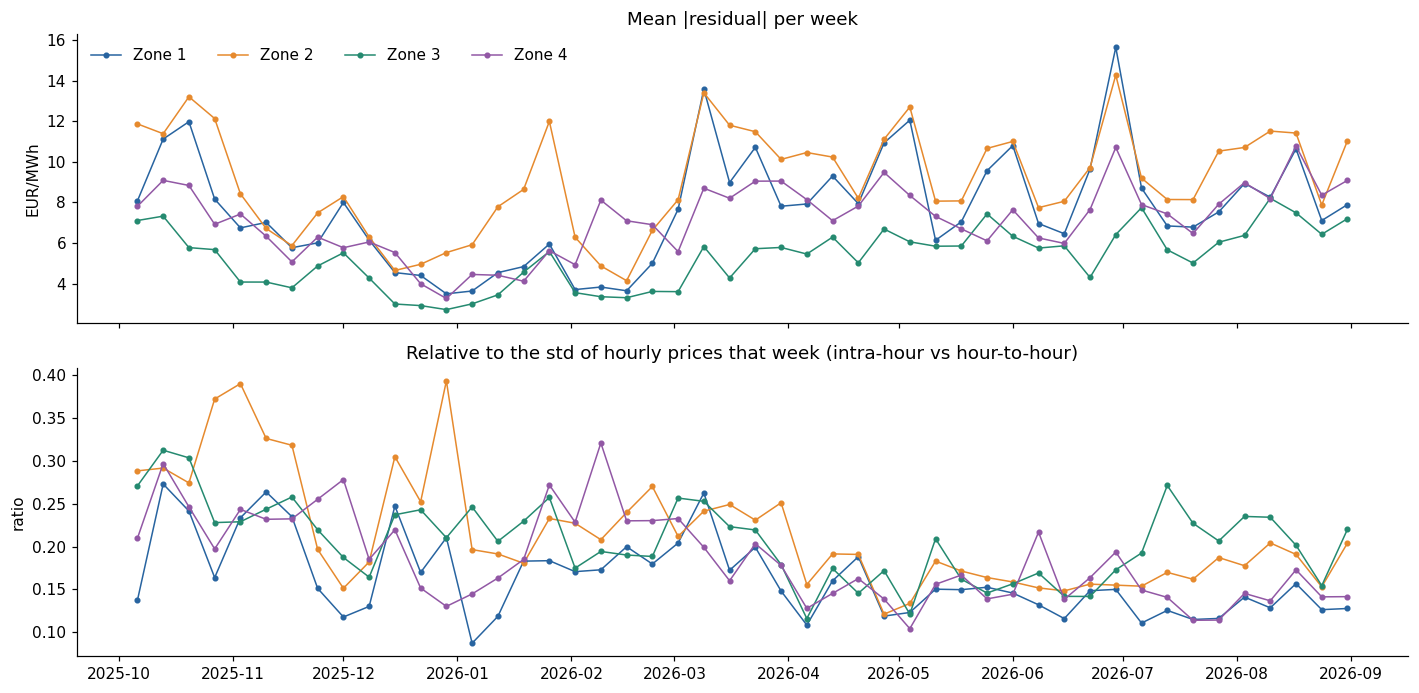

In [29]:
# ---------------------------------------------------------------------------
# 6a. Weekly intra-hour movement, absolute and relative to hour-to-hour swings
# ---------------------------------------------------------------------------
by_week = df.set_index('delivery_date').groupby('market_id')
weekly_move = by_week.abs_res.resample('W-MON').mean().unstack(0)
weekly_hourly_std = by_week.hourly_price.resample('W-MON').std().unstack(0)
relative_move = weekly_move / weekly_hourly_std

fig, axes = plt.subplots(2, 1, figsize=(13, 6.4), sharex=True)
for z, c in zip(ZONES, COLORS):
    axes[0].plot(weekly_move.index, weekly_move[z], color=c, marker='.', lw=1, label=z)
    axes[1].plot(relative_move.index, relative_move[z], color=c, marker='.', lw=1)
axes[0].set(title='Mean |residual| per week', ylabel='EUR/MWh')
axes[0].legend(ncol=4, frameon=False)
axes[1].set(title='Relative to the std of hourly prices that week (intra-hour vs hour-to-hour)', ylabel='ratio')
plt.tight_layout(); plt.show()

In [30]:
# ---------------------------------------------------------------------------
# 6b. Is the shape's timing stable? Is the slope link stable?
# ---------------------------------------------------------------------------
rows = []
for z in ZONES:
    dz = df[df.market_id == z]
    for m, part in dz.groupby('month'):
        this = part.groupby('qod').residual.mean()                  # this month's average shape
        rest = dz[dz.month != m].groupby('qod').residual.mean()     # all other months
        rows.append({'month': m, 'market_id': z, 'corr': this.corr(rest)})
print("Correlation of each month's average shape with the rest of the year:")
display(pd.DataFrame(rows).pivot(index='month', columns='market_id', values='corr').round(2))

print('Corr(slope, Q4 − Q1) per month:')
(S.groupby(['month', 'market_id'])[['slope', 'q4_minus_q1']]
   .apply(lambda p: p.slope.corr(p.q4_minus_q1)).unstack().round(2))

Correlation of each month's average shape with the rest of the year:


market_id,Zone 1,Zone 2,Zone 3,Zone 4
month,,,,
2025-10,0.79,0.88,0.95,0.88
2025-11,0.58,0.73,0.72,0.80
2025-12,0.48,0.59,0.68,0.78
2026-01,0.56,0.54,0.63,0.71
2026-02,0.73,0.78,0.83,0.79
2026-03,0.83,0.88,0.88,0.88
2026-04,0.92,0.92,0.91,0.91
2026-05,0.86,0.84,0.87,0.81
2026-06,0.67,0.74,0.83,0.86


Corr(slope, Q4 − Q1) per month:


market_id,Zone 1,Zone 2,Zone 3,Zone 4
month,,,,
2025-10,0.92,0.88,0.86,0.80
2025-11,0.85,0.84,0.81,0.72
2025-12,0.84,0.79,0.79,0.67
2026-01,0.84,0.81,0.77,0.78
2026-02,0.91,0.88,0.82,0.75
2026-03,0.92,0.88,0.79,0.82
2026-04,0.91,0.86,0.75,0.81
2026-05,0.91,0.88,0.78,0.84
2026-06,0.96,0.90,0.78,0.85


> **What we found**
>
> - **The size of the shapes changes through the year:** high in the first weeks after the switch (Oct 2025, ≈ 8–13 EUR/MWh), low in Dec–Feb (≈ 3–6), rising again from March with solar and peaking in late June (Zone 1 ≈ 16).
> - **Relative to hour-to-hour swings, shapes shrank:** the ratio fell from ≈ 0.20–0.30 (Oct–Feb) to ≈ 0.15 (Apr–Aug). Either the market settled in, or summer hour-to-hour swings grew; both mean recent data is more representative.
> - **The timing is stable except in midwinter:** most months correlate 0.8–0.9 with the rest of the year; Dec–Jan are the exception (0.48–0.78).
> - **The slope link is stable** for zones 1 and 2 (r ≈ 0.84–0.96 every month), strengthens for Zone 4 (0.67 → 0.88) and weakens for Zone 3 in summer (≈ 0.70 in Jul–Aug).
> - **October 2025, the only same-season month, was the market's unusual first month**, so the model should not lean on it.
> - **So:** prefer recent history (lag features) plus slope features, and validate strictly by time: **train Oct 2025 – Jun 2026, validate Jul – Aug 2026, final untouched check on September 2026.**

---
# 7. What we'll build

**The answer to the opening question:** the hourly curve tells us most of what happens inside the hour. The slope between neighbouring hours sets the direction and size of the tilt, and alone cuts the error from **7.30 to 4.45 EUR/MWh (−39%)**. Season, zone, the day's spread and recent history fill in most of the rest. What remains (Zone 4's late-evening zigzags, the day edges, isolated spikes) is where a learned model has to earn its place.

**The model ladder.** Each step is kept only if it beats the one before on the time-based validation split (train Oct–Jun, validate Jul–Aug, final check September). Every step ends by re-centering the 4 residuals so each hour averages exactly to the given price.

| Model step | Motivated by |
|---|---|
| Flat guess (official benchmark) | Chapter 1 |
| Slope × k, with k per zone | Chapter 3 |
| + average shape per zone × hour × season (handles zigzags, edges, weekends) | Chapter 4 |
| + day spread and 7-day history (with fallback when history is short) | Chapter 5 |
| Gradient boosting with MAE loss | The rest, only if validation says it's worth it |

**Design rules carried over from the EDA**
- Lag features join on **calendar dates** (two DST Sundays are missing).
- Use **MAE / L1 losses and robust statistics**: spikes and negative prices are real and must stay in the data.
- Report MAE per zone and per quarter position, and always against the flat guess and the slope rule.

In [31]:
# The thread of the story, recomputed from the data above
print(f'Flat guess:  {FLAT_SCORE:.2f} EUR/MWh')
print(f'Slope × 1:   {SLOPE1_SCORE:.2f} EUR/MWh  ({SLOPE1_SCORE / FLAT_SCORE - 1:+.0%})')
print(f'Slope × 2:   {SLOPE2_SCORE:.2f} EUR/MWh  ({SLOPE2_SCORE / FLAT_SCORE - 1:+.0%})')

Flat guess:  7.30 EUR/MWh
Slope × 1:   5.32 EUR/MWh  (-27%)
Slope × 2:   4.45 EUR/MWh  (-39%)


---
# Appendix A. Data checks

Structural checks use the **full** file; price statistics use the EDA window only.

In [32]:
# ---------------------------------------------------------------------------
# A1. Structural checks on the full file
# ---------------------------------------------------------------------------
print(f'Rows: {len(full):,}  (expected 363 days × 4 zones × 96 quarters = {363 * 4 * 96:,})')
print(f'Distinct dates: {full.delivery_date.nunique()}, zones: {sorted(full.market_id.unique())}')
print(f'Missing values: {full.isna().sum().sum()}')
print(f'Duplicate keys: {full.duplicated(KEYS).sum()}')
print(f'Non-finite prices: {(~np.isfinite(full.price_eur_mwh)).sum()}')
rows_per_day = full.groupby(['delivery_date', 'market_id']).size()
print(f'Day/zone combos with != 96 rows: {(rows_per_day != 96).sum()}')
print(f'hour_index range: {full.hour_index.min()}–{full.hour_index.max()}, '
      f'quarter_index range: {full.quarter_index.min()}–{full.quarter_index.max()}')
all_days = pd.date_range(full.delivery_date.min(), full.delivery_date.max())
missing_days = all_days.difference(full.delivery_date.unique())
print('Missing dates:', [f'{d:%Y-%m-%d} ({d:%A})' for d in missing_days])

Rows: 139,392  (expected 363 days × 4 zones × 96 quarters = 139,392)
Distinct dates: 363, zones: ['Zone 1', 'Zone 2', 'Zone 3', 'Zone 4']
Missing values: 0
Duplicate keys: 0
Non-finite prices: 0
Day/zone combos with != 96 rows: 0
hour_index range: 1–24, quarter_index range: 1–4
Missing dates: ['2025-10-26 (Sunday)', '2026-03-29 (Sunday)']


In [33]:
# ---------------------------------------------------------------------------
# A2. Price level, negatives and spikes per zone (EDA window)
# ---------------------------------------------------------------------------
df.groupby('market_id').price_eur_mwh.agg(
    min='min', mean='mean', max='max', std='std',
    p01=lambda s: s.quantile(0.01),                   # 1st percentile
    p99=lambda s: s.quantile(0.99),                   # 99th percentile
    negative_pct=lambda s: 100 * (s < 0).mean(),      # % of quarters below 0
    spikes_over_300=lambda s: (s > 300).sum(),        # count of quarters above 300
    below_minus_100=lambda s: (s < -100).sum(),       # count of quarters below −100
).round(2)

,min,mean,max,std,p01,p99,negative_pct,spikes_over_300,below_minus_100
market_id,,,,,,,,,
Zone 1,-499.99,100.78,747.10,59.21,-17.11,254.32,5.84,181,68
Zone 2,-498.65,114.96,645.20,56.79,-11.90,265.94,3.05,186,62
Zone 3,0.00,132.23,313.00,37.19,12.25,225.74,0.00,5,0
Zone 4,-498.65,70.76,487.38,55.82,-13.47,197.86,6.58,11,59


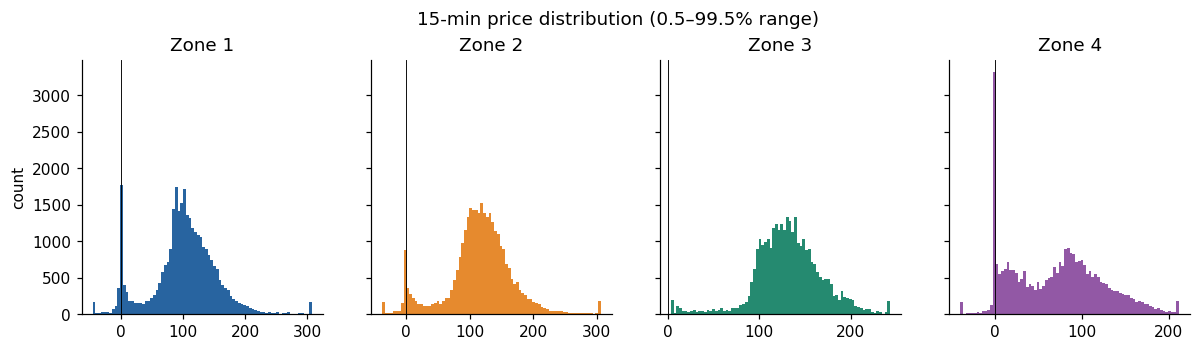

,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh
101459,2026-06-24,Zone 1,21,4,747.10
101455,2026-06-24,Zone 1,20,4,700.00
101458,2026-06-24,Zone 1,21,3,699.99
101460,2026-06-24,Zone 1,22,1,693.47
101461,2026-06-24,Zone 1,22,2,681.95


In [34]:
# ---------------------------------------------------------------------------
# A3. Price distribution per zone, and the 5 most extreme quarters
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, z, c in zip(axes, ZONES, COLORS):
    s = df.loc[df.market_id == z, 'price_eur_mwh']
    ax.hist(s.clip(s.quantile(0.005), s.quantile(0.995)), bins=80, color=c)
    ax.axvline(0, color='k', lw=0.6)
    ax.set_title(z)
axes[0].set_ylabel('count')
fig.suptitle('15-min price distribution (0.5–99.5% range)', y=1.03)
plt.show()
df.loc[df.price_eur_mwh.abs().nlargest(5).index, KEYS + ['price_eur_mwh']]

In [35]:
# ---------------------------------------------------------------------------
# A4. Negative prices: counts per zone
# ---------------------------------------------------------------------------
neg_counts = df.groupby('market_id').agg(
    negative_quarters=('is_neg', 'sum'),
    negative_pct=('is_neg', lambda s: 100 * s.mean()),
    zero_quarters=('price_eur_mwh', lambda s: (s == 0).sum()),
    near_floor_quarters=('price_eur_mwh', lambda s: (s <= -400).sum()),
)
neg_counts['negative_hours'] = H[H.hourly_price < 0].groupby('market_id').size()
days_neg = df.groupby(['delivery_date', 'market_id']).is_neg.any()
neg_counts['days_with_negatives'] = days_neg.groupby('market_id').sum()
neg_counts['days_with_negatives_pct'] = 100 * days_neg.groupby('market_id').mean()
neg_counts.fillna(0).round(1)

,negative_quarters,negative_pct,zero_quarters,near_floor_quarters,negative_hours,days_with_negatives,days_with_negatives_pct
market_id,,,,,,,
Zone 1,1868,5.8,338,14,472.0,88,26.4
Zone 2,974,3.0,167,12,249.0,59,17.7
Zone 3,0,0.0,86,0,0.0,0,0.0
Zone 4,2102,6.6,1028,12,555.0,109,32.7


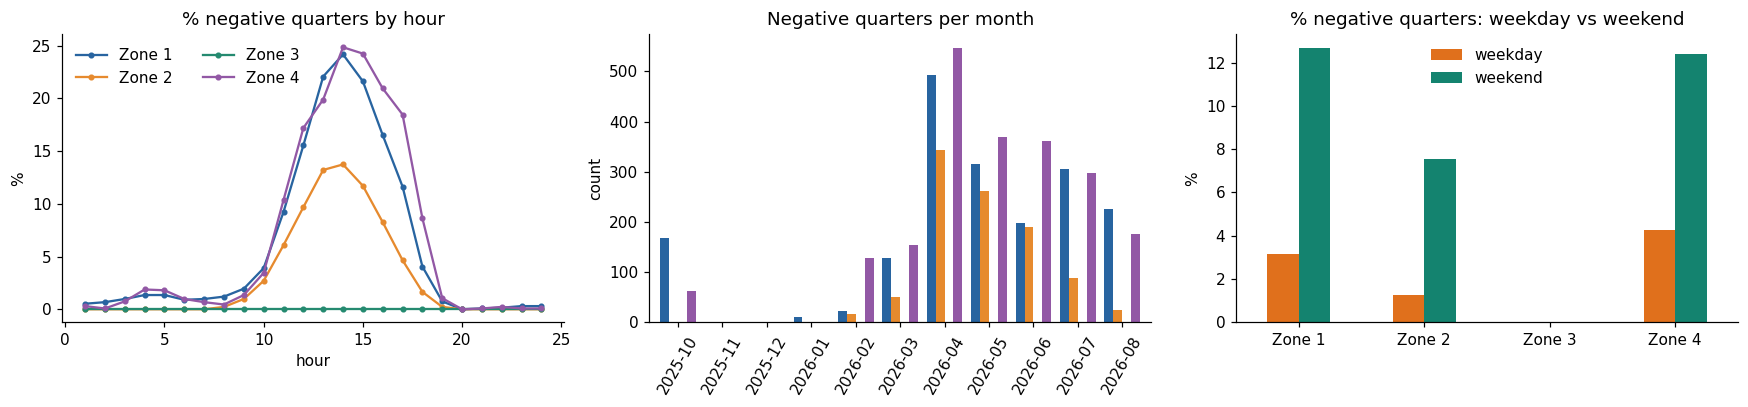

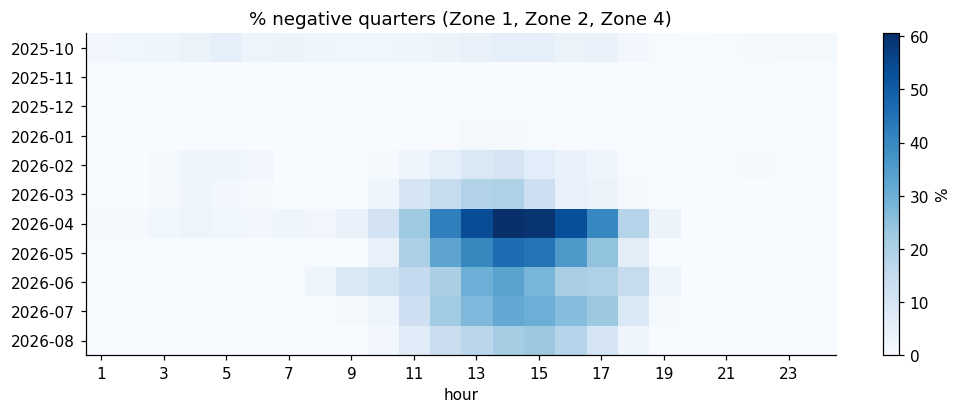

In [36]:
# ---------------------------------------------------------------------------
# A5. When do negative prices happen? By hour, month, weekday vs weekend
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
(df.groupby(['hour_index', 'market_id']).is_neg.mean().unstack() * 100).plot(ax=axes[0], color=COLORS, marker='.')
axes[0].set(title='% negative quarters by hour', xlabel='hour', ylabel='%')
axes[0].legend(ncol=2, frameon=False)

neg_by_month = df.groupby(['month', 'market_id']).is_neg.sum().unstack()
neg_by_month.plot.bar(ax=axes[1], color=COLORS, legend=False, width=0.8)
axes[1].set(title='Negative quarters per month', xlabel='', ylabel='count')
axes[1].tick_params(axis='x', rotation=60)

(df.groupby(['market_id', 'day_type']).is_neg.mean().unstack() * 100).plot.bar(
    ax=axes[2], color=['#e0701c', '#14836f'], rot=0)
axes[2].set(title='% negative quarters: weekday vs weekend', xlabel='', ylabel='%')
axes[2].legend(frameon=False)
plt.tight_layout(); plt.show()

# Month × hour heatmap for the zones that go negative
neg_zones = [z for z in ZONES if df[df.market_id == z].is_neg.any()]
heat = df[df.market_id.isin(neg_zones)].groupby(['month', 'hour_index']).is_neg.mean().unstack() * 100
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat, aspect='auto', cmap='Blues')
ax.set(xticks=range(0, 24, 2), xticklabels=range(1, 25, 2), yticks=range(len(heat)), yticklabels=heat.index,
       xlabel='hour', title=f'% negative quarters ({", ".join(neg_zones)})')
fig.colorbar(im, ax=ax, label='%')
plt.show()

> **What we found: data checks**
>
> - **The data is clean:** exactly 139,392 rows, no missing values, duplicates or infinities, and every day/zone has 96 quarters.
> - **The only missing dates are 2025-10-26 and 2026-03-29**, both Sundays: the two daylight-saving changes. Lag features must join on calendar dates, never "previous row".
> - **Zone 3 is the calm zone:** never negative, max 313 EUR/MWh, lowest std (37). **Zones 1, 2 and 4 reach the −500 floor** and are negative 3–7% of the time; zones 1 and 2 also have ≈ 180 quarters above 300 EUR/MWh each.
> - **The 5 most extreme quarters all come from one event:** Zone 1 on the evening of 2026-06-24 (up to 747 EUR/MWh). Spikes are real, not errors: keep them and use a robust loss.
> - **Negative prices are a solar effect:** ≈ 81% fall between hours 10 and 16, peaking at hours 13–15; almost none from Nov to Jan, peaking in April. Weekends are 3–6× more likely to be negative. Zone 4: 2,102 negative quarters (6.6%) on 109 days; Zone 1: 1,868 (5.8%); Zone 2: 974 (3.0%); Zone 3: none.

---
# Appendix B. The price level in detail

We don't predict the level (it's given), but it explains *where* the ramps are, and the ramps are where the shapes are.

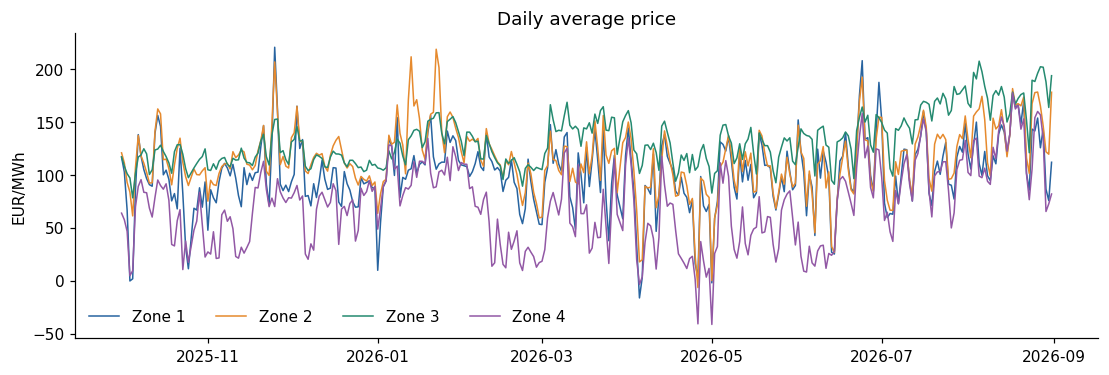

Correlation of daily average price between zones:


market_id,Zone 1,Zone 2,Zone 3,Zone 4
market_id,,,,
Zone 1,1.00,0.82,0.60,0.72
Zone 2,0.82,1.00,0.67,0.70
Zone 3,0.60,0.67,1.00,0.67
Zone 4,0.72,0.70,0.67,1.00


In [37]:
# ---------------------------------------------------------------------------
# B1. Daily average price, and how similar the zones are
# ---------------------------------------------------------------------------
daily_avg = df.groupby(['delivery_date', 'market_id']).price_eur_mwh.mean().unstack()
fig, ax = plt.subplots(figsize=(12, 3.6))
for z, c in zip(ZONES, COLORS):
    ax.plot(daily_avg.index, daily_avg[z], color=c, lw=1, label=z)
ax.set(title='Daily average price', ylabel='EUR/MWh')
ax.legend(ncol=4, frameon=False)
plt.show()
print('Correlation of daily average price between zones:')
daily_avg.corr().round(2)

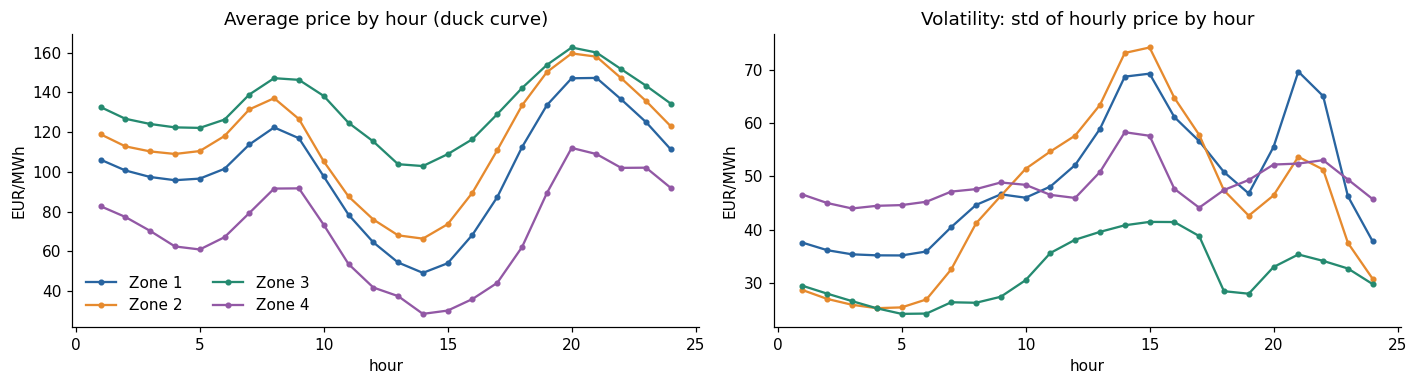

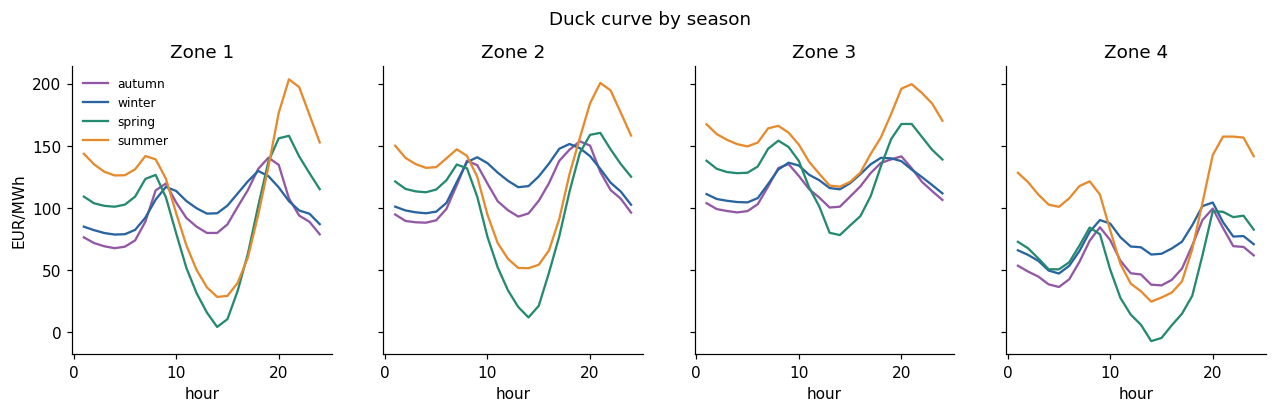

In [38]:
# ---------------------------------------------------------------------------
# B2. Duck curve, volatility by hour, and the duck curve by season
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
df.groupby(['hour_index', 'market_id']).price_eur_mwh.mean().unstack().plot(ax=axes[0], color=COLORS, marker='.')
axes[0].set(title='Average price by hour (duck curve)', xlabel='hour', ylabel='EUR/MWh')
axes[0].legend(ncol=2, frameon=False)
H.groupby(['hour_index', 'market_id']).hourly_price.std().unstack().plot(ax=axes[1], color=COLORS, marker='.', legend=False)
axes[1].set(title='Volatility: std of hourly price by hour', xlabel='hour', ylabel='EUR/MWh')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, z in zip(axes, ZONES):
    for s in SEASONS:
        part = H[(H.market_id == z) & (H.season == s)]
        ax.plot(part.groupby('hour_index').hourly_price.mean(), color=SEASON_COLORS[s], label=s)
    ax.set(title=z, xlabel='hour')
axes[0].set_ylabel('EUR/MWh'); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Duck curve by season', y=1.03)
plt.show()

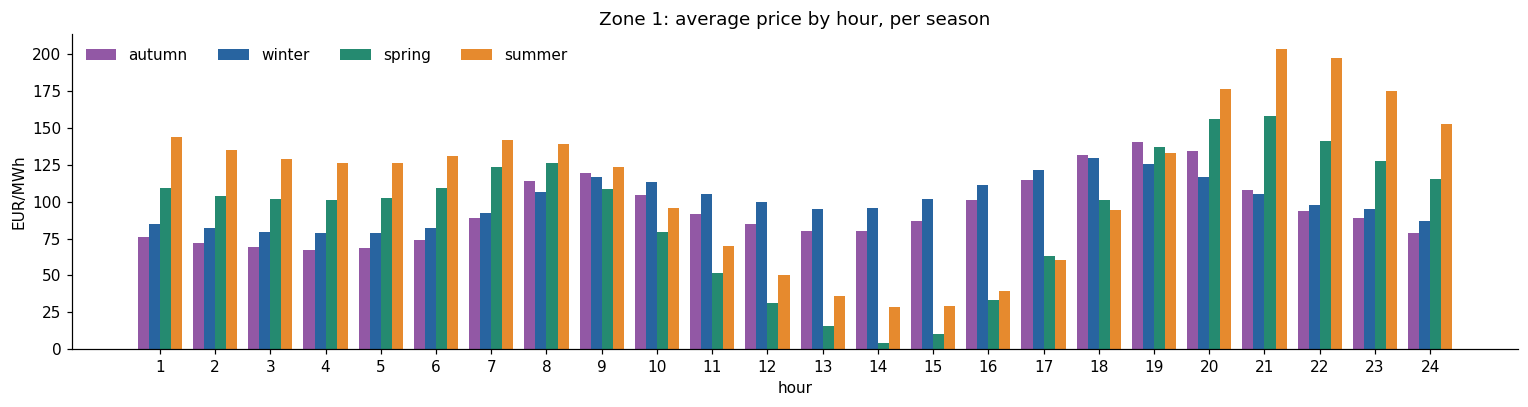

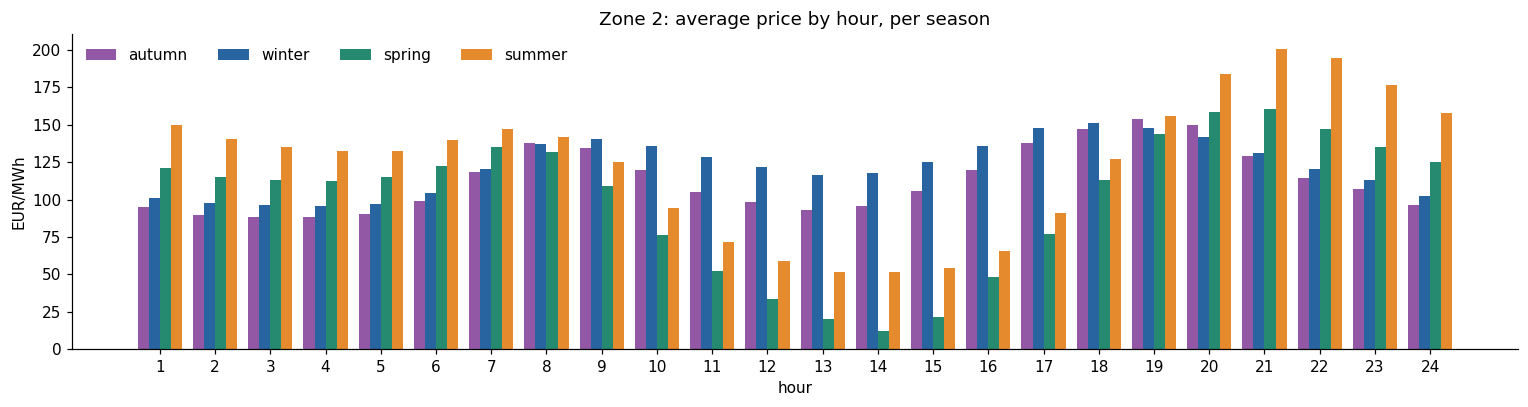

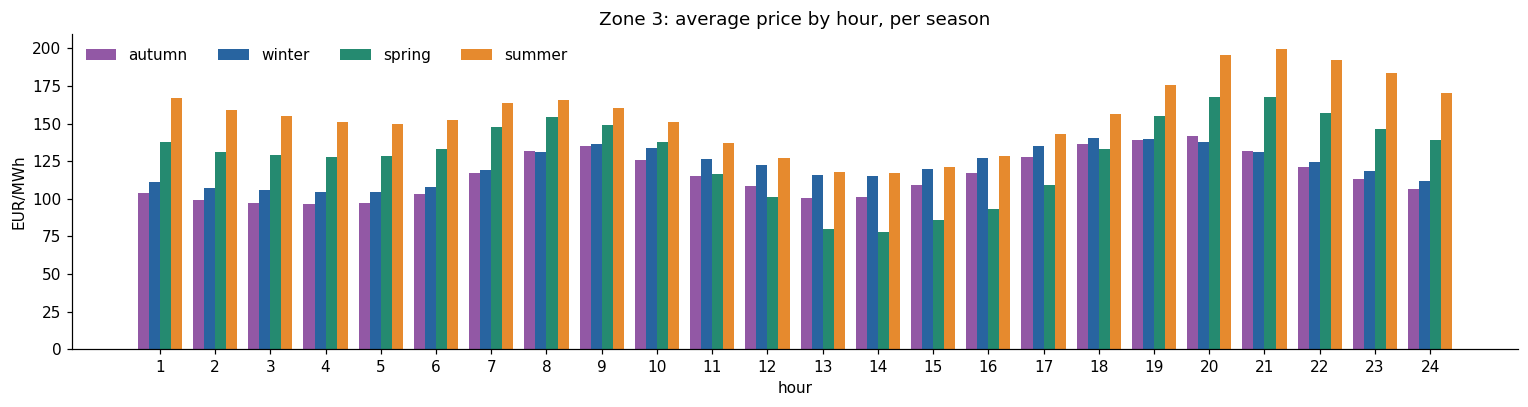

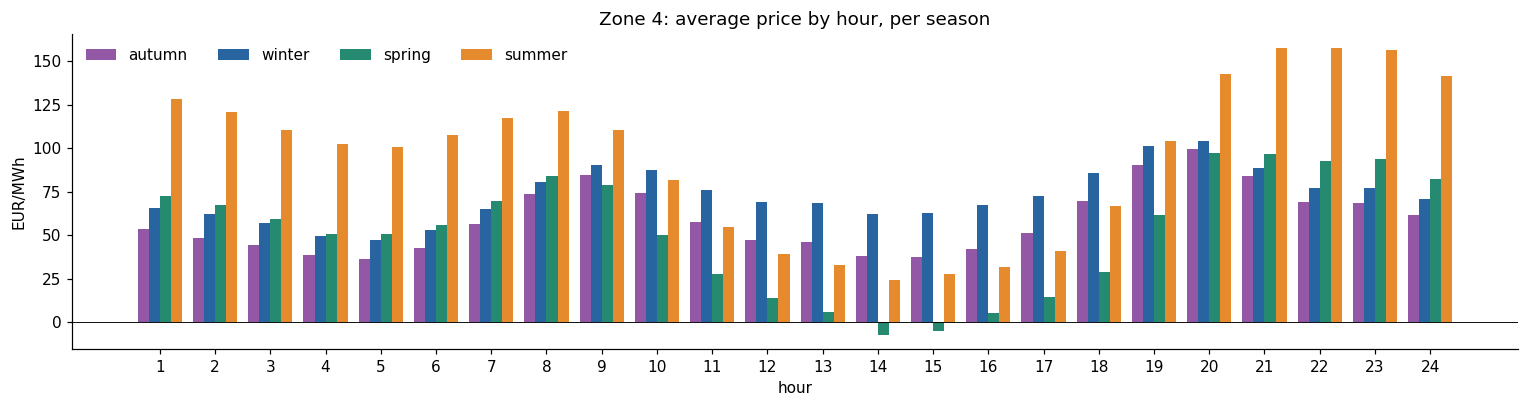

cheapest_hour  cheapest_price  priciest_hour  \
market_id season                                                 
Zone 1    autumn              4            67.6             19   
          winter              4            78.5             18   
          spring             14             4.3             21   
          summer             14            28.4             21   
Zone 2    autumn              4            88.1             19   
          winter              4            95.7             18   
          spring             14            11.9             21   
          summer             14            51.5             21   
Zone 3    autumn              4            96.3             20   
          winter              5           104.4             18   
          spring             14            78.1             21   
          summer             14           117.0             21   
Zone 4    autumn              5            36.4             20   
          winter              5            47.2             20   
          spring             14            -7.1             20   
          summer             14            24.6             22   

                  priciest_price  daily_spread  
market_id season                                
Zone 1    autumn           140.4          72.8  
          winter           129.7          51.1  
          spring           158.0         153.7  
          summer           203.4         175.0  
Zone 2    autumn           153.5          65.4  
          winter           151.4          55.7  
          spring           160.3         148.4  
          summer           200.5         149.0  
Zone 3    autumn           141.4          45.1  
          winter           140.2          35.8  
          spring           167.5          89.4  
          summer           199.5          82.5  
Zone 4    autumn            99.4          63.0  
          winter           104.3          57.1  
          spring            97.3         104.4  
          summer           157.3         132.7

In [39]:
# ---------------------------------------------------------------------------
# B3. Price by hour per season (bars), and cheapest / priciest hour table
# ---------------------------------------------------------------------------
hours_x = np.arange(1, 25)
bar_w = 0.2
for z in ZONES:
    t = H[H.market_id == z].groupby(['hour_index', 'season']).hourly_price.mean().unstack()
    fig, ax = plt.subplots(figsize=(14, 3.8))
    for k, s in enumerate(SEASONS):
        ax.bar(hours_x + (k - 1.5) * bar_w, t[s], bar_w, color=SEASON_COLORS[s], label=s)
    ax.axhline(0, color='k', lw=0.6)
    ax.set(title=f'{z}: average price by hour, per season', xlabel='hour', ylabel='EUR/MWh', xticks=hours_x)
    ax.legend(frameon=False, ncol=4)
    plt.tight_layout(); plt.show()

price_by_hour = H.groupby(['market_id', 'season', 'hour_index']).hourly_price.mean()
season_summary = pd.DataFrame({
    'cheapest_hour': price_by_hour.groupby(['market_id', 'season']).idxmin().str[-1],
    'cheapest_price': price_by_hour.groupby(['market_id', 'season']).min(),
    'priciest_hour': price_by_hour.groupby(['market_id', 'season']).idxmax().str[-1],
    'priciest_price': price_by_hour.groupby(['market_id', 'season']).max(),
})
season_summary['daily_spread'] = season_summary.priciest_price - season_summary.cheapest_price
season_summary.reindex(SEASONS, level='season').round(1)

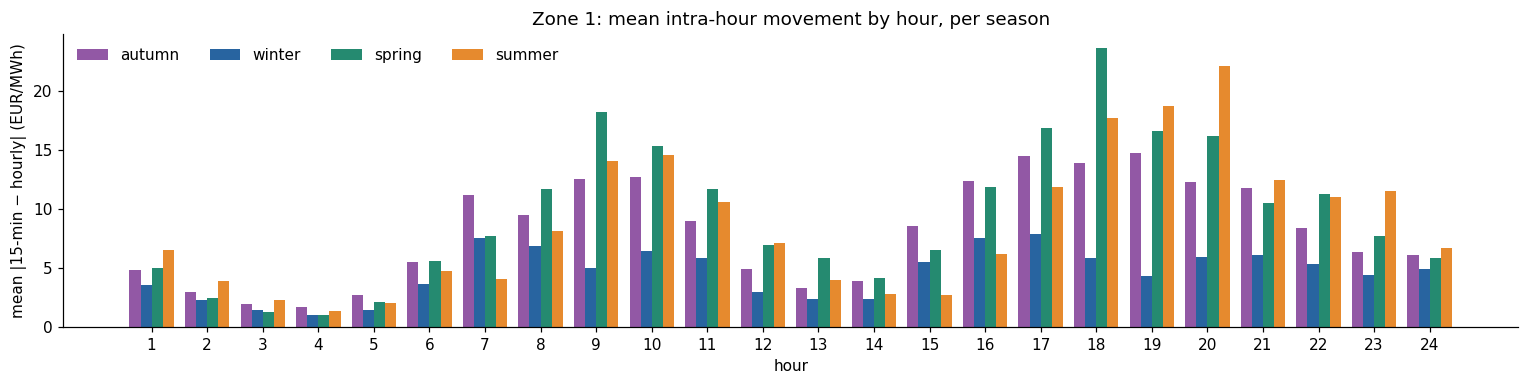

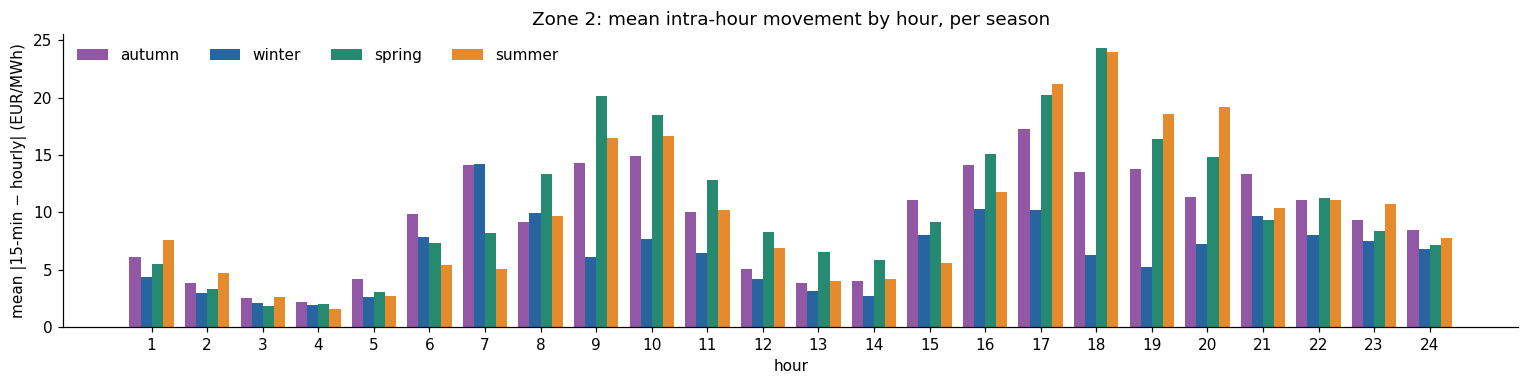

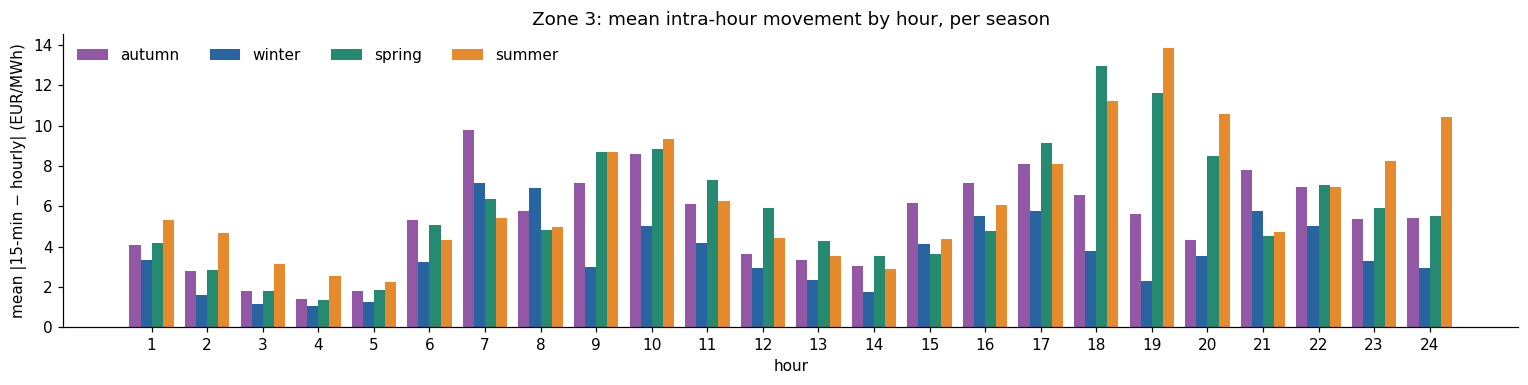

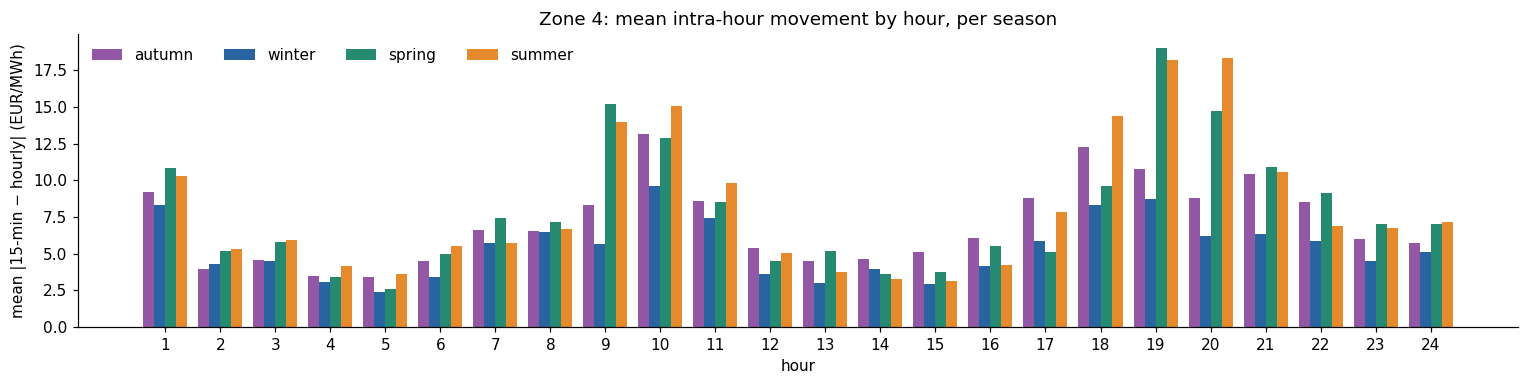

In [40]:
# ---------------------------------------------------------------------------
# B4. Intra-hour movement by hour per season (bars)
# ---------------------------------------------------------------------------
for z in ZONES:
    t = H[H.market_id == z].groupby(['hour_index', 'season']).abs_res.mean().unstack()
    fig, ax = plt.subplots(figsize=(14, 3.6))
    for k, s in enumerate(SEASONS):
        ax.bar(hours_x + (k - 1.5) * bar_w, t[s], bar_w, color=SEASON_COLORS[s], label=s)
    ax.set(title=f'{z}: mean intra-hour movement by hour, per season', xlabel='hour',
           ylabel='mean |15-min − hourly| (EUR/MWh)', xticks=hours_x)
    ax.legend(frameon=False, ncol=4)
    plt.tight_layout(); plt.show()

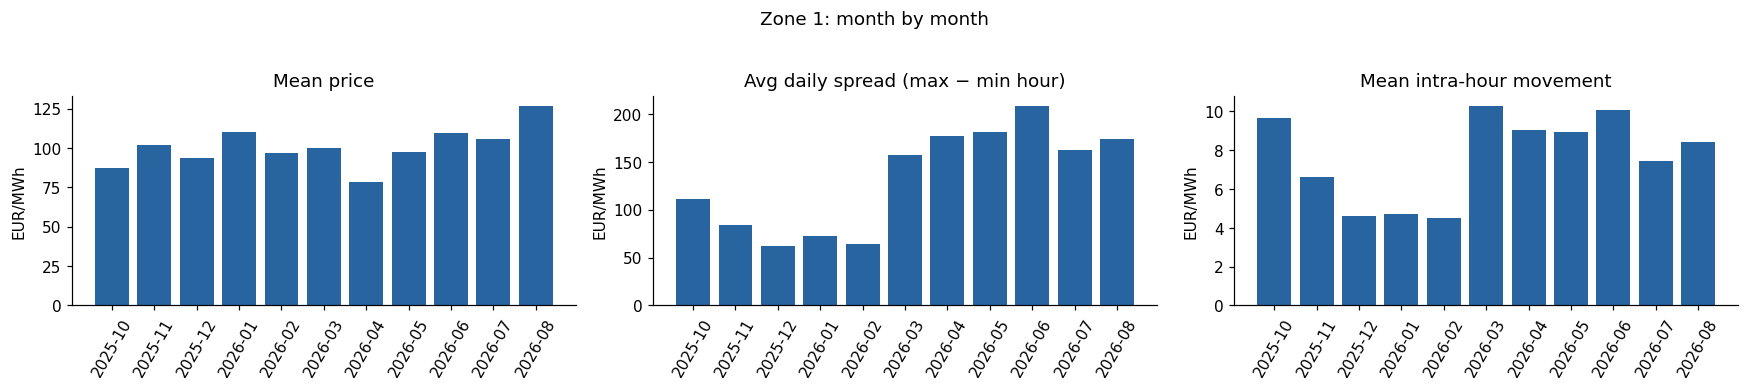

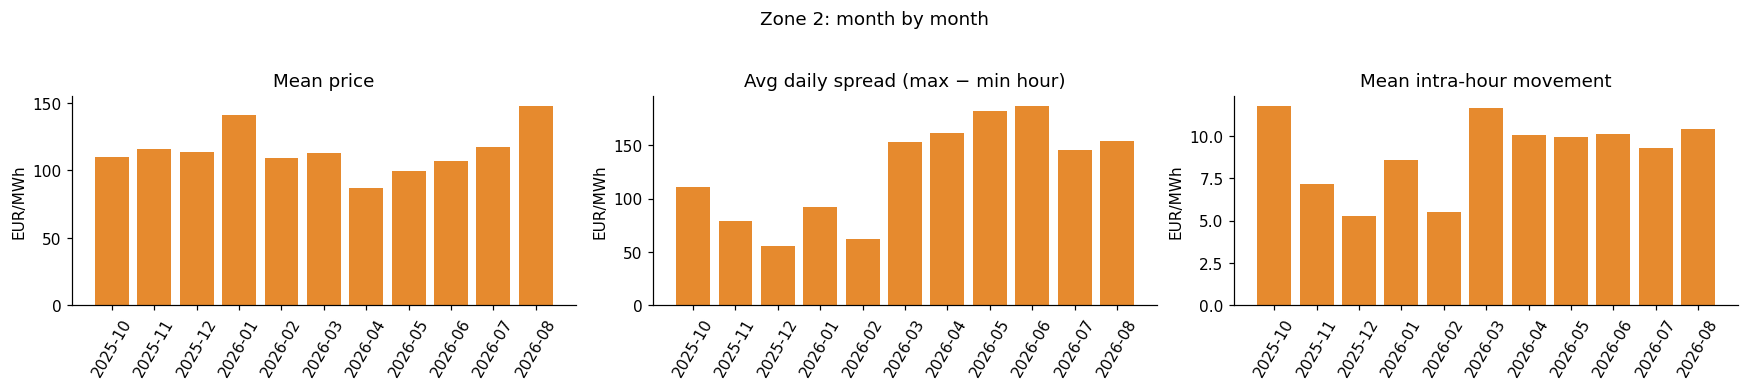

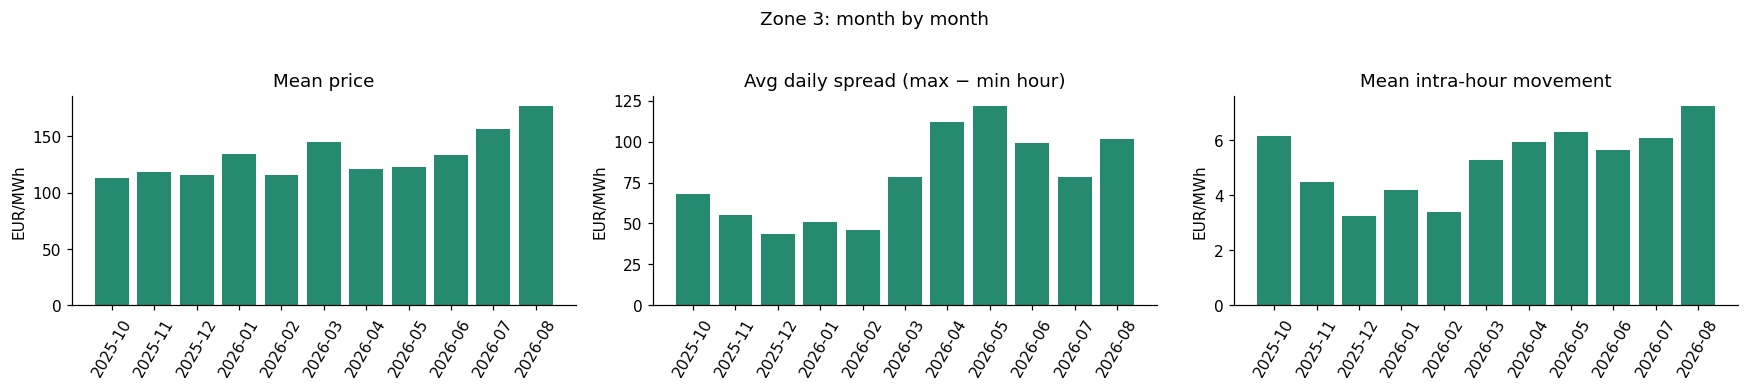

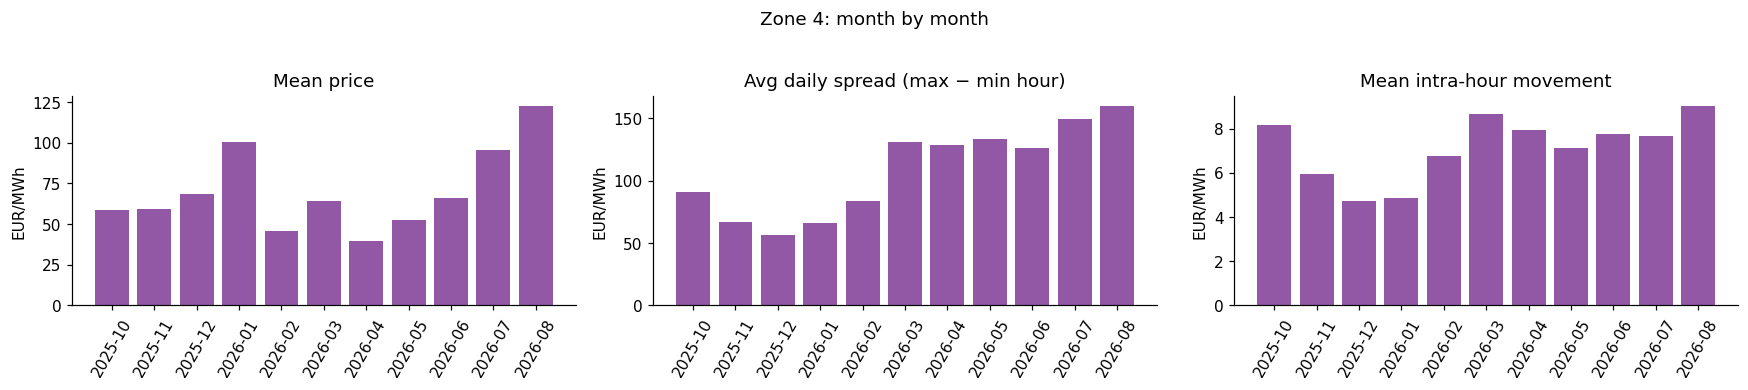

Mean price per month (EUR/MWh):


market_id,Zone 1,Zone 2,Zone 3,Zone 4
month,,,,
2025-10,87.1,110.0,113.0,58.9
2025-11,101.9,116.0,118.2,59.1
2025-12,93.5,114.0,115.5,68.7
2026-01,110.1,141.4,133.8,100.7
2026-02,96.6,109.2,115.9,46.0
2026-03,100.3,113.3,144.9,64.3
2026-04,78.5,86.6,121.1,39.8
2026-05,97.5,100.0,122.5,52.2
2026-06,109.5,106.7,133.7,66.1


Change vs previous month (%):


market_id,Zone 1,Zone 2,Zone 3,Zone 4
month,,,,
2025-10,NaN,NaN,NaN,NaN
2025-11,17.0,5.4,4.6,0.4
2025-12,-8.3,-1.7,-2.3,16.2
2026-01,17.8,24.0,15.8,46.4
2026-02,-12.3,-22.8,-13.4,-54.3
2026-03,3.8,3.8,25.1,39.7
2026-04,-21.7,-23.5,-16.5,-38.1
2026-05,24.2,15.4,1.2,31.2
2026-06,12.3,6.7,9.1,26.6


In [41]:
# ---------------------------------------------------------------------------
# B5. Month by month: price level, daily spread, intra-hour movement
# ---------------------------------------------------------------------------
monthly_tbl = pd.DataFrame({
    'mean_price': H.groupby(['market_id', 'month']).hourly_price.mean(),
    'daily_spread': day_tbl.groupby(['market_id', 'month']).day_spread.mean(),
    'intra_hour_move': H.groupby(['market_id', 'month']).abs_res.mean(),
})
MONTHS = sorted(H.month.unique())
for z, color in zip(ZONES, COLORS):
    m = monthly_tbl.loc[z]
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
    for ax, col, title in [(axes[0], 'mean_price', 'Mean price'),
                           (axes[1], 'daily_spread', 'Avg daily spread (max − min hour)'),
                           (axes[2], 'intra_hour_move', 'Mean intra-hour movement')]:
        ax.bar(m.index, m[col], color=color)
        ax.set(title=title, ylabel='EUR/MWh')
        ax.tick_params(axis='x', rotation=60)
    fig.suptitle(f'{z}: month by month', y=1.03)
    plt.tight_layout(); plt.show()

monthly_price = monthly_tbl.mean_price.unstack('market_id')
print('Mean price per month (EUR/MWh):')
display(monthly_price.round(1))
print('Change vs previous month (%):')
display((monthly_price.pct_change() * 100).round(1))

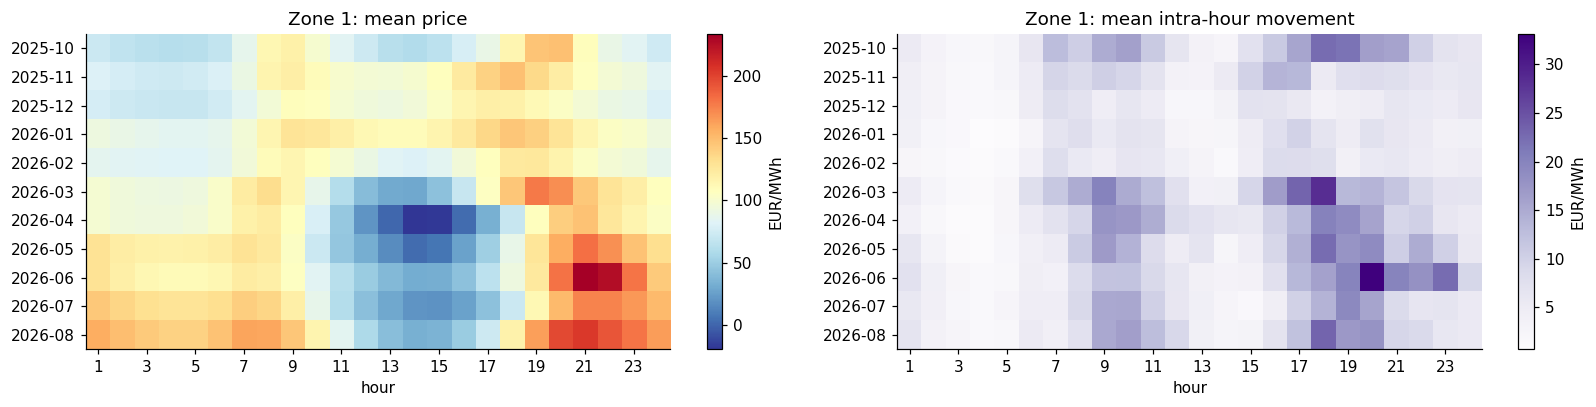

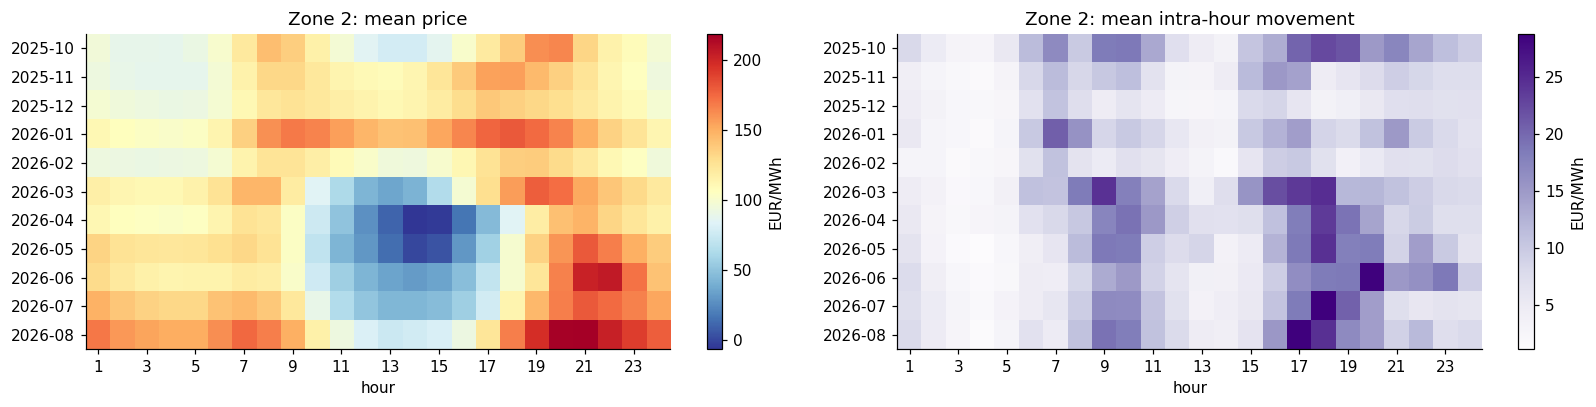

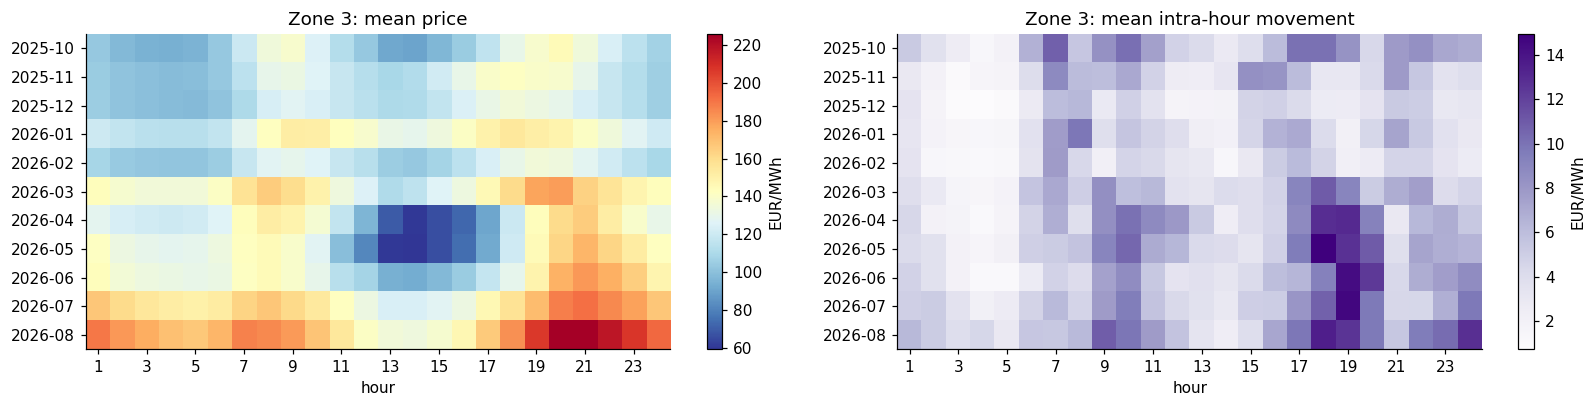

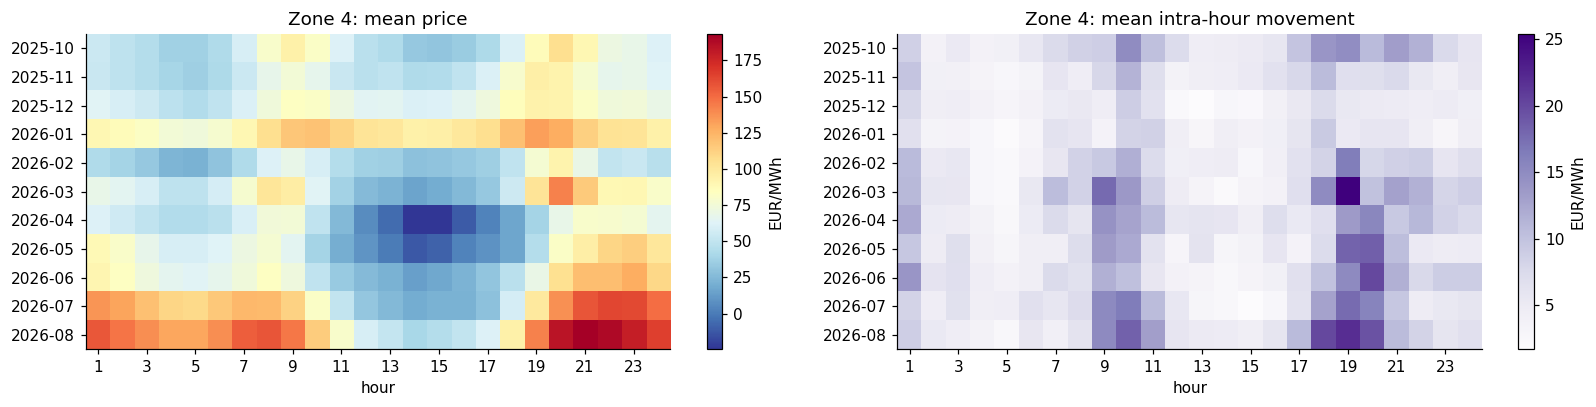

In [42]:
# ---------------------------------------------------------------------------
# B6. Month × hour heatmaps: price (left) and intra-hour movement (right)
# ---------------------------------------------------------------------------
for z in ZONES:
    g = H[H.market_id == z].groupby(['month', 'hour_index'])
    fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
    for ax, mat, title, cmap in [(axes[0], g.hourly_price.mean().unstack(), 'mean price', 'RdYlBu_r'),
                                 (axes[1], g.abs_res.mean().unstack(), 'mean intra-hour movement', 'Purples')]:
        im = ax.imshow(mat, aspect='auto', cmap=cmap)
        ax.set(xticks=range(0, 24, 2), xticklabels=range(1, 25, 2), yticks=range(len(mat)),
               yticklabels=mat.index, xlabel='hour', title=f'{z}: {title}')
        fig.colorbar(im, ax=ax, label='EUR/MWh')
    plt.tight_layout(); plt.show()

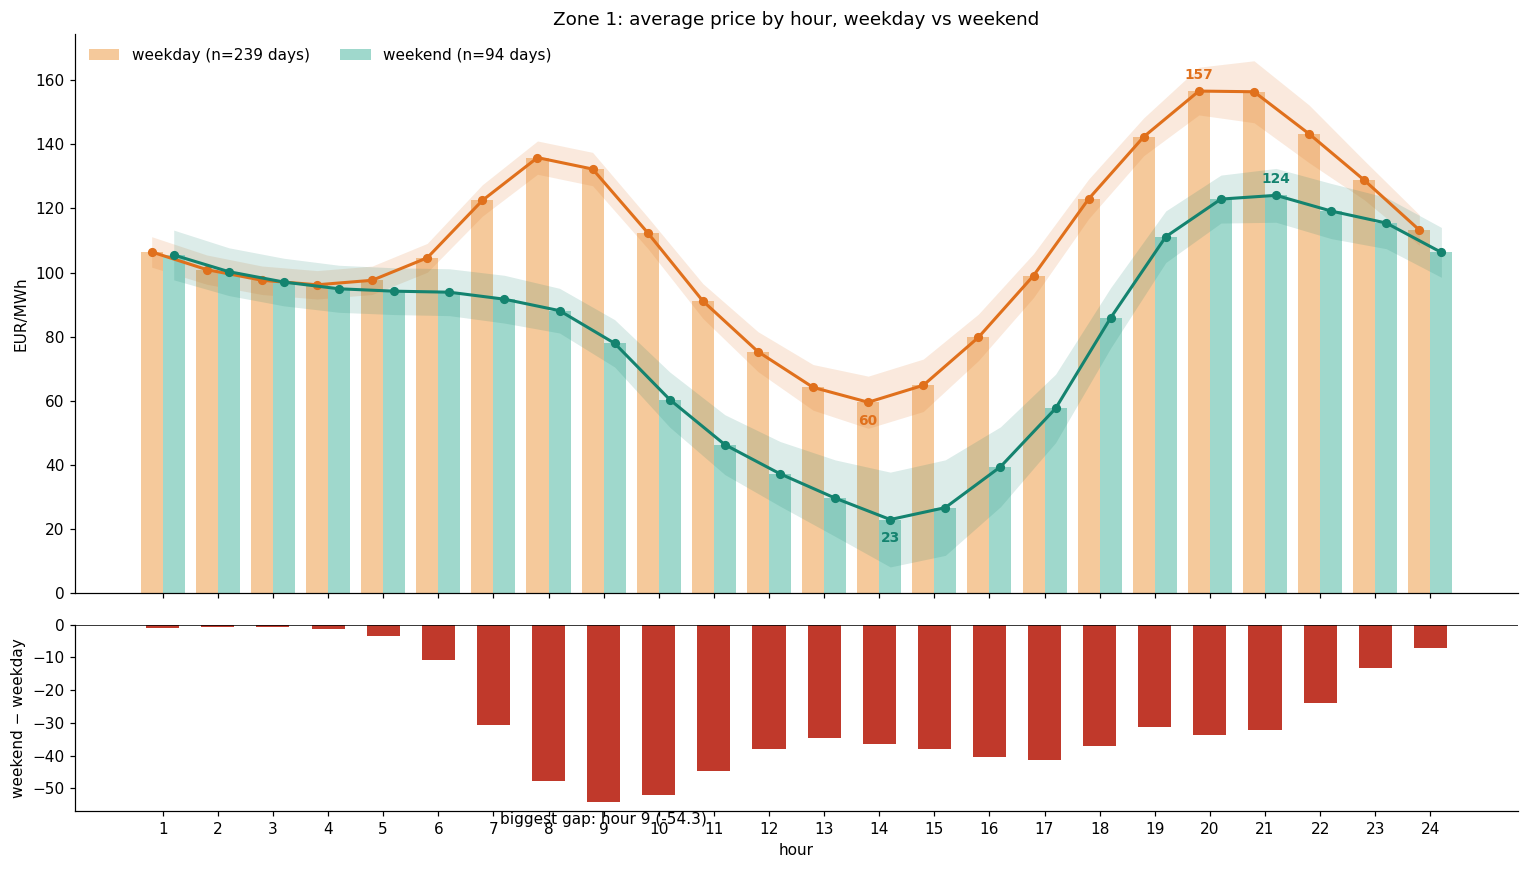

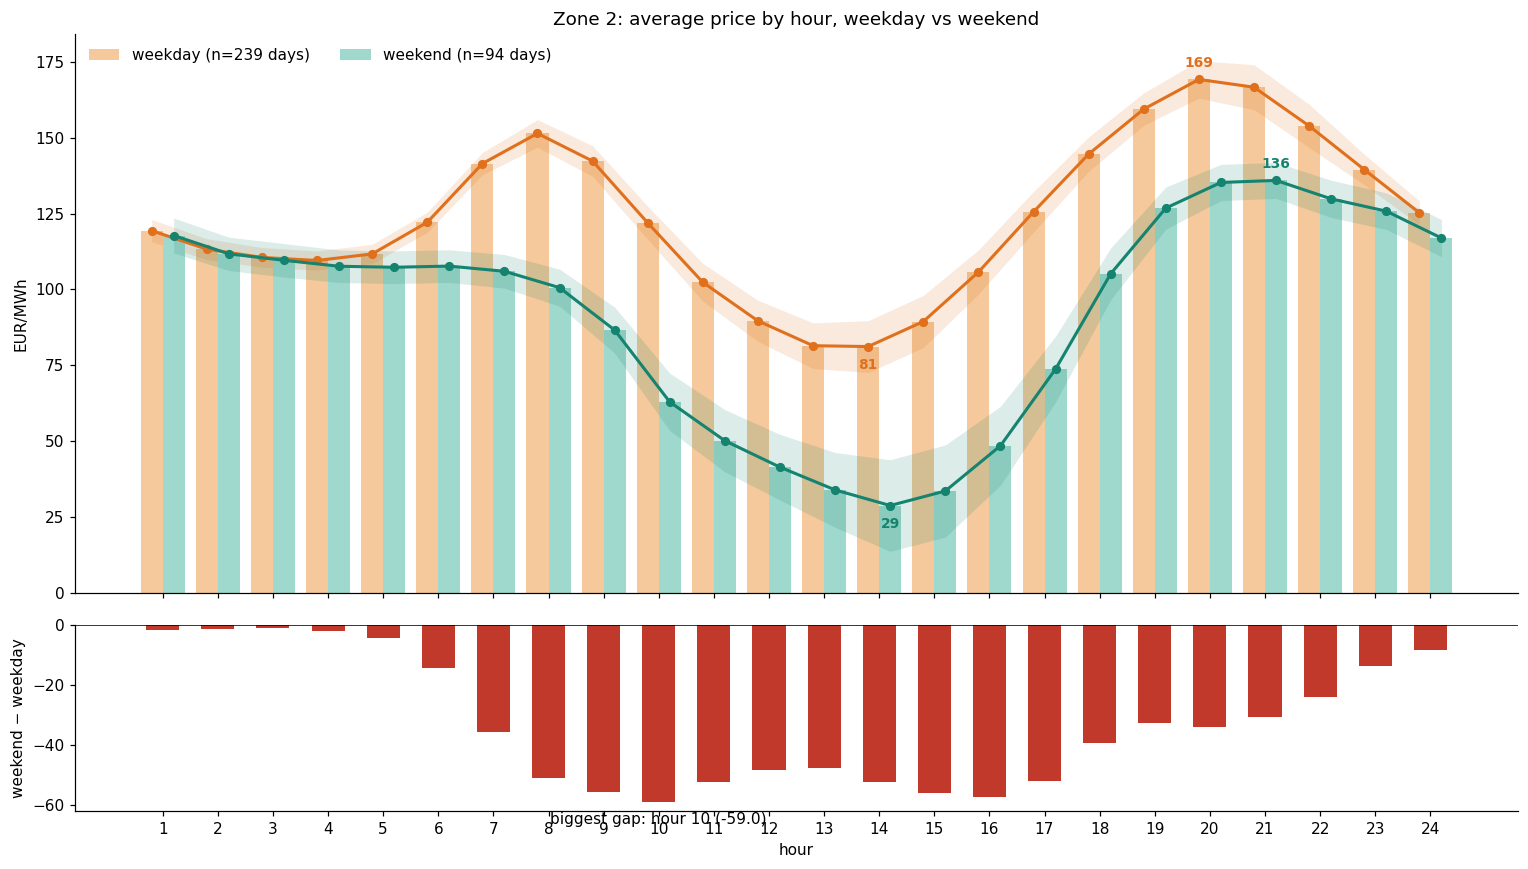

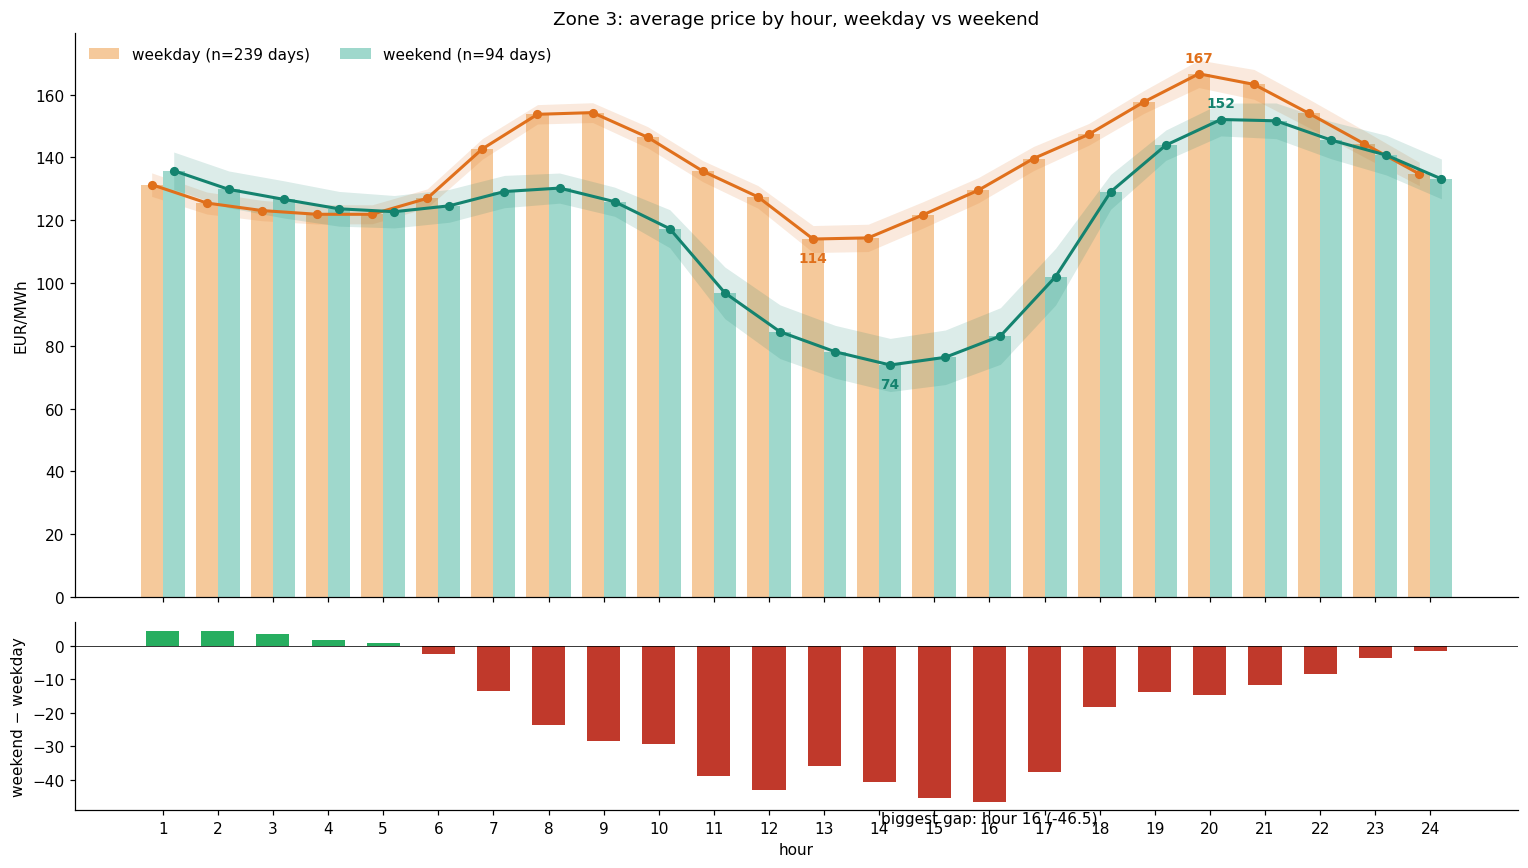

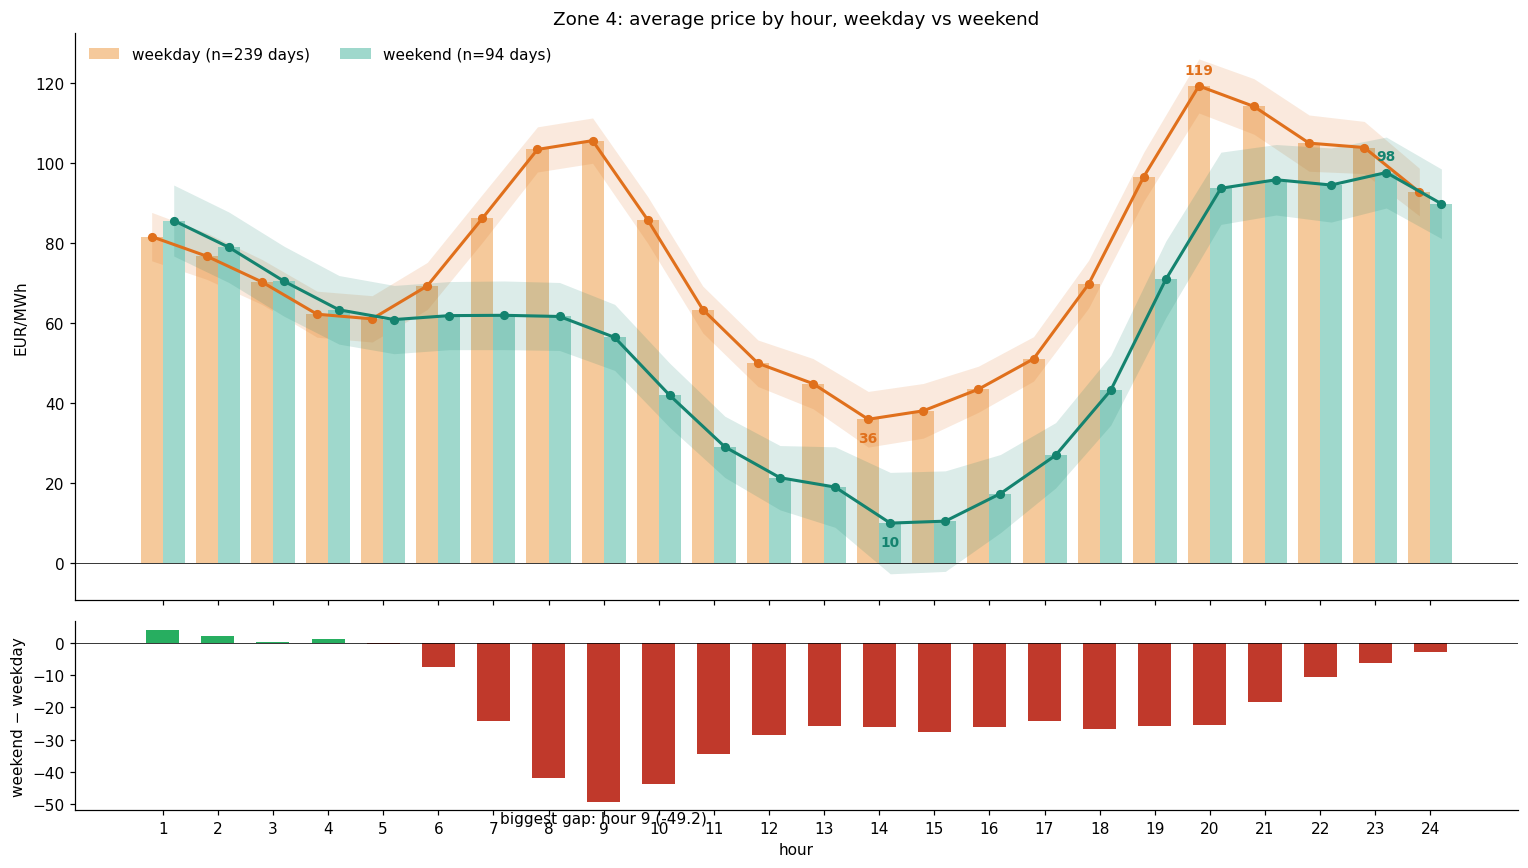

,weekday_avg,weekend_avg,weekend_vs_weekday_%,biggest_gap_hour,biggest_gap,weekday_peak_hour,weekend_peak_hour,weekday_spread,weekend_spread
market_id,,,,,,,,,
Zone 1,108.5,81.2,-25.1,9,-54.3,20,21,97.0,101.1
Zone 2,124.1,91.8,-26.0,10,-59.0,20,21,87.9,107.0
Zone 3,137.4,119.0,-13.4,16,-46.5,20,20,52.6,78.2
Zone 4,76.3,56.8,-25.5,9,-49.2,20,23,83.3,87.6


In [43]:
# ---------------------------------------------------------------------------
# B7 (E1). Weekday vs weekend: mean price by hour (one figure per zone)
# ---------------------------------------------------------------------------
WEEKDAY_BAR, WEEKDAY_LINE = '#f5c99b', '#e0701c'   # light / dark orange
WEEKEND_BAR, WEEKEND_LINE = '#9fd8cc', '#14836f'   # light / dark teal
GAP_POS, GAP_NEG = '#27ae60', '#c0392b'            # weekend higher / lower

for z in ZONES:
    hz = H[H.market_id == z]
    g = hz.groupby(['hour_index', 'day_type']).hourly_price
    t = g.mean().unstack()
    se = (g.std() / np.sqrt(g.count())).unstack()           # standard error of the mean
    n_days = hz.groupby('day_type').delivery_date.nunique()
    x = t.index.to_numpy()
    gap = t.weekend - t.weekday

    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    for col, bar_c, line_c, off in [('weekday', WEEKDAY_BAR, WEEKDAY_LINE, -0.2),
                                    ('weekend', WEEKEND_BAR, WEEKEND_LINE, +0.2)]:
        ax.bar(x + off, t[col], 0.4, color=bar_c, label=f'{col} (n={n_days[col]} days)')
        ax.plot(x + off, t[col], color=line_c, marker='o', ms=5, lw=2)
        ax.fill_between(x + off, t[col] - 1.96 * se[col], t[col] + 1.96 * se[col], color=line_c, alpha=0.15, lw=0)
        hi, lo = t[col].idxmax(), t[col].idxmin()
        ax.annotate(f'{t[col][hi]:.0f}', (hi + off, t[col][hi]), xytext=(0, 8), textcoords='offset points',
                    ha='center', color=line_c, fontsize=9, fontweight='bold')
        ax.annotate(f'{t[col][lo]:.0f}', (lo + off, t[col][lo]), xytext=(0, -15), textcoords='offset points',
                    ha='center', color=line_c, fontsize=9, fontweight='bold')
    ax.axhline(0, color='k', lw=0.5)
    ax.set(title=f'{z}: average price by hour, weekday vs weekend', ylabel='EUR/MWh')
    ax.legend(frameon=False, ncol=2)

    ax2.bar(x, gap, 0.6, color=np.where(gap >= 0, GAP_POS, GAP_NEG))
    ax2.axhline(0, color='k', lw=0.5)
    big = gap.abs().idxmax()
    ax2.annotate(f'biggest gap: hour {big} ({gap[big]:+.1f})', (big, gap[big]),
                 xytext=(0, -14 if gap[big] < 0 else 6), textcoords='offset points', ha='center', fontsize=10)
    ax2.set(xlabel='hour', ylabel='weekend − weekday', xticks=x)
    plt.tight_layout(); plt.show()

rows = []
for z in ZONES:
    t = H[H.market_id == z].groupby(['hour_index', 'day_type']).hourly_price.mean().unstack()
    gap = t.weekend - t.weekday
    big = gap.abs().idxmax()
    rows.append({'market_id': z, 'weekday_avg': t.weekday.mean(), 'weekend_avg': t.weekend.mean(),
                 'weekend_vs_weekday_%': 100 * (t.weekend.mean() / t.weekday.mean() - 1),
                 'biggest_gap_hour': big, 'biggest_gap': gap[big],
                 'weekday_peak_hour': t.weekday.idxmax(), 'weekend_peak_hour': t.weekend.idxmax(),
                 'weekday_spread': t.weekday.max() - t.weekday.min(),
                 'weekend_spread': t.weekend.max() - t.weekend.min()})
pd.DataFrame(rows).set_index('market_id').round(1)

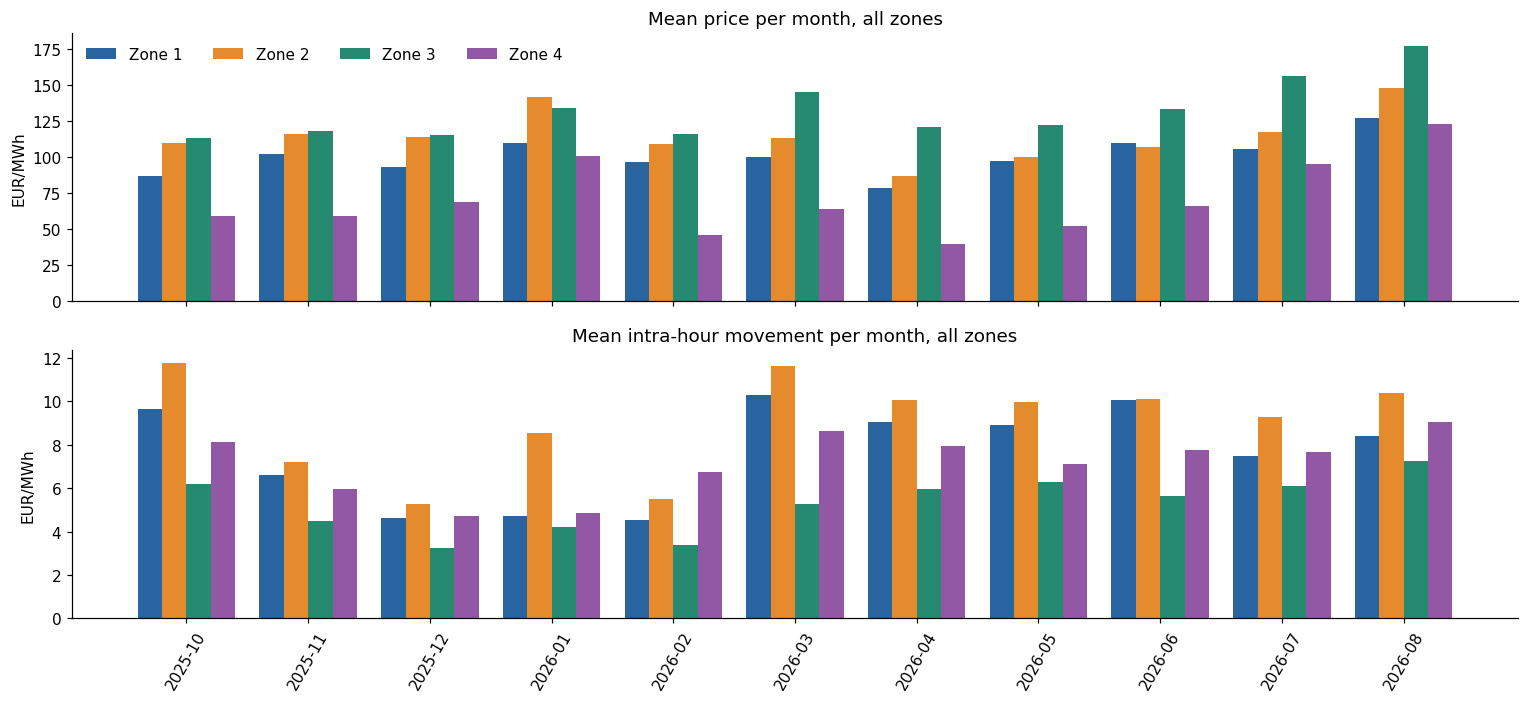

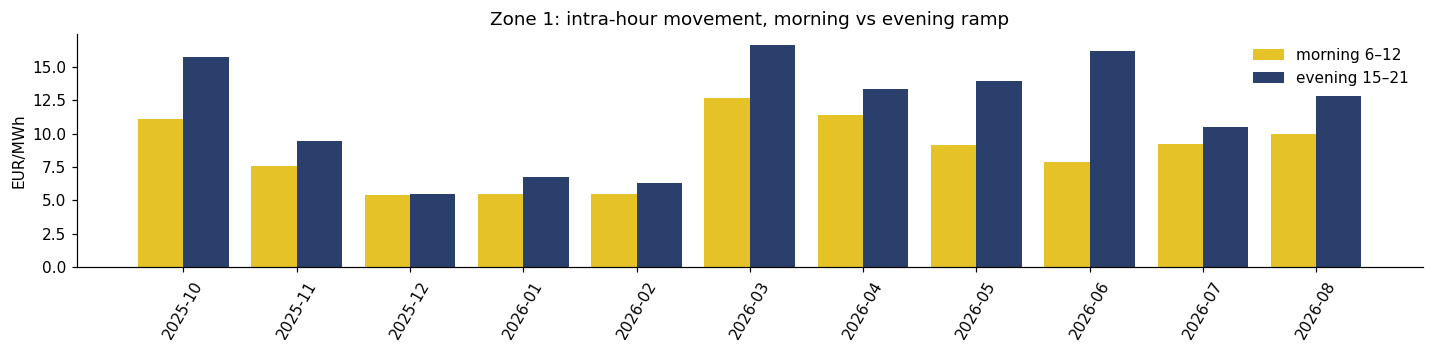

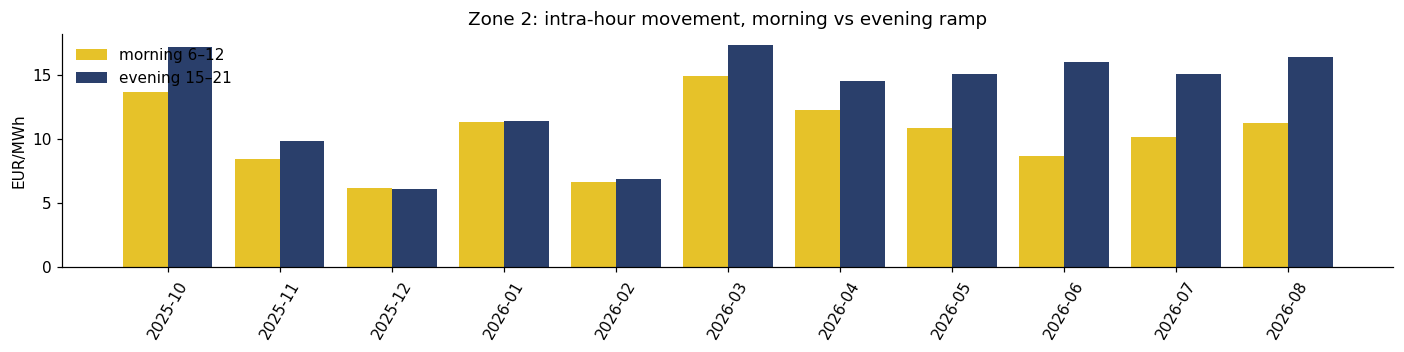

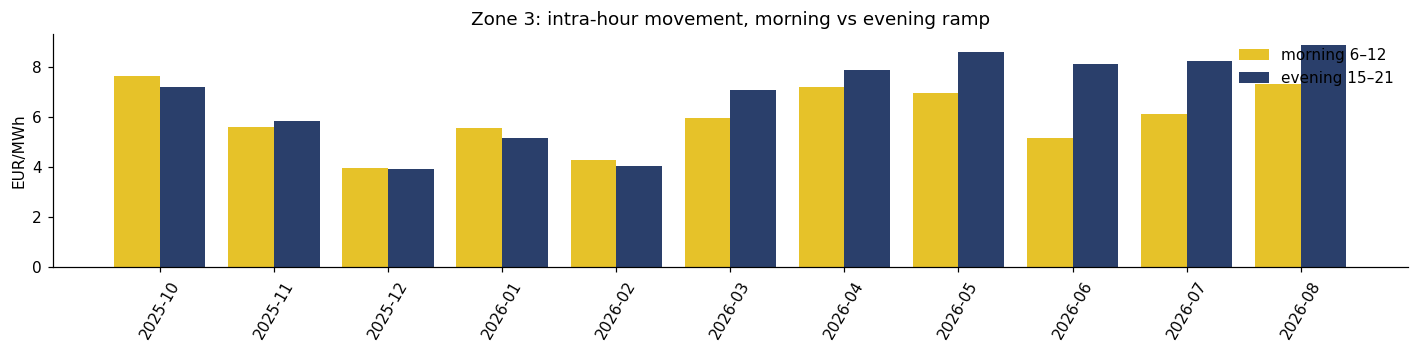

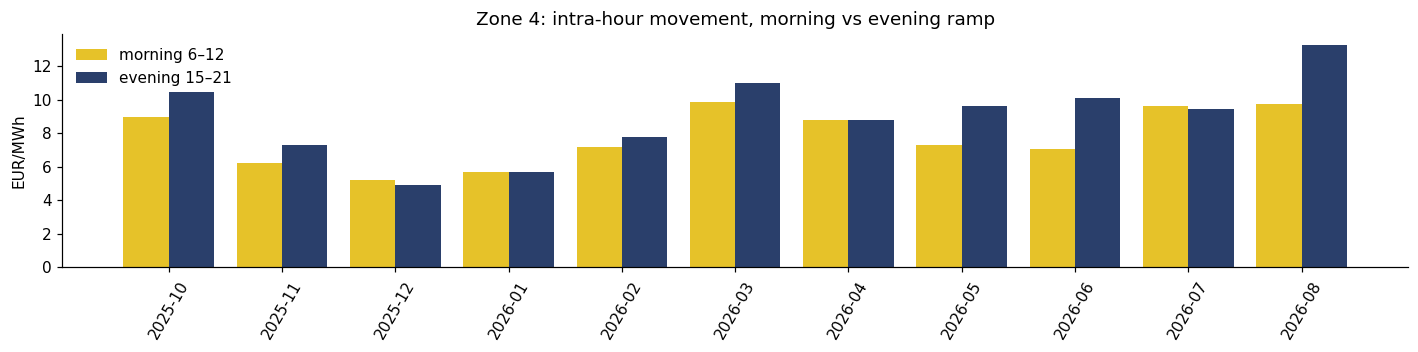

In [44]:
# ---------------------------------------------------------------------------
# B8 (E2, E3). Zones side by side per month; morning vs evening ramp per month
# ---------------------------------------------------------------------------
month_x = np.arange(len(MONTHS))
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
for k, (z, c) in enumerate(zip(ZONES, COLORS)):
    axes[0].bar(month_x + (k - 1.5) * 0.2, monthly_tbl.loc[z].mean_price.reindex(MONTHS), 0.2, color=c, label=z)
    axes[1].bar(month_x + (k - 1.5) * 0.2, monthly_tbl.loc[z].intra_hour_move.reindex(MONTHS), 0.2, color=c)
axes[0].set(title='Mean price per month, all zones', ylabel='EUR/MWh')
axes[0].legend(frameon=False, ncol=4)
axes[1].set(title='Mean intra-hour movement per month, all zones', ylabel='EUR/MWh', xticks=month_x, xticklabels=MONTHS)
axes[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()

H['ramp_window'] = np.select([H.hour_index.between(6, 12), H.hour_index.between(15, 21)],
                             ['morning 6–12', 'evening 15–21'], 'other')
for z in ZONES:
    t = (H[(H.market_id == z) & (H.ramp_window != 'other')]
           .groupby(['month', 'ramp_window']).abs_res.mean().unstack().reindex(MONTHS))
    fig, ax = plt.subplots(figsize=(13, 3.3))
    ax.bar(month_x - 0.2, t['morning 6–12'], 0.4, color='#e6c229', label='morning 6–12')
    ax.bar(month_x + 0.2, t['evening 15–21'], 0.4, color='#2a3f6b', label='evening 15–21')
    ax.set(title=f'{z}: intra-hour movement, morning vs evening ramp', ylabel='EUR/MWh', xticks=month_x, xticklabels=MONTHS)
    ax.tick_params(axis='x', rotation=60)
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()

### B9–B11. Extra market facts (from the deep-dive analysis)
Day of week, timing of the daily peak and low, and how strongly prices repeat over time.

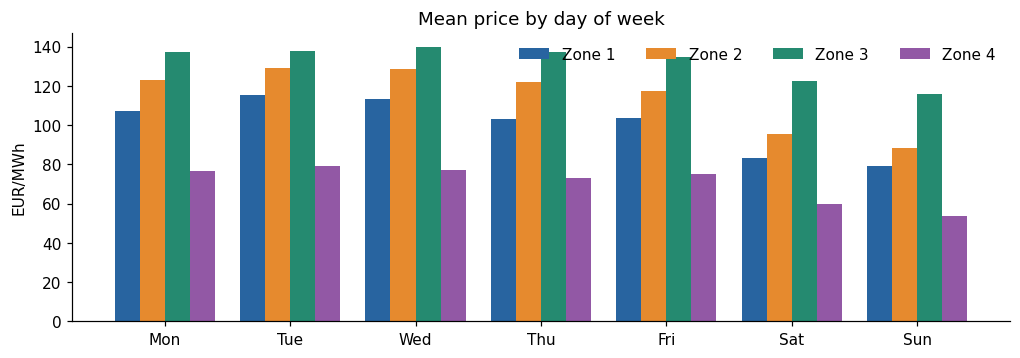

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
market_id,,,,,,,
Zone 1,107.1,115.2,113.3,103.3,103.6,83.3,79.0
Zone 2,122.8,129.2,128.6,122.2,117.6,95.3,88.3
Zone 3,137.4,137.9,139.8,137.3,134.8,122.3,115.7
Zone 4,76.6,79.3,77.3,73.2,75.0,59.7,53.7


In [45]:
# ---------------------------------------------------------------------------
# B9. Mean price by day of week, per zone
# ---------------------------------------------------------------------------
DOW = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow = (H.assign(dow=H.delivery_date.dt.dayofweek)
         .groupby(['dow', 'market_id']).hourly_price.mean().unstack())
dow.index = DOW
fig, ax = plt.subplots(figsize=(11, 3.4))
x7 = np.arange(7)
for k, (z, c) in enumerate(zip(ZONES, COLORS)):
    ax.bar(x7 + (k - 1.5) * 0.2, dow[z], 0.2, color=c, label=z)
ax.set(title='Mean price by day of week', ylabel='EUR/MWh', xticks=x7, xticklabels=DOW)
ax.legend(frameon=False, ncol=4)
plt.show()
dow.round(1).T

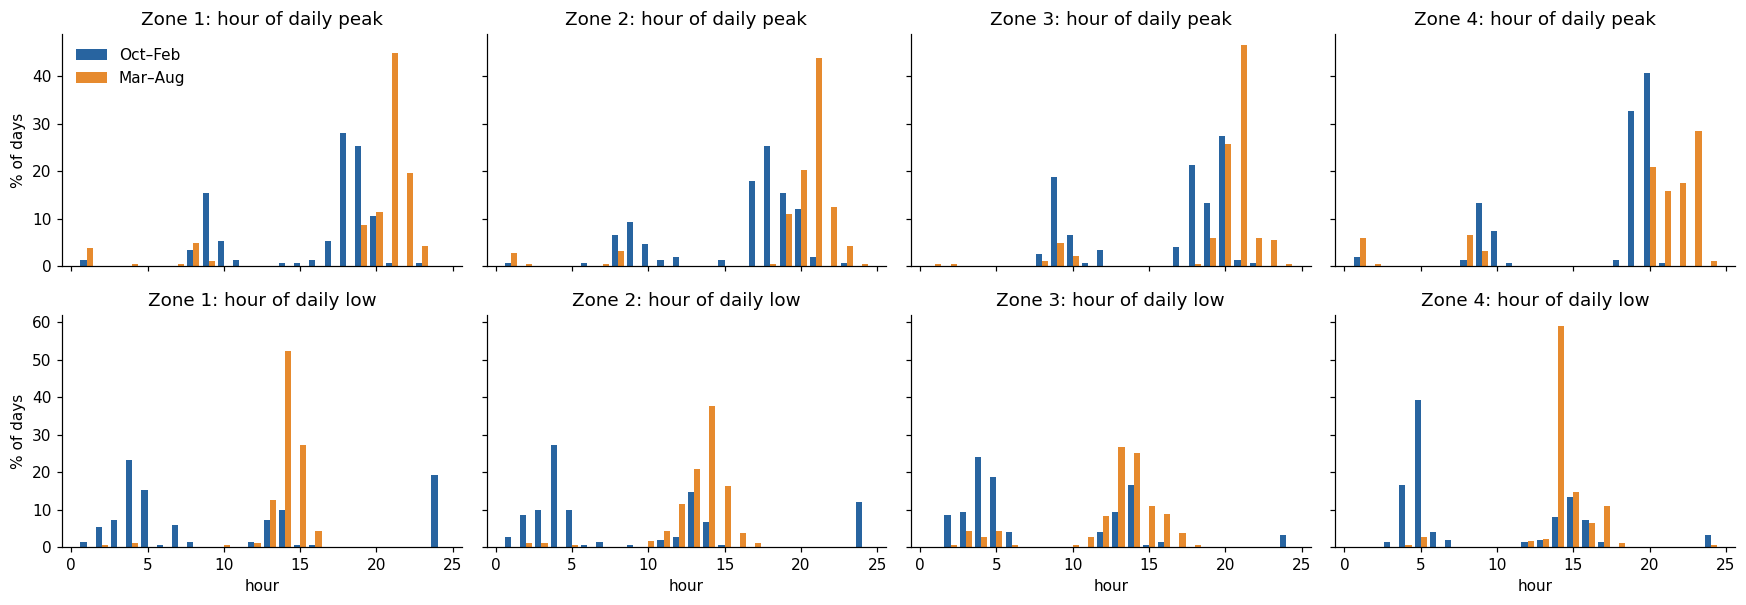

In [46]:
# ---------------------------------------------------------------------------
# B10. When does each day reach its highest and lowest hourly price?
#      Share of days per hour, split into Oct–Feb (no solar) and Mar–Aug (solar)
# ---------------------------------------------------------------------------
day_idx = H.groupby(['market_id', 'delivery_date']).hourly_price
peak = H.loc[day_idx.idxmax()]
low = H.loc[day_idx.idxmin()]
half = lambda d: np.where(d.delivery_date.dt.month.isin([10, 11, 12, 1, 2]), 'Oct–Feb', 'Mar–Aug')

fig, axes = plt.subplots(2, 4, figsize=(16, 5.6), sharex=True, sharey='row')
for row, (tbl, label) in enumerate([(peak, 'peak'), (low, 'low')]):
    t = tbl.assign(half=half(tbl))
    for ax, z in zip(axes[row], ZONES):
        counts = (t[t.market_id == z].groupby(['half', 'hour_index']).size()
                    .unstack(0).reindex(range(1, 25), fill_value=0))
        share = 100 * counts / counts.sum()
        ax.bar(share.index - 0.2, share['Oct–Feb'], 0.4, color='#2864a0', label='Oct–Feb')
        ax.bar(share.index + 0.2, share['Mar–Aug'], 0.4, color='#e68a2e', label='Mar–Aug')
        ax.set(title=f'{z}: hour of daily {label}')
    axes[row, 0].set_ylabel('% of days')
for ax in axes[1]: ax.set_xlabel('hour')
axes[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

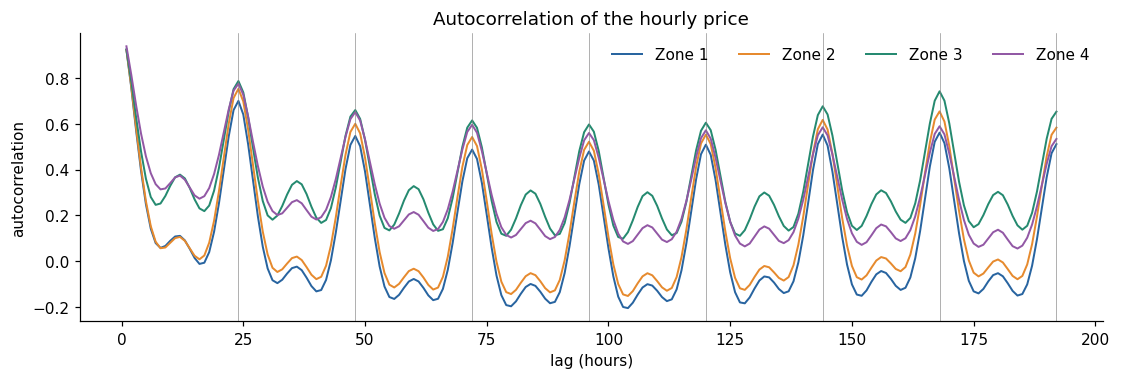

,lag 24h,lag 144h (6d),lag 168h (7d)
Zone 1,0.70,0.55,0.56
Zone 2,0.75,0.62,0.65
Zone 3,0.79,0.68,0.74
Zone 4,0.77,0.58,0.59


In [47]:
# ---------------------------------------------------------------------------
# B11. Autocorrelation of the hourly price, lags 1 h to 8 days
#      (consecutive calendar hours; the two missing DST days are left as gaps)
# ---------------------------------------------------------------------------
lags = np.arange(1, 24 * 8 + 1)
fig, ax = plt.subplots(figsize=(12, 3.4))
acf_rows = {}
for z, c in zip(ZONES, COLORS):
    s = (H[H.market_id == z].set_index(H.loc[H.market_id == z, 'delivery_date']
                                       + pd.to_timedelta(H.loc[H.market_id == z, 'hour_index'] - 1, unit='h'))
           .hourly_price.asfreq('h'))                          # regular hourly grid, NaN on DST days
    acf = [s.autocorr(l) for l in lags]
    acf_rows[z] = {'lag 24h': acf[23], 'lag 144h (6d)': acf[143], 'lag 168h (7d)': acf[167]}
    ax.plot(lags, acf, color=c, lw=1.3, label=z)
for d in range(1, 9):
    ax.axvline(24 * d, color='grey', lw=0.4)                   # day markers
ax.set(title='Autocorrelation of the hourly price', xlabel='lag (hours)', ylabel='autocorrelation')
ax.legend(frameon=False, ncol=4)
plt.show()
pd.DataFrame(acf_rows).T.round(2)

> **What we found: the price level**
>
> - **Zones move together but are not identical** (daily price correlation 0.60–0.82; Zone 1 and Zone 2 most alike). Zone 3 is the most expensive (≈ 132 EUR/MWh) and the calmest; Zone 4 the cheapest (≈ 71).
> - **Every zone shows a duck curve:** morning peak around hours 8–9, midday trough around 13–14, evening peak around 20–21. In spring and summer the trough deepens sharply with solar (cheapest hour moves to hour 14 everywhere) and the daily spread doubles to triples (Zone 1: 51 in winter → 175 in summer).
> - **The level does not follow the solar season cleanly** (it jumps in a cold January and peaks in August), but **the daily spread does**: ≈ 45–90 EUR/MWh in Nov–Feb, ≈ 100–210 from March. Intra-hour movement tracks the spread, not the level (chapter 5).
> - **The heatmaps show a midday "solar hole"** from March, deepest in April–May; intra-hour movement lights up at its edges (the morning down-ramp and evening up-ramp). June evenings (hours 19–21) are the most volatile spot in Zone 1.
> - **Weekends are cheaper** (≈ 25% in zones 1, 2 and 4; 13% in Zone 3), entirely during the working day; nights are the same.
> - **The evening ramp is the biggest source of error in every zone** (e.g. Zone 1: 11.5 evening vs 8.7 morning).
>
> **Extra market facts (B9–B11)**
> - **Day of week:** Tuesday and Wednesday are the most expensive days and Sunday the cheapest in every zone (e.g. Zone 1: 115 on Tue vs 79 on Sun). Saturday and Sunday are 20–30% below midweek; Zone 3 drops only ≈ 15%.
> - **Timing of the daily peak and low switches with the season.**
>   - Oct–Feb: the peak is at hours 18–20 (early sunset), with a second cluster at hour 9; the low is at night (hours 3–5) or at hour 24.
>   - Mar–Aug: the peak moves to hour 21 (≈ 45% of days in zones 1–3; hours 20–23 in Zone 4) and the low moves to the solar midday, hours 13–15 (hour 14 on ≈ 59% of days in Zone 4).
> - **Prices repeat daily and weekly:** the autocorrelation at 24 h is 0.70–0.79. A weekly bump at 168 h (vs 144 h) is clear in Zone 3 (0.74 vs 0.68) and Zone 2 (0.65 vs 0.62), but barely visible in zones 1 and 4. Zone 3 is the most persistent zone.

---
# Appendix C. The 15-day window for the other zones

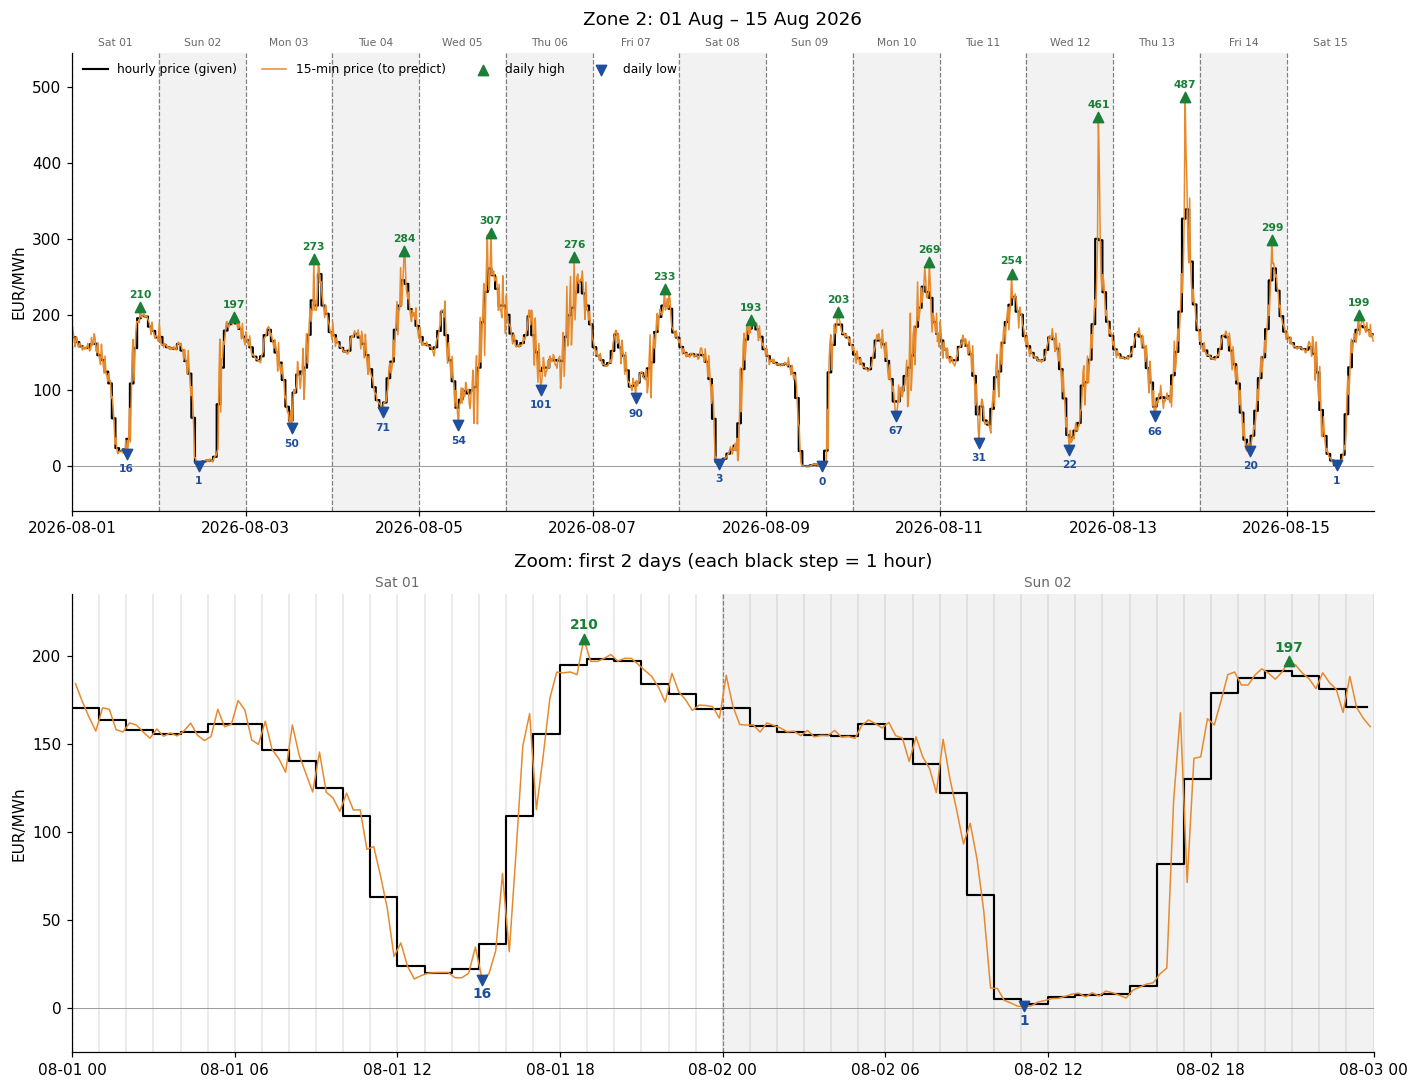

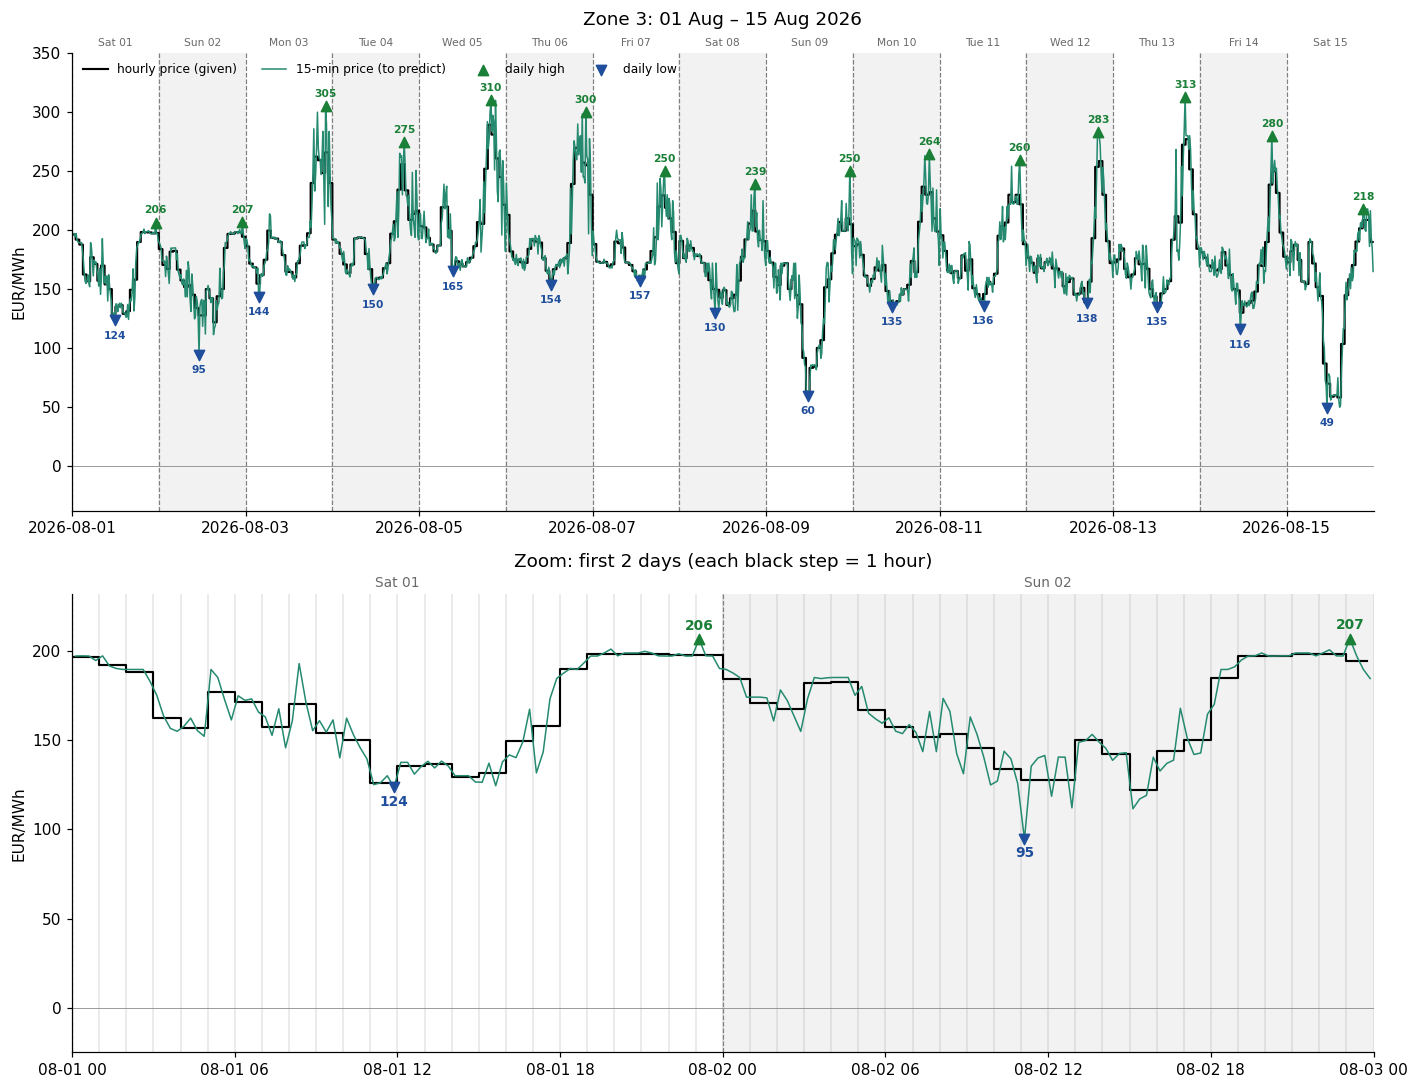

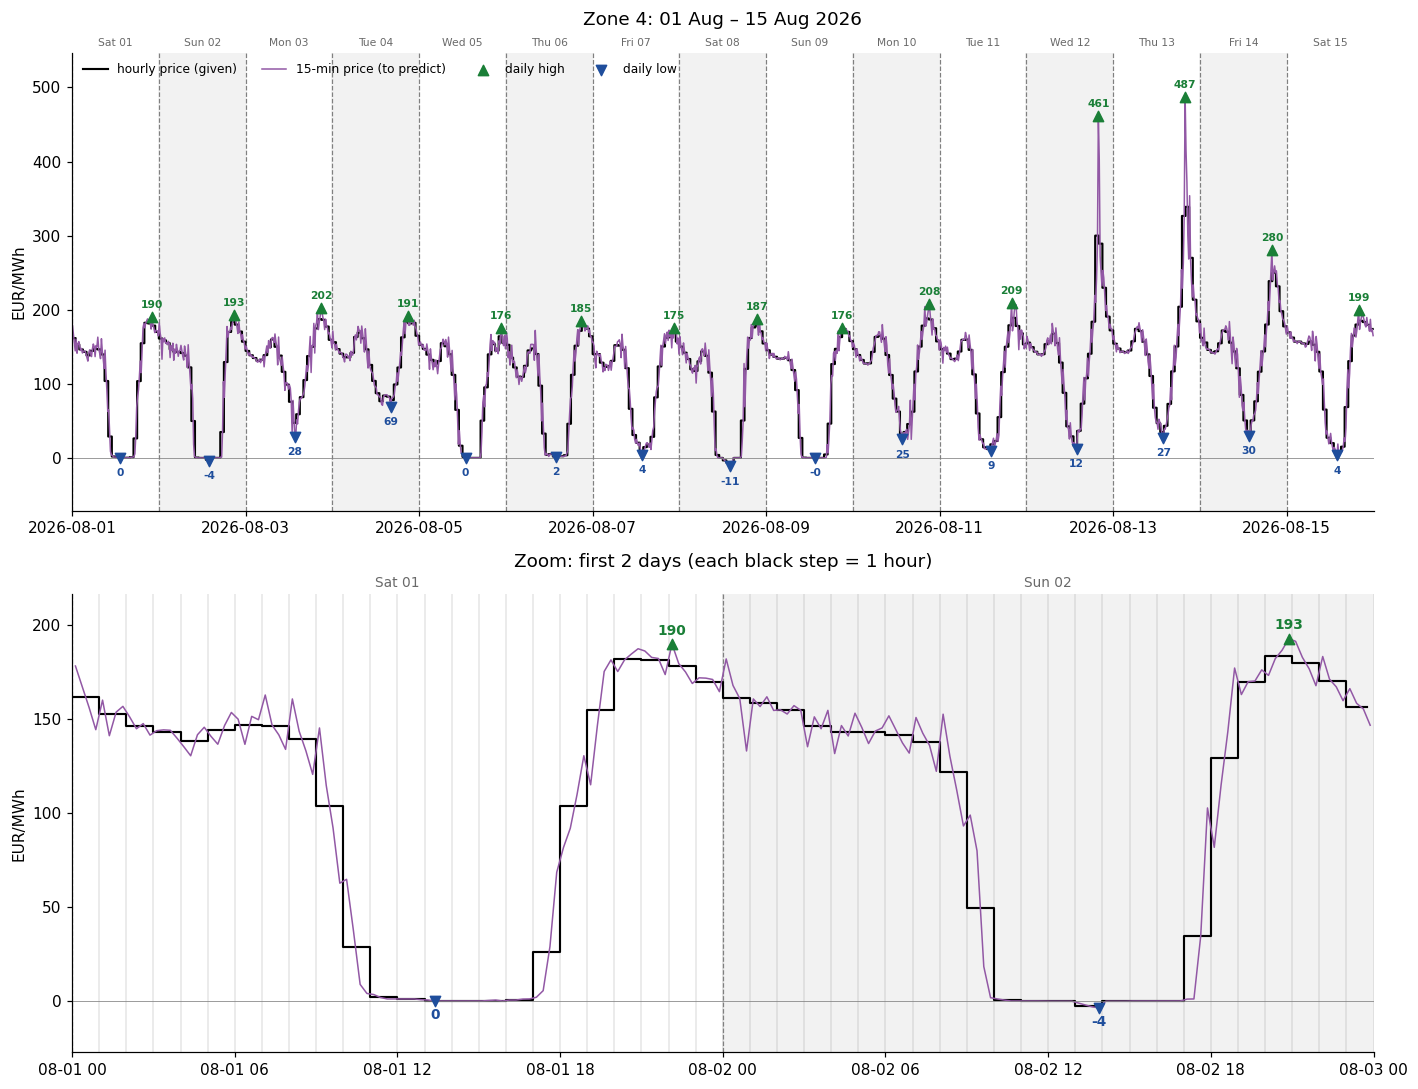

In [48]:
for z, c in zip(ZONES[1:], COLORS[1:]):
    plot_window(z, c)

---
# Appendix D. More shape details

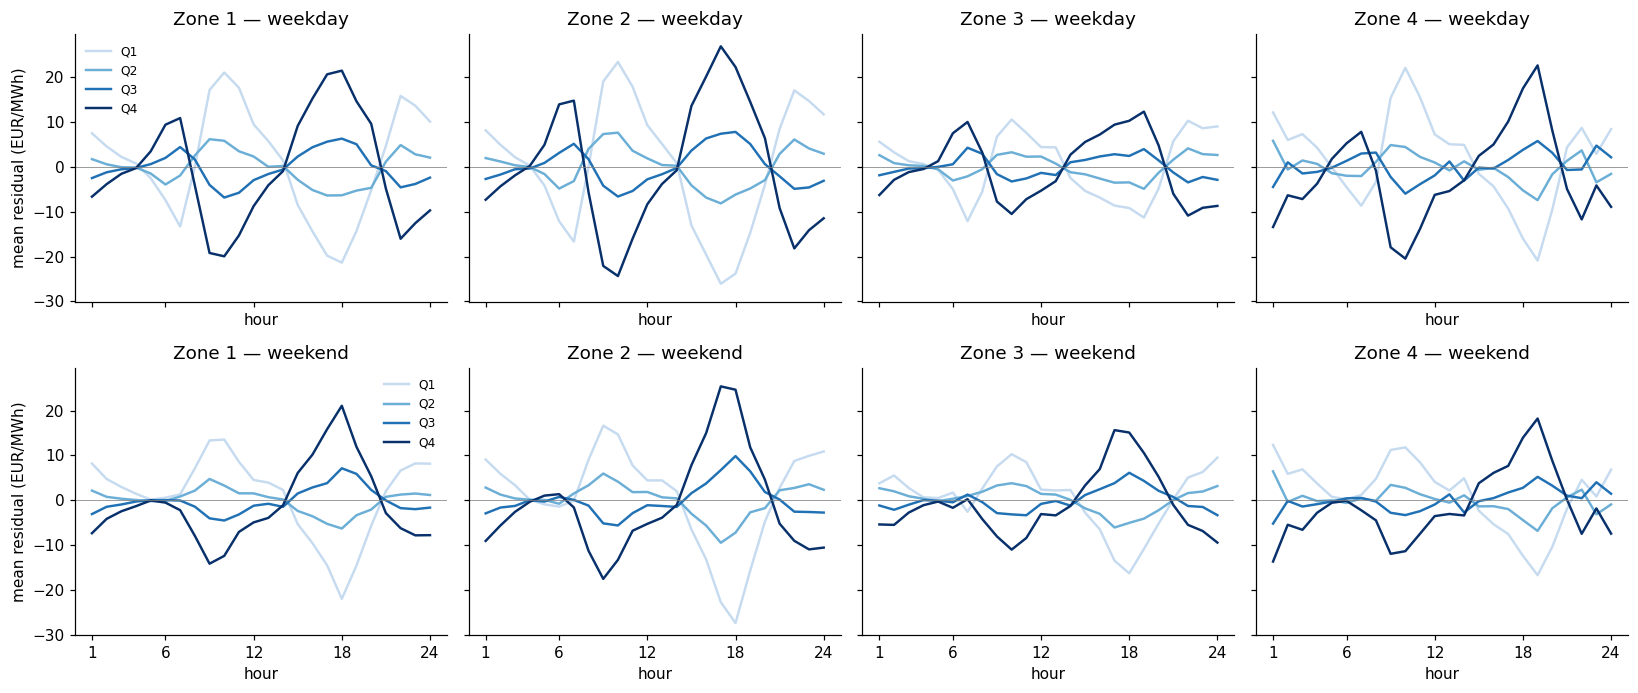

In [49]:
# ---------------------------------------------------------------------------
# D1. Average shape: weekday (top) vs weekend (bottom)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharey=True, sharex=True)
quarter_lines(df[df.day_type == 'weekday'], axes=axes[0])
quarter_lines(df[df.day_type == 'weekend'], axes=axes[1])
for ax in axes[0]: ax.set_title(ax.get_title() + ' — weekday')
for ax in axes[1]: ax.set_title(ax.get_title() + ' — weekend')
plt.tight_layout(); plt.show()

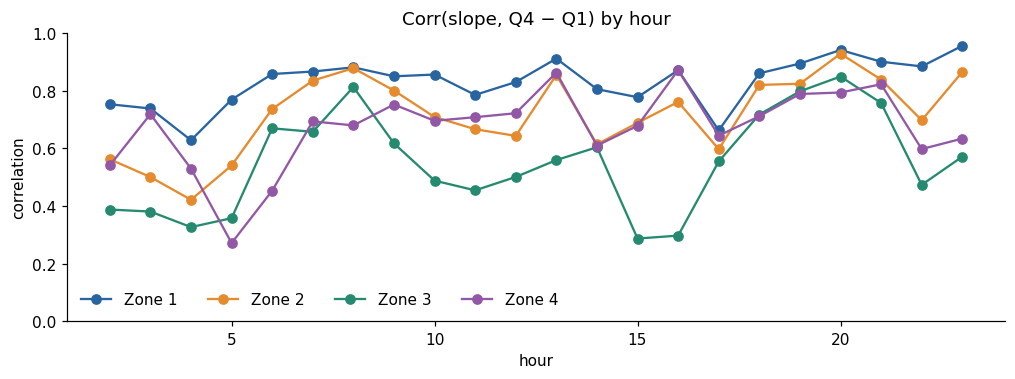

In [50]:
# ---------------------------------------------------------------------------
# D2. Where does the slope work best? Corr(slope, Q4 − Q1) by hour
# ---------------------------------------------------------------------------
slope_corr_by_hour = (S.groupby(['hour_index', 'market_id'])[['slope', 'q4_minus_q1']]
                        .apply(lambda p: p.slope.corr(p.q4_minus_q1)).unstack())
ax = slope_corr_by_hour.plot(figsize=(11, 3.4), color=COLORS, marker='o')
ax.set(title='Corr(slope, Q4 − Q1) by hour', xlabel='hour', ylabel='correlation', ylim=(0, 1))
ax.legend(ncol=4, frameon=False)
plt.show()

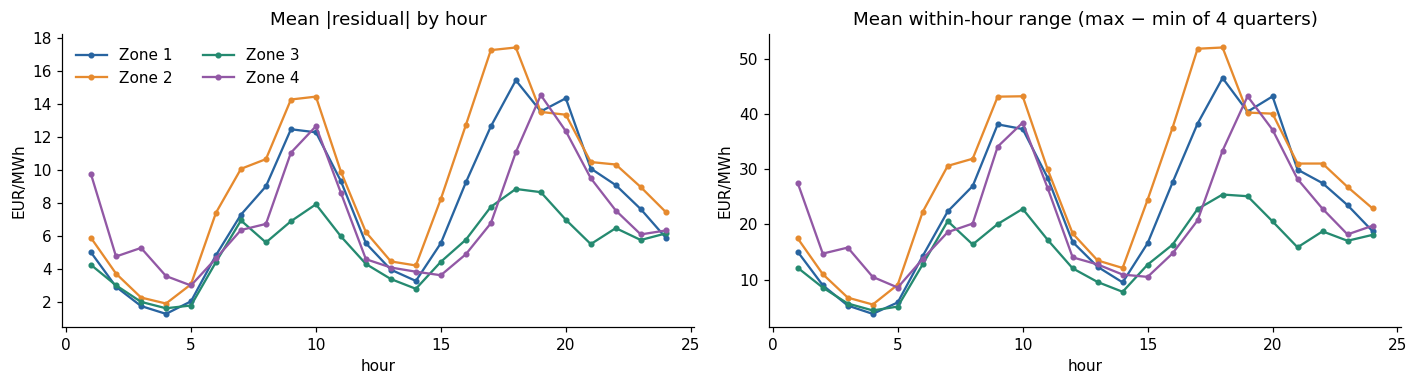

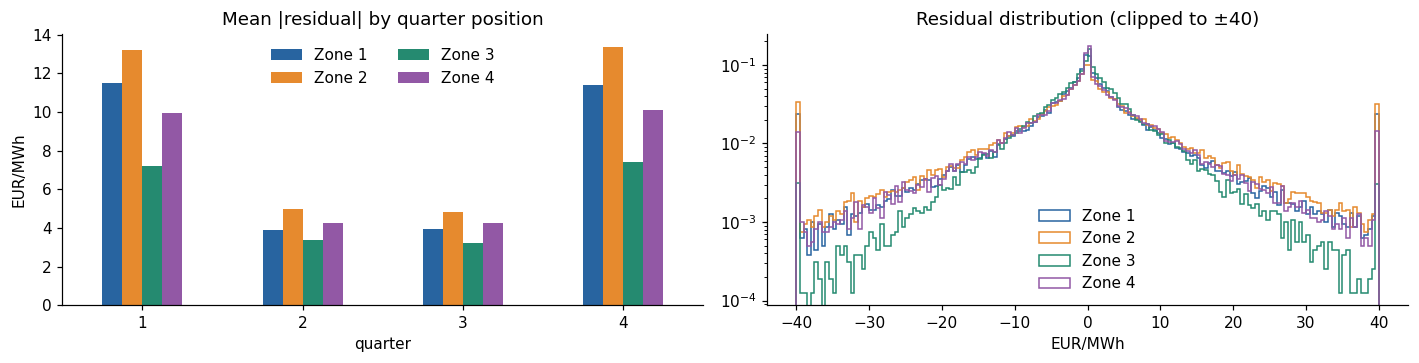

Top-3 hours with the biggest swings per zone:


mean |residual|
market_id hour_index                 
Zone 1    18                    15.42
          20                    14.33
          19                    13.54
Zone 2    18                    17.41
          17                    17.25
          10                    14.43
Zone 3    18                     8.84
          19                     8.64
          10                     7.91
Zone 4    19                    14.52
          10                    12.64
          20                    12.34

In [51]:
# ---------------------------------------------------------------------------
# D3. Residual size by hour, by quarter position, and its distribution
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
H.groupby(['hour_index', 'market_id']).abs_res.mean().unstack().plot(ax=axes[0], color=COLORS, marker='.')
axes[0].set(title='Mean |residual| by hour', xlabel='hour', ylabel='EUR/MWh')
axes[0].legend(ncol=2, frameon=False)
H.groupby(['hour_index', 'market_id'])['range'].mean().unstack().plot(ax=axes[1], color=COLORS, marker='.', legend=False)
axes[1].set(title='Mean within-hour range (max − min of 4 quarters)', xlabel='hour', ylabel='EUR/MWh')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
df.groupby(['quarter_index', 'market_id']).abs_res.mean().unstack().plot.bar(ax=axes[0], color=COLORS, rot=0)
axes[0].set(title='Mean |residual| by quarter position', xlabel='quarter', ylabel='EUR/MWh')
axes[0].legend(ncol=2, frameon=False)
for z, c in zip(ZONES, COLORS):
    r = df.loc[df.market_id == z, 'residual']
    axes[1].hist(r.clip(-40, 40), bins=160, histtype='step', color=c, label=z, density=True)
axes[1].set(title='Residual distribution (clipped to ±40)', xlabel='EUR/MWh', yscale='log')
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

print('Top-3 hours with the biggest swings per zone:')
H.groupby(['market_id', 'hour_index']).abs_res.mean().groupby('market_id').nlargest(3).droplevel(0).rename(
    'mean |residual|').to_frame().round(2)

In [52]:
# ---------------------------------------------------------------------------
# D4. Sawtooth across hours: how often does the price jump back at the boundary?
# ---------------------------------------------------------------------------
day_hours = H.groupby(['delivery_date', 'market_id'])
next_q1_price = day_hours.hourly_price.shift(-1) + day_hours.r1.shift(-1)   # Q1 of the next hour
this_q4_price = H.hourly_price + H.r4                                       # Q4 of this hour
jump = next_q1_price - this_q4_price
ramp = H.r4 - H.r1
valid = jump.notna() & (ramp != 0)
resets = (np.sign(jump) == -np.sign(ramp))[valid]
display(resets.groupby(H.market_id[valid]).mean().mul(100).rename('% boundaries that reset against the ramp').to_frame().round(1))

is_zigzag = H.pattern == 'zigzag'
print('Kind of zigzag, % of zigzag hours:')
pd.crosstab(H.loc[is_zigzag, 'market_id'], H.loc[is_zigzag, 'zigzag_kind'], normalize='index').mul(100).round(1)

,% boundaries that reset against the ramp
market_id,
Zone 1,78.3
Zone 2,81.5
Zone 3,70.0
Zone 4,68.8


Kind of zigzag, % of zigzag hours:


zigzag_kind,down-up-down,up-down-up
market_id,,
Zone 1,73.5,26.5
Zone 2,60.4,39.6
Zone 3,57.2,42.8
Zone 4,72.5,27.5


Correlation of residuals between zones at the same quarter (day-to-day co-movement):


market_id,Zone 1,Zone 2,Zone 3,Zone 4
market_id,,,,
Zone 1,1.00,0.85,0.58,0.56
Zone 2,0.85,1.00,0.61,0.51
Zone 3,0.58,0.61,1.00,0.45
Zone 4,0.56,0.51,0.45,1.00


Correlation of the average 96-quarter shape between zones (typical shape):


market_id,Zone 1,Zone 2,Zone 3,Zone 4
market_id,,,,
Zone 1,1.00,0.99,0.96,0.89
Zone 2,0.99,1.00,0.95,0.85
Zone 3,0.96,0.95,1.00,0.88
Zone 4,0.89,0.85,0.88,1.00


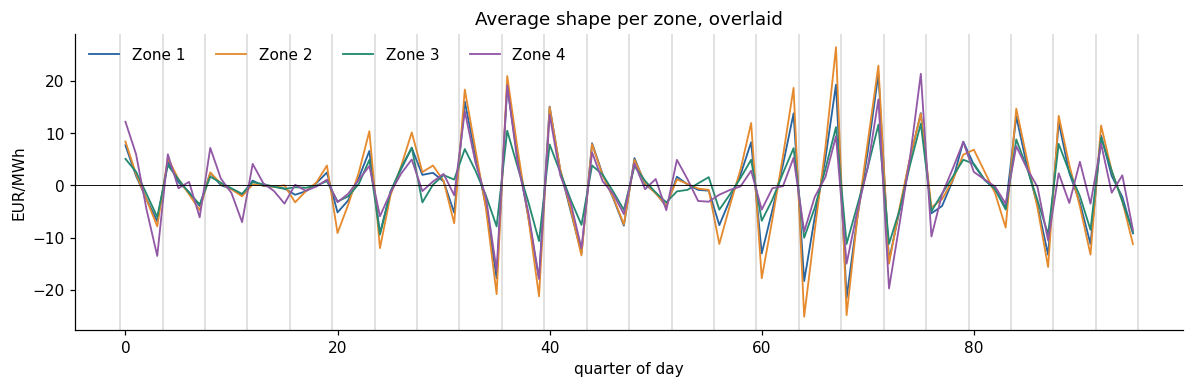

In [53]:
# ---------------------------------------------------------------------------
# D5. Zones: co-movement, typical shape similarity, overlaid shapes
# ---------------------------------------------------------------------------
by_zone = df.pivot_table(index=['delivery_date', 'hour_index', 'quarter_index'], columns='market_id', values='residual')
print('Correlation of residuals between zones at the same quarter (day-to-day co-movement):')
display(by_zone.corr().round(2))
print('Correlation of the average 96-quarter shape between zones (typical shape):')
display(profile_96.corr().round(2))

fig, ax = plt.subplots(figsize=(13, 3.5))
for z, c in zip(ZONES, COLORS):
    ax.plot(avg_shape[z].unstack().to_numpy().ravel(), color=c, lw=1.2, label=z)
for h in range(0, 97, 4):
    ax.axvline(h - 0.5, color='grey', lw=0.3)
ax.axhline(0, color='k', lw=0.6)
ax.set(title='Average shape per zone, overlaid', xlabel='quarter of day', ylabel='EUR/MWh')
ax.legend(ncol=4, frameon=False)
plt.show()

> **What we found: shape details**
>
> - **Weekend shapes have the same timing as weekday shapes, only smaller.**
> - **The slope works best on the ramps** (hours 6–13 and 18–21, r ≈ 0.8–0.95) and worst at night (hours 2–5) and, for Zone 3, at hours 15–16 (r ≈ 0.3), where shapes are small or noisy.
> - **The biggest swings are on the evening up-ramp (hours 17–20) and at hour 10**, and the residual distribution has heavy tails.
> - **The sawtooth is confirmed across hours:** at 69–81% of hour boundaries the price jumps back against the previous hour's ramp. Down-up-down zigzags are more common than up-down-up (57–74%).
> - **Typical shapes are nearly identical across zones** (correlation 0.85–0.99), but day-to-day co-movement is weaker: Zone 1 and Zone 2 move together (0.85), other pairs only 0.45–0.61. One pooled model with zone-specific parameters fits this best.